<a href="https://www.kaggle.com/code/youseftahoon213/team112-notebook?scriptVersionId=359515074" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Formula 1 Podium Prediction Companion

Predict whether a driver will finish on the podium using information available
after qualifying and before the race starts. One prediction represents one
driver entering one race; the target is `positionOrder <= 3`.

The notebook follows the milestone: **1. Cleaning and auditing; 2. Three
data-engineering questions; 3. Feature engineering; 4. Modeling; 5. Experiments;
6. Explainability.** Final test evaluation follows the experiments, once choices
are fixed. Inference examples then demonstrate the selected model.

Fourteen linked CSVs provide entries, drivers, constructors, circuits, races,
standings, qualifying, timing and status information. Raw files remain unchanged.
Historical constructor conflicts and flagged lap/timing records are documented
limitations awaiting TA guidance.

## Setup and data loading

Locally, run from the project folder containing `F1 Data`, or set `F1_DATA_DIR`.
On Kaggle, attach the dataset; the loading cell finds its CSV folder.
The literal `\N` is loaded as missing. Cleaning uses DataFrame copies.

In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import time as clock_time

In [2]:
# Folder containing the CSV files
data_folder = Path(os.environ.get("F1_DATA_DIR", "F1 Data"))

# Find the attached CSV folder when running on Kaggle
if not (data_folder / "results.csv").exists() and Path("/kaggle/input").exists():
    data_folder = next(
        (path.parent for path in sorted(Path("/kaggle/input").rglob("results.csv"))
         if (path.parent / "qualifying.csv").exists()),
        data_folder
    )

if not (data_folder / "results.csv").exists():
    raise FileNotFoundError("Attach the F1 CSVs or set F1_DATA_DIR to their folder.")

# Read each CSV separately
circuits = pd.read_csv(data_folder / "circuits.csv", na_values=[r"\N"])
constructors = pd.read_csv(data_folder / "constructors.csv", na_values=[r"\N"])
constructor_results = pd.read_csv(data_folder / "constructor_results.csv", na_values=[r"\N"])
constructor_standings = pd.read_csv(data_folder / "constructor_standings.csv", na_values=[r"\N"])

drivers = pd.read_csv(data_folder / "drivers.csv", na_values=[r"\N"])
driver_standings = pd.read_csv(data_folder / "driver_standings.csv", na_values=[r"\N"])

races = pd.read_csv(data_folder / "races.csv", na_values=[r"\N"])
results = pd.read_csv(data_folder / "results.csv", na_values=[r"\N"])
qualifying = pd.read_csv(data_folder / "qualifying.csv", na_values=[r"\N"])

lap_times = pd.read_csv(data_folder / "lap_times.csv", na_values=[r"\N"])
pit_stops = pd.read_csv(data_folder / "pit_stops.csv", na_values=[r"\N"])
sprint_results = pd.read_csv(data_folder / "sprint_results.csv", na_values=[r"\N"])

seasons = pd.read_csv(data_folder / "seasons.csv", na_values=[r"\N"])
status = pd.read_csv(data_folder / "status.csv", na_values=[r"\N"])

The small helper below shows the same before/after comparison for each file. A dash means a column is absent, not that its values are missing.

In [3]:
def compare_cleaning(before, after):
    print(f"Rows: {len(before):,} → {len(after):,}")
    print(f"Columns: {before.shape[1]} → {after.shape[1]}")
    display(pd.DataFrame({
        "Type before": before.dtypes.astype(str),
        "Type after": after.dtypes.astype(str),
        "Missing before": before.isna().sum(),
        "Missing after": after.isna().sum()
    }).fillna("—"))

## 1. Results
Each row is a recorded race entry. Check IDs, missing values and historical repeated driver–race entries before creating the separate outcome table.

### Inspect

In [4]:
# Keep the original results unchanged
results_clean = results.copy()

display(results.head())

print("Number of rows:", results.shape[0])
print("Number of columns:", results.shape[1])

results.info()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1


Number of rows: 26759
Number of columns: 18
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26753 non-null  float64
 5   grid             26759 non-null  int64  
 6   position         15806 non-null  float64
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             7680 non-null   object 
 12  milliseconds     7680 non-null   float64
 13  fastestLap       8252 non-null   float64
 14  rank             8510 non-null   float64
 15  fastestLapTime   8252 non-null   object 
 16  fastestLapSpee

In [5]:
# Count missing values in each column
missing_count = results_clean.isna().sum()

# Calculate the percentage missing in each column
missing_percentage = missing_count / len(results_clean) * 100

# Put both into one table
missing_summary = pd.DataFrame({
    "Missing count": missing_count,
    "Missing percentage": missing_percentage.round(2)
})

display(missing_summary)

# Every result must have an ID
print("Missing result IDs:", results_clean["resultId"].isna().sum())

# Each result ID must appear only once
print("Repeated result IDs:", results_clean["resultId"].duplicated().sum())

# Check race IDs
print(
    "Unknown races:",
    (~results_clean["raceId"].isin(races["raceId"])).sum()
)

# Check driver IDs
print(
    "Unknown drivers:",
    (~results_clean["driverId"].isin(drivers["driverId"])).sum()
)

# Check team IDs
print(
    "Unknown teams:",
    (~results_clean["constructorId"].isin(constructors["constructorId"])).sum()
)

# Check status IDs
print(
    "Unknown statuses:",
    (~results_clean["statusId"].isin(status["statusId"])).sum()
)

,Missing count,Missing percentage
resultId,0,0.00
raceId,0,0.00
driverId,0,0.00
constructorId,0,0.00
number,6,0.02
grid,0,0.00
position,10953,40.93
positionText,0,0.00
positionOrder,0,0.00
points,0,0.00


Missing result IDs: 0
Repeated result IDs: 0
Unknown races: 0
Unknown drivers: 0
Unknown teams: 0
Unknown statuses: 0


,grid,positionOrder,points,laps
count,26759.000000,26759.000000,26759.000000,26759.000000
mean,11.134796,12.794051,1.987632,46.301768
std,7.202860,7.665951,4.351209,29.496557
min,0.000000,1.000000,0.000000,0.000000
25%,5.000000,6.000000,0.000000,23.000000
50%,11.000000,12.000000,0.000000,53.000000
75%,17.000000,18.000000,2.000000,66.000000
max,34.000000,39.000000,50.000000,200.000000


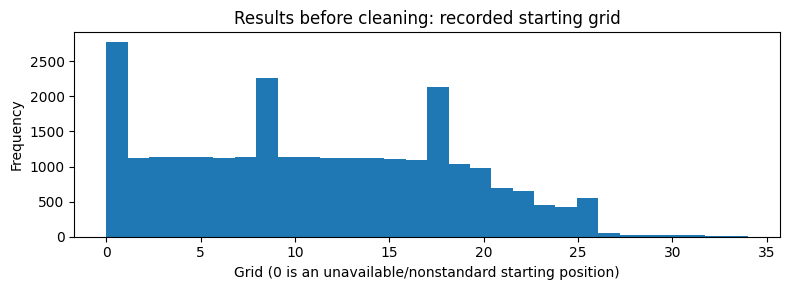

In [6]:
display(results[["grid", "positionOrder", "points", "laps"]].describe())
results["grid"].plot.hist(bins=30, figsize=(8, 3))
plt.title("Results before cleaning: recorded starting grid")
plt.xlabel("Grid (0 is an unavailable/nonstandard starting position)")
plt.tight_layout()
plt.show()

### Clean types and supported missing values
Check zero fastest-lap ranks before treating them as missing. Recover a missing position only when numeric `positionText` agrees with `positionOrder`; keep other missing values.

In [7]:
# Find rows where fastest-lap rank is zero
zero_rank = results_clean["rank"] == 0

# Check whether these rows contain any fastest-lap details
display(results_clean.loc[
    zero_rank,
    ["fastestLap", "fastestLapTime", "fastestLapSpeed"]
].notna().sum())

fastestLap         0
fastestLapTime     0
fastestLapSpeed    0
dtype: int64

In [8]:
# Replace the unrecorded rank marker with a missing value
results_clean.loc[zero_rank, "rank"] = float("nan")

# Convert numeric position text into numbers
# Letter codes such as R or W become missing
position_from_text = pd.to_numeric(
    results_clean["positionText"],
    errors="coerce"
)

# Select only missing positions supported by both other columns
recover_position = (
    results_clean["position"].isna()
    & position_from_text.notna()
    & (position_from_text == results_clean["positionOrder"])
)

# Inspect the rows before changing them
display(results_clean.loc[
    recover_position,
    ["resultId", "position", "positionText", "positionOrder"]
])

,resultId,position,positionText,positionOrder
1148,1149,NaN,11,11
1151,1152,NaN,14,14


In [9]:
results_clean.loc[recover_position, "position"] = (
    position_from_text[recover_position]
)

# Convert columns that should be whole numbers into nullable integers
whole_number_columns = [
    "number",
    "position",
    "milliseconds",
    "fastestLap",
    "rank"
]

for column in whole_number_columns:
    results_clean[column] = results_clean[column].astype("Int64")

Convert durations to seconds. Keep reported elapsed time separate from text beginning with `+`, which represents a gap. The original timing fields remain available.

In [10]:
def convert_to_seconds(value):
    # Keep missing values missing
    if pd.isna(value):
        return float("nan")

    # Remove a leading + and split the time into parts
    parts = str(value).lstrip("+").split(":")

    total_seconds = 0

    for part in parts:
        total_seconds = total_seconds * 60 + float(part)

    return total_seconds

In [11]:
results_clean["fastest_lap_seconds"] = (
    results_clean["fastestLapTime"].apply(convert_to_seconds)
)

display(results_clean[
    ["fastestLapTime", "fastest_lap_seconds"]
].head())

# Convert the recorded time values
time_seconds = results_clean["time"].apply(convert_to_seconds)

# Identify values starting with +
is_gap = results_clean["time"].str.startswith("+", na=False)

# Store the two meanings separately
results_clean["reported_elapsed_seconds"] = time_seconds.where(~is_gap)
results_clean["reported_gap_seconds"] = time_seconds.where(is_gap)

display(results_clean[
    ["time", "reported_elapsed_seconds", "reported_gap_seconds"]
].head())

,fastestLapTime,fastest_lap_seconds
0,1:27.452,87.452
1,1:27.739,87.739
2,1:28.090,88.090
3,1:28.603,88.603
4,1:27.418,87.418


,time,reported_elapsed_seconds,reported_gap_seconds
0,1:34:50.616,5690.616,NaN
1,+5.478,NaN,5.478
2,+8.163,NaN,8.163
3,+17.181,NaN,17.181
4,+18.014,NaN,18.014


### Review unusual records
Flags identify records to inspect; they do not justify deleting a row. Position and finishing-order differences are retained because the fields have different meanings.

In [12]:
results_review = results_clean[
    ["resultId", "raceId", "driverId"]
].copy()

# Grid zero has several possible meanings
results_review["grid_zero"] = results_clean["grid"] == 0

# A fastest-lap number greater than recorded completed laps
results_review["lap_values_need_review"] = (
    results_clean["fastestLap"] > results_clean["laps"]
).fillna(False)

# These two position columns do not always mean the same thing
results_review["positions_differ"] = (
    results_clean["position"].notna()
    & (results_clean["position"] != results_clean["positionOrder"])
).fillna(False)

# The first-ranked result normally should not contain a gap-style time
winner_has_gap = (
    (results_clean["positionOrder"] == 1)
    & is_gap
)

# Compare elapsed-time text with its recorded milliseconds
timing_difference = (
    results_clean["reported_elapsed_seconds"]
    - results_clean["milliseconds"] / 1000
).abs()

timing_mismatch = (timing_difference > 0.01).fillna(False)

# Flag races containing either timing issue
suspect_races = results_clean.loc[
    winner_has_gap | timing_mismatch,
    "raceId"
].unique()

results_review["timing_needs_review"] = (
    results_clean["raceId"].isin(suspect_races)
)

display(results_review[
    [
        "grid_zero",
        "lap_values_need_review",
        "positions_differ",
        "timing_needs_review"
    ]
].sum())

grid_zero                 1638
lap_values_need_review      12
positions_differ            13
timing_needs_review         20
dtype: Int64

In [13]:
# Preserve the original grid column.
# In the analysis version, keep only positive starting positions.
results_clean["grid_for_analysis"] = results_clean["grid"].where(
    results_clean["grid"] > 0
).astype("Int64")

# Check the affected records
display(results_clean.loc[
    results_review["grid_zero"],
    ["resultId", "raceId", "driverId", "grid", "grid_for_analysis"]
].head())

,resultId,raceId,driverId,grid,grid_for_analysis
2281,2282,127,62,0,<NA>
2432,2433,134,49,0,<NA>
2433,2434,134,59,0,<NA>
2434,2435,134,21,0,<NA>
2797,2798,151,58,0,<NA>


In [14]:
# Select the records with questionable lap numbers
lap_review = results_clean.loc[
    results_review["lap_values_need_review"],
    [
        "resultId", "raceId", "driverId",
        "laps", "fastestLap", "fastestLapTime", "statusId"
    ]
].copy()

# Add the explanation of how the driver's race ended
lap_review = lap_review.merge(
    status,
    on="statusId",
    how="left",
    validate="many_to_one"
)

display(lap_review)

,resultId,raceId,driverId,laps,fastestLap,fastestLapTime,statusId,status
0,185,26,21,16,21,1:34.930,20,Spun off
1,22143,900,824,49,55,1:35.635,18,+8 Laps
2,22145,900,813,29,30,1:34.766,132,ERS
3,22147,900,20,3,26,1:37.064,5,Engine
4,22149,900,13,0,2,1:40.287,4,Collision
5,24059,1002,817,23,46,1:25.692,5,Engine
6,24060,1002,4,9,18,1:25.229,5,Engine
7,24061,1002,843,0,6,1:27.009,23,Brakes
8,24138,1006,817,8,49,1:40.433,84,Battery
9,24139,1006,154,2,12,1:41.982,130,Collision damage


In [15]:
timing_review = results_clean.loc[
    results_review["timing_needs_review"],
    ["resultId", "raceId", "driverId", "positionOrder", "time", "milliseconds",
     "reported_elapsed_seconds", "reported_gap_seconds"]
].copy()
timing_review["milliseconds_as_seconds"] = timing_review["milliseconds"] / 1000
display(timing_review.sort_values(["raceId", "positionOrder"]))

,resultId,raceId,driverId,positionOrder,time,milliseconds,reported_elapsed_seconds,reported_gap_seconds,milliseconds_as_seconds
26539,26545,1134,1,1,+0.526,526,NaN,0.526,0.526
26540,26546,1134,857,2,+1.173,1699,NaN,1.173,1.699
26541,26547,1134,844,3,+8.549,9075,NaN,8.549,9.075
26542,26548,1134,830,4,+9.226,9752,NaN,9.226,9.752
26543,26549,1134,846,5,+9.850,10376,NaN,9.850,10.376
26544,26550,1134,832,6,+19.795,20321,NaN,19.795,20.321
26545,26551,1134,815,7,+43.195,43721,NaN,43.195,43.721
26546,26552,1134,4,8,+49.963,50489,NaN,49.963,50.489
26547,26553,1134,839,9,+52.552,53078,NaN,52.552,53.078
26548,26554,1134,817,10,+54.926,55452,NaN,54.926,55.452


**PENDING — TA GUIDANCE REQUIRED:** 12 lap records and 20 timing records (race 1134) remain unchanged. The timing flag includes every entry in a suspect race, not just the entry that triggered it. Decide whether to retain, correct with evidence, or exclude affected values from particular calculations.

### Resolve repeated driver–race outcomes
Investigate repeated pairs with their year, car number, constructor and status. They are not automatically duplicate mistakes.

In [16]:
# Find all rows that share the same race and driver
duplicate_rows = results[
    results.duplicated(subset=["raceId", "driverId"], keep=False)
]

display(duplicate_rows.sort_values(["raceId", "driverId"]))

# Add the race year and name
duplicate_details = duplicate_rows.merge(
    races[["raceId", "year", "name"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

# Add the explanation of how each entry ended
duplicate_details = duplicate_details.merge(
    status[["statusId", "status"]],
    on="statusId",
    how="left",
    validate="many_to_one"
)

# Display only the columns we need for this investigation
duplicate_details = duplicate_details[
    [
        "year", "name", "raceId", "driverId",
        "constructorId", "number", "grid",
        "positionOrder", "status"
    ]
]

display(duplicate_details.sort_values(["year", "raceId", "driverId"]))

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
13188,13189,540,229,54,10.0,0,NaN,F,26,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,81
13191,13192,540,229,57,23.0,0,NaN,F,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,97
17362,17363,717,373,172,1.0,1,7.0,7,7,0.0,102,NaN,NaN,NaN,NaN,NaN,NaN,60
24298,24304,717,373,172,2.0,1,NaN,R,12,0.0,54,NaN,NaN,NaN,NaN,NaN,NaN,98
17740,17741,733,465,172,48.0,0,NaN,W,22,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20181,20182,838,627,154,26.0,15,6.0,6,6,0.0,56,NaN,NaN,NaN,NaN,NaN,NaN,18
20163,20164,839,579,51,18.0,1,NaN,R,15,1.0,23,NaN,NaN,NaN,NaN,NaN,NaN,6
20183,20184,839,579,51,60.0,7,NaN,R,13,0.0,34,NaN,NaN,NaN,NaN,NaN,NaN,5
20165,20166,839,647,6,16.0,2,NaN,R,17,0.0,21,NaN,NaN,NaN,NaN,NaN,NaN,5


,year,name,raceId,driverId,constructorId,number,grid,positionOrder,status
84,1950,Indianapolis 500,835,529,150,14.0,8,31,Wheel bearing
88,1950,Indianapolis 500,835,529,113,17.0,9,5,+2 Laps
85,1950,French Grand Prix,838,627,154,20.0,6,12,Overheating
89,1950,French Grand Prix,838,627,154,26.0,15,6,+8 Laps
86,1950,Italian Grand Prix,839,579,51,18.0,1,15,Gearbox
...,...,...,...,...,...,...,...,...,...
4,1962,British Grand Prix,733,465,97,50.0,0,25,Withdrew
2,1964,United States Grand Prix,717,373,172,1.0,1,7,Out of fuel
175,1964,United States Grand Prix,717,373,172,2.0,1,12,Injection
0,1978,Italian Grand Prix,540,229,54,10.0,0,26,Did not qualify


Keep all detailed entries. In `driver_race_outcomes`, take the smallest `positionOrder` and, independently, the smallest positive grid. Grid zero is unavailable. These summaries can come from different entries; they do not represent a single selected car.

In [17]:
# Create one final outcome for each driver in each race
driver_race_outcomes = results.groupby(
    ["raceId", "driverId"],
    as_index=False
)["positionOrder"].min()

# Preview the new table
display(driver_race_outcomes.head())

print("Number of duplicate driver-race combinations:", driver_race_outcomes.duplicated(
    subset=["raceId", "driverId"]
).sum())

,raceId,driverId,positionOrder
0,1,1,20
1,1,2,10
2,1,3,6
3,1,4,5
4,1,5,19


Number of duplicate driver-race combinations: 0


In [18]:
# Copy the information needed to summarize starting grids
grid_entries = results_clean[
    ["raceId", "driverId", "grid"]
].copy()

# Treat zero as unavailable before choosing the smallest grid
grid_entries["grid"] = grid_entries["grid"].where(
    grid_entries["grid"] > 0
)

# Choose the best recorded positive grid for each driver-race
grid_summary = grid_entries.groupby(
    ["raceId", "driverId"],
    as_index=False
).agg(
    grid_for_analysis=("grid", "min"),
    different_positive_grids=("grid", "nunique")
)

grid_summary["grid_for_analysis"] = (
    grid_summary["grid_for_analysis"].astype("Int64")
)

# Replace any earlier grid summary; preserve the existing best finish
driver_race_outcomes = driver_race_outcomes.drop(
    columns=["grid_for_analysis"],
    errors="ignore"
).merge(
    grid_summary[["raceId", "driverId", "grid_for_analysis"]],
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

# Count the groups where choosing between different grids was necessary
affected = grid_summary["different_positive_grids"] > 1

print("Groups with different positive grids:", affected.sum())
print(
    "Percentage of driver-race groups:",
    round(affected.mean() * 100, 2)
)

display(driver_race_outcomes.head())

Groups with different positive grids: 81
Percentage of driver-race groups: 0.3


,raceId,driverId,positionOrder,grid_for_analysis
0,1,1,20,18
1,1,2,10,9
2,1,3,6,5
3,1,4,5,10
4,1,5,19,12


In [19]:
# Count different constructors for each driver in each race
constructor_counts = results_clean.groupby(
    ["raceId", "driverId"]
)["constructorId"].nunique()

# Show groups with more than one constructor
constructor_conflicts = constructor_counts[
    constructor_counts > 1
]

print("Affected driver-race groups:", len(constructor_conflicts))
display(constructor_conflicts)

Affected driver-race groups: 16


raceId  driverId
540     229         2
733     465         2
742     475         2
766     541         2
788     624         2
800     556         2
        612         3
        702         2
        730         2
809     512         2
        518         2
        520         2
        521         2
        612         2
        702         2
835     529         2
Name: constructorId, dtype: int64

In [20]:
# Show every entry in the groups with conflicting constructors.
constructor_review = duplicate_details.merge(
    constructor_conflicts.rename("constructor_count").reset_index(),
    on=["raceId", "driverId"],
    validate="many_to_one"
).sort_values(["year", "raceId", "driverId"])
display(constructor_review)

,year,name,raceId,driverId,constructorId,number,grid,positionOrder,status,constructor_count
18,1950,Indianapolis 500,835,529,150,14.0,8,31,Wheel bearing,2
19,1950,Indianapolis 500,835,529,113,17.0,9,5,+2 Laps,2
16,1953,Indianapolis 500,809,512,143,56.0,33,32,Ignition,2
25,1953,Indianapolis 500,809,512,113,62.0,18,19,Oil leak,2
12,1953,Indianapolis 500,809,518,110,4.0,27,24,Ignition,2
20,1953,Indianapolis 500,809,518,113,3.0,9,3,Finished,2
13,1953,Indianapolis 500,809,520,113,41.0,13,28,Accident,2
22,1953,Indianapolis 500,809,520,114,98.0,6,9,Accident,2
14,1953,Indianapolis 500,809,521,114,97.0,16,29,Fuel leak,2
21,1953,Indianapolis 500,809,521,114,98.0,6,9,Accident,2


**PENDING — TA GUIDANCE REQUIRED:** 16 driver–race groups contain different constructors. Constructor IDs are labels, so taking the smallest ID is not a valid selection rule. No constructor is assigned to the outcome summary.

In [21]:
display(pd.DataFrame({
    "Table": ["Detailed results", "Driver–race outcomes"],
    "Rows": [len(results_clean), len(driver_race_outcomes)],
    "Repeated driver–race pairs": [
        results_clean.duplicated(["raceId", "driverId"]).sum(),
        driver_race_outcomes.duplicated(["raceId", "driverId"]).sum()
    ]
}))

,Table,Rows,Repeated driver–race pairs
0,Detailed results,26759,91
1,Driver–race outcomes,26668,0


### Before and after
Two missing positions were recovered; 258 zero ranks became missing. All 26,759 entries remain. The summary has 26,668 unique driver–race outcomes; 81 groups required a choice between positive grids. No results columns were dropped.

In [22]:
# Confirm that no source rows were removed
print("Rows before:", len(results))
print("Rows after:", len(results_clean))

# Confirm that the required outcome remains complete
print(
    "Missing finishing orders:",
    results_clean["positionOrder"].isna().sum()
)

# Confirm that individual result IDs remain unique
print(
    "Repeated result IDs:",
    results_clean["resultId"].duplicated().sum()
)

Rows before: 26759
Rows after: 26759
Missing finishing orders: 0
Repeated result IDs: 0


In [23]:
compare_cleaning(results, results_clean)

Rows: 26,759 → 26,759
Columns: 18 → 22


,Type before,Type after,Missing before,Missing after
constructorId,int64,int64,0.0,0
driverId,int64,int64,0.0,0
fastestLap,float64,Int64,18507.0,18507
fastestLapSpeed,float64,float64,18507.0,18507
fastestLapTime,object,object,18507.0,18507
fastest_lap_seconds,—,float64,—,18507
grid,int64,int64,0.0,0
grid_for_analysis,—,Int64,—,1638
laps,int64,int64,0.0,0
milliseconds,float64,Int64,19079.0,19079


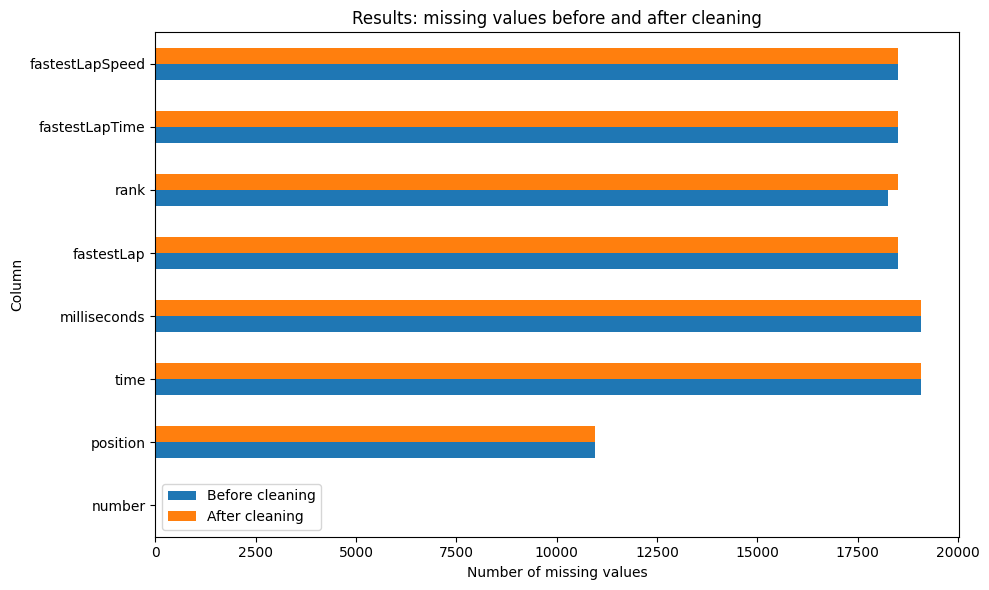

In [24]:
# Compare the original columns before and after cleaning
missing_before_after = pd.DataFrame({
    "Before cleaning": results.isna().sum(),
    "After cleaning": results_clean[results.columns].isna().sum()
})

# Display only columns with missing values before or after
columns_with_missing = missing_before_after[
    (missing_before_after > 0).any(axis=1)
]

# Draw the comparison
columns_with_missing.plot.barh(figsize=(10, 6))

plt.title("Results: missing values before and after cleaning")
plt.xlabel("Number of missing values")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

## 2. Drivers
One row per driver. Inspect identifiers and missingness; then remove unused `number`, `code` and `url`, and parse birth dates.

In [25]:
# Preserve the original table
drivers_clean = drivers.copy()

# Show the first five rows
display(drivers_clean.head())

print("Number of drivers:", len(drivers_clean))

drivers_clean.info()

,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44.0,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,NaN,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,6.0,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
3,4,alonso,14.0,ALO,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
4,5,kovalainen,NaN,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen


Number of drivers: 861
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 861 entries, 0 to 860
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   driverId     861 non-null    int64  
 1   driverRef    861 non-null    object 
 2   number       59 non-null     float64
 3   code         104 non-null    object 
 4   forename     861 non-null    object 
 5   surname      861 non-null    object 
 6   dob          861 non-null    object 
 7   nationality  861 non-null    object 
 8   url          861 non-null    object 
dtypes: float64(1), int64(1), object(7)
memory usage: 60.7+ KB


In [26]:
drivers_missing = pd.DataFrame({
    "Missing count": drivers_clean.isna().sum(),
    "Missing percentage": (
        drivers_clean.isna().sum() / len(drivers_clean) * 100
    ).round(2)
})

display(drivers_missing)

#check for missing or repeated driver IDs
print(
    "Missing driver IDs:",
    drivers_clean["driverId"].isna().sum()
)

print(
    "Repeated driver IDs:",
    drivers_clean["driverId"].duplicated().sum()
)

print(
    "Completely repeated rows:",
    drivers_clean.duplicated().sum()
)

display(drivers_clean[
    ["driverId", "forename", "surname", "dob", "nationality"]
].head(10))

,Missing count,Missing percentage
driverId,0,0.00
driverRef,0,0.00
number,802,93.15
code,757,87.92
forename,0,0.00
surname,0,0.00
dob,0,0.00
nationality,0,0.00
url,0,0.00


Missing driver IDs: 0
Repeated driver IDs: 0
Completely repeated rows: 0


,driverId,forename,surname,dob,nationality
0,1,Lewis,Hamilton,1985-01-07,British
1,2,Nick,Heidfeld,1977-05-10,German
2,3,Nico,Rosberg,1985-06-27,German
3,4,Fernando,Alonso,1981-07-29,Spanish
4,5,Heikki,Kovalainen,1981-10-19,Finnish
5,6,Kazuki,Nakajima,1985-01-11,Japanese
6,7,Sébastien,Bourdais,1979-02-28,French
7,8,Kimi,Räikkönen,1979-10-17,Finnish
8,9,Robert,Kubica,1984-12-07,Polish
9,10,Timo,Glock,1982-03-18,German


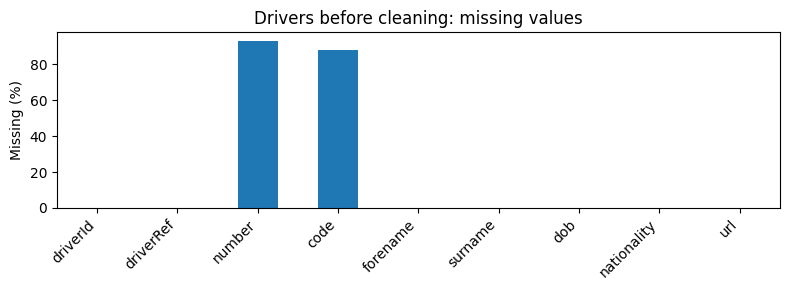

In [27]:
drivers_missing["Missing percentage"].plot.bar(figsize=(8, 3))
plt.title("Drivers before cleaning: missing values")
plt.ylabel("Missing (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [28]:
# Create the cleaned table without these unnecessary columns
drivers_clean = drivers.drop(
    columns=["number", "code", "url"]
).copy()

drivers_clean["dob"] = pd.to_datetime(
    drivers_clean["dob"],
    format="%Y-%m-%d"
)

In [29]:
compare_cleaning(drivers, drivers_clean)

Rows: 861 → 861
Columns: 9 → 6


,Type before,Type after,Missing before,Missing after
code,object,—,757,—
dob,object,datetime64[ns],0,0.0
driverId,int64,int64,0,0.0
driverRef,object,object,0,0.0
forename,object,object,0,0.0
nationality,object,object,0,0.0
number,float64,—,802,—
surname,object,object,0,0.0
url,object,—,0,—


All 861 drivers remain. `number` and `code` are 93.15% and 87.92% missing and are not needed in the current cleaned table; raw values remain available. Birth dates parse successfully and the six retained columns have no missing values.

## 3. Constructors
One row per constructor. Check IDs and completeness; remove only the reference URL.

In [30]:
# Create a working copy
constructors_clean = constructors.copy()

# Preview the table
display(constructors_clean.head())

# Check its size and column types
print("Number of constructors:", len(constructors_clean))

constructors_clean.info()

,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso


Number of constructors: 212
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   constructorId   212 non-null    int64 
 1   constructorRef  212 non-null    object
 2   name            212 non-null    object
 3   nationality     212 non-null    object
 4   url             212 non-null    object
dtypes: int64(1), object(4)
memory usage: 8.4+ KB


In [31]:
# Check missing values
display(constructors_clean.isna().sum())

# Each constructor should have one unique ID
print(
    "Missing constructor IDs:",
    constructors_clean["constructorId"].isna().sum()
)

print(
    "Repeated constructor IDs:",
    constructors_clean["constructorId"].duplicated().sum()
)

print(
    "Completely repeated rows:",
    constructors_clean.duplicated().sum()
)

constructorId     0
constructorRef    0
name              0
nationality       0
url               0
dtype: int64

Missing constructor IDs: 0
Repeated constructor IDs: 0
Completely repeated rows: 0


In [32]:
# Keep the original constructors table unchanged
constructors_clean = constructors.drop(columns=["url"]).copy()

display(constructors_clean.head())

,constructorId,constructorRef,name,nationality
0,1,mclaren,McLaren,British
1,2,bmw_sauber,BMW Sauber,German
2,3,williams,Williams,British
3,4,renault,Renault,French
4,5,toro_rosso,Toro Rosso,Italian


In [33]:
compare_cleaning(constructors, constructors_clean)

Rows: 212 → 212
Columns: 5 → 4


,Type before,Type after,Missing before,Missing after
constructorId,int64,int64,0,0.0
constructorRef,object,object,0,0.0
name,object,object,0,0.0
nationality,object,object,0,0.0
url,object,—,0,—


All 212 constructors remain, with no missing values or repeated IDs. Names and nationalities are unchanged.

## 4. Circuits
Check circuit IDs, country labels and geographic ranges. Remove only `url`; negative altitude alone is not an error.

In [34]:
circuits_clean = circuits.copy()

display(circuits_clean.head())

print("Number of circuits:", len(circuits_clean))

circuits_clean.info()

,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park


Number of circuits: 77
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB


In [35]:
circuits_missing = pd.DataFrame({
    "Missing count": circuits_clean.isna().sum(),
    "Missing percentage": (
        circuits_clean.isna().sum() / len(circuits_clean) * 100
    ).round(2)
})

display(circuits_missing)

print(
    "Missing circuit IDs:",
    circuits_clean["circuitId"].isna().sum()
)

print(
    "Repeated circuit IDs:",
    circuits_clean["circuitId"].duplicated().sum()
)

print(
    "Completely repeated rows:",
    circuits_clean.duplicated().sum()
)

,Missing count,Missing percentage
circuitId,0,0.0
circuitRef,0,0.0
name,0,0.0
location,0,0.0
country,0,0.0
lat,0,0.0
lng,0,0.0
alt,0,0.0
url,0,0.0


Missing circuit IDs: 0
Repeated circuit IDs: 0
Completely repeated rows: 0


In [36]:
display(circuits_clean[["lat", "lng", "alt"]].describe())

display(sorted(circuits_clean["country"].dropna().unique()))

,lat,lng,alt
count,77.000000,77.000000,77.000000
mean,33.442925,1.076683,247.012987
std,22.808866,65.516951,362.738469
min,-37.849700,-118.189000,-7.000000
25%,32.777400,-9.394170,18.000000
50%,40.951700,3.930830,129.000000
75%,46.958900,19.248600,332.000000
max,57.265300,144.968000,2227.000000


['Argentina',
 'Australia',
 'Austria',
 'Azerbaijan',
 'Bahrain',
 'Belgium',
 'Brazil',
 'Canada',
 'China',
 'France',
 'Germany',
 'Hungary',
 'India',
 'Italy',
 'Japan',
 'Korea',
 'Malaysia',
 'Mexico',
 'Monaco',
 'Morocco',
 'Netherlands',
 'Portugal',
 'Qatar',
 'Russia',
 'Saudi Arabia',
 'Singapore',
 'South Africa',
 'Spain',
 'Sweden',
 'Switzerland',
 'Turkey',
 'UAE',
 'UK',
 'USA',
 'United States']

In [37]:
print("Invalid latitude:", (~circuits_clean["lat"].between(-90, 90)).sum())
print("Invalid longitude:", (~circuits_clean["lng"].between(-180, 180)).sum())

Invalid latitude: 0
Invalid longitude: 0


In [38]:
# Remove reference URLs while preserving the original table
circuits_clean = circuits.drop(columns=["url"]).copy()

display(circuits_clean.head())

,circuitId,circuitRef,name,location,country,lat,lng,alt
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130


In [39]:
compare_cleaning(circuits, circuits_clean)

Rows: 77 → 77
Columns: 9 → 8


,Type before,Type after,Missing before,Missing after
alt,int64,int64,0,0.0
circuitId,int64,int64,0,0.0
circuitRef,object,object,0,0.0
country,object,object,0,0.0
lat,float64,float64,0,0.0
lng,float64,float64,0,0.0
location,object,object,0,0.0
name,object,object,0,0.0
url,object,—,0,—


All 77 circuits remain. Coordinates fall within valid ranges, and altitude ranges from −7 to 2,227 metres. Country labels are preserved; any later country matching needs an explicit mapping.

## 5. Races
One row per race. Check race IDs, season rounds, circuit references and dates. Remove unused session schedules (over 90% missing) and `url`; keep the race date and available start times.

In [40]:
races_clean = races.copy()

display(races_clean.head())

print("Number of races:", len(races_clean))

races_clean.info()

,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Number of races: 1125
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1125 entries, 0 to 1124
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   raceId       1125 non-null   int64 
 1   year         1125 non-null   int64 
 2   round        1125 non-null   int64 
 3   circuitId    1125 non-null   int64 
 4   name         1125 non-null   object
 5   date         1125 non-null   object
 6   time         394 non-null    object
 7   url          1125 non-null   object
 8   fp1_date     90 non-null     object
 9   fp1_time     68 non-null     object
 10  fp2_date     90 non-null     object
 11  fp2_time     68 non-null     object
 12  fp3_date     72 non-null     object
 13  fp3_time     53 non-null     object
 14  quali_date   90 non-null     object
 15  quali_time   68 non-null     object
 16  sprint_date  18 non-null     object
 17  sprint_time  15 non-null     object
dtypes: int64(4), object(14)
memory usage: 158.3+ K

In [41]:
races_missing = pd.DataFrame({
    "Missing count": races_clean.isna().sum(),
    "Missing percentage": (
        races_clean.isna().sum() / len(races_clean) * 100
    ).round(2)
})

display(races_missing)

print("Missing race IDs:", races_clean["raceId"].isna().sum())

print("Repeated race IDs:", races_clean["raceId"].duplicated().sum())

print("Completely repeated rows:", races_clean.duplicated().sum())

# Each season should normally have one race per round number
print(
    "Repeated year-round combinations:",
    races_clean.duplicated(subset=["year", "round"]).sum()
)

print(
    "Unknown circuit IDs:",
    (~races_clean["circuitId"].isin(circuits_clean["circuitId"])).sum()
)

,Missing count,Missing percentage
raceId,0,0.00
year,0,0.00
round,0,0.00
circuitId,0,0.00
name,0,0.00
date,0,0.00
time,731,64.98
url,0,0.00
fp1_date,1035,92.00
fp1_time,1057,93.96


Missing race IDs: 0
Repeated race IDs: 0
Completely repeated rows: 0
Repeated year-round combinations: 0
Unknown circuit IDs: 0


In [42]:
display(races_clean[["year", "round"]].describe())

display(races_clean[
    ["raceId", "year", "round", "name", "date", "time"]
].head(10))

,year,round
count,1125.000000,1125.000000
mean,1992.703111,8.579556
std,20.603848,5.159910
min,1950.000000,1.000000
25%,1977.000000,4.000000
50%,1994.000000,8.000000
75%,2011.000000,13.000000
max,2024.000000,24.000000


,raceId,year,round,name,date,time
0,1,2009,1,Australian Grand Prix,2009-03-29,06:00:00
1,2,2009,2,Malaysian Grand Prix,2009-04-05,09:00:00
2,3,2009,3,Chinese Grand Prix,2009-04-19,07:00:00
3,4,2009,4,Bahrain Grand Prix,2009-04-26,12:00:00
4,5,2009,5,Spanish Grand Prix,2009-05-10,12:00:00
5,6,2009,6,Monaco Grand Prix,2009-05-24,12:00:00
6,7,2009,7,Turkish Grand Prix,2009-06-07,12:00:00
7,8,2009,8,British Grand Prix,2009-06-21,12:00:00
8,9,2009,9,German Grand Prix,2009-07-12,12:00:00
9,10,2009,10,Hungarian Grand Prix,2009-07-26,12:00:00


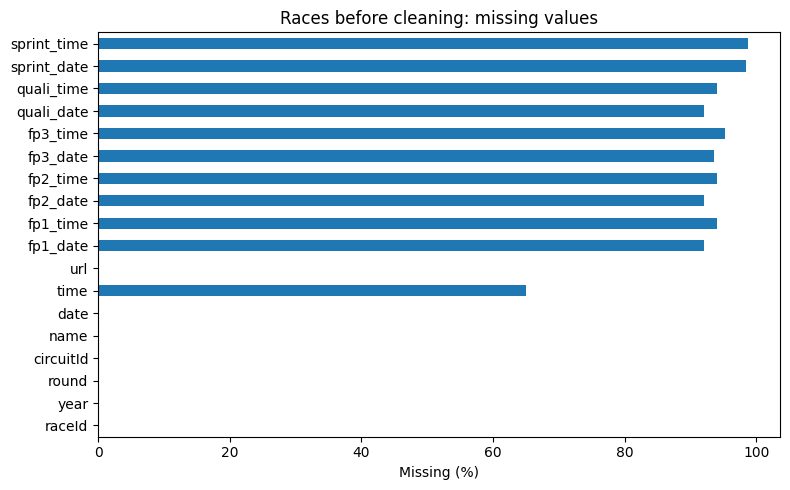

In [43]:
races_missing["Missing percentage"].plot.barh(figsize=(8, 5))
plt.title("Races before cleaning: missing values")
plt.xlabel("Missing (%)")
plt.tight_layout()
plt.show()

In [44]:
columns_to_drop = [
    "url",
    "fp1_date", "fp1_time",
    "fp2_date", "fp2_time",
    "fp3_date", "fp3_time",
    "quali_date", "quali_time",
    "sprint_date", "sprint_time"
]

races_clean = races.drop(columns=columns_to_drop).copy()

races_clean["date"] = pd.to_datetime(
    races_clean["date"],
    format="%Y-%m-%d"
)

races_clean["time"] = pd.to_datetime(
    races_clean["time"],
    format="%H:%M:%S"
).dt.time

In [45]:
# Display any races whose date year differs from the year column
display(races_clean[
    races_clean["date"].dt.year != races_clean["year"]
])

,raceId,year,round,circuitId,name,date,time


In [46]:
compare_cleaning(races, races_clean)

Rows: 1,125 → 1,125
Columns: 18 → 7


,Type before,Type after,Missing before,Missing after
circuitId,int64,int64,0,0.0
date,object,datetime64[ns],0,0.0
fp1_date,object,—,1035,—
fp1_time,object,—,1057,—
fp2_date,object,—,1035,—
fp2_time,object,—,1057,—
fp3_date,object,—,1053,—
fp3_time,object,—,1072,—
name,object,object,0,0.0
quali_date,object,—,1035,—


All 1,125 races remain. Dates agree with the year column. The 731 unavailable race start times remain missing; parsed clock times have pandas `object` dtype.

## 6. Status
This lookup explains how an entry ended. Check IDs and inspect the labels; no cleaning change is needed.

In [47]:
status_clean = status.copy()

display(status_clean.head(15))

print("Number of statuses:", len(status_clean))

status_clean.info()

,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine
5,6,Gearbox
6,7,Transmission
7,8,Clutch
8,9,Hydraulics
9,10,Electrical


Number of statuses: 139
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   statusId  139 non-null    int64 
 1   status    139 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.3+ KB


In [48]:
print("Missing values:")
print(status_clean.isna().sum())

print(
    "Repeated status IDs:",
    status_clean["statusId"].duplicated().sum()
)

print(
    "Completely repeated rows:",
    status_clean.duplicated().sum()
)

print(
    status_clean.sort_values("statusId").to_string(index=False)
)

Missing values:
statusId    0
status      0
dtype: int64
Repeated status IDs: 0
Completely repeated rows: 0
 statusId             status
        1           Finished
        2       Disqualified
        3           Accident
        4          Collision
        5             Engine
        6            Gearbox
        7       Transmission
        8             Clutch
        9         Hydraulics
       10         Electrical
       11             +1 Lap
       12            +2 Laps
       13            +3 Laps
       14            +4 Laps
       15            +5 Laps
       16            +6 Laps
       17            +7 Laps
       18            +8 Laps
       19            +9 Laps
       20           Spun off
       21           Radiator
       22         Suspension
       23             Brakes
       24       Differential
       25        Overheating
       26         Mechanical
       27               Tyre
       28        Driver Seat
       29           Puncture
       30         Driv

In [49]:
compare_cleaning(status, status_clean)

Rows: 139 → 139
Columns: 2 → 2


,Type before,Type after,Missing before,Missing after
statusId,int64,int64,0,0
status,object,object,0,0


All 139 status records are complete and unique. Keep the lookup unchanged.

## 7. Seasons
Check unique years and coverage of race seasons. Remove the reference URL.

In [50]:
seasons_clean = seasons.copy()

display(seasons_clean.head())

seasons_clean.info()

print("Missing values:")
print(seasons_clean.isna().sum())

print(
    "Repeated years:",
    seasons_clean["year"].duplicated().sum()
)

print(
    "Race years absent from seasons:",
    (~races_clean["year"].isin(seasons_clean["year"])).sum()
)

,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75 entries, 0 to 74
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   year    75 non-null     int64 
 1   url     75 non-null     object
dtypes: int64(1), object(1)
memory usage: 1.3+ KB
Missing values:
year    0
url     0
dtype: int64
Repeated years: 0
Race years absent from seasons: 0


In [51]:
seasons_clean = seasons.drop(columns=["url"]).copy()

display(seasons_clean.head())

,year
0,2009
1,2008
2,2007
3,2006
4,2005


In [52]:
compare_cleaning(seasons, seasons_clean)

Rows: 75 → 75
Columns: 2 → 1


,Type before,Type after,Missing before,Missing after
url,object,—,0,—
year,int64,int64,0,0.0


All 75 season years remain; every race year appears in this table.

## 8. Qualifying
Check entry IDs, driver–race uniqueness and historical coverage. Keep missing session times: absence can reflect non-participation, the qualifying format, or unavailable records. Missingness alone cannot distinguish these reasons.

In [53]:
qualifying_clean = qualifying.copy()

display(qualifying_clean.head())

print("Number of qualifying entries:", len(qualifying_clean))

qualifying_clean.info()

,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


Number of qualifying entries: 10494
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10494 entries, 0 to 10493
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   qualifyId      10494 non-null  int64 
 1   raceId         10494 non-null  int64 
 2   driverId       10494 non-null  int64 
 3   constructorId  10494 non-null  int64 
 4   number         10494 non-null  int64 
 5   position       10494 non-null  int64 
 6   q1             10338 non-null  object
 7   q2             5847 non-null   object
 8   q3             3629 non-null   object
dtypes: int64(6), object(3)
memory usage: 738.0+ KB


In [54]:
qualifying_missing = pd.DataFrame({
    "Missing count": qualifying_clean.isna().sum(),
    "Missing percentage": (
        qualifying_clean.isna().sum() / len(qualifying_clean) * 100
    ).round(2)
})

display(qualifying_missing)

print(
    "Missing qualifying IDs:",
    qualifying_clean["qualifyId"].isna().sum()
)

print(
    "Repeated qualifying IDs:",
    qualifying_clean["qualifyId"].duplicated().sum()
)

print(
    "Repeated driver-race combinations:",
    qualifying_clean.duplicated(["raceId", "driverId"]).sum()
)

print(
    "Completely repeated rows:",
    qualifying_clean.duplicated().sum()
)

print(
    "Unknown race IDs:",
    (~qualifying_clean["raceId"].isin(races_clean["raceId"])).sum()
)

print(
    "Unknown driver IDs:",
    (~qualifying_clean["driverId"].isin(drivers_clean["driverId"])).sum()
)

print(
    "Unknown constructor IDs:",
    (~qualifying_clean["constructorId"].isin(
        constructors_clean["constructorId"]
    )).sum()
)

,Missing count,Missing percentage
qualifyId,0,0.00
raceId,0,0.00
driverId,0,0.00
constructorId,0,0.00
number,0,0.00
position,0,0.00
q1,156,1.49
q2,4647,44.28
q3,6865,65.42


Missing qualifying IDs: 0
Repeated qualifying IDs: 0
Repeated driver-race combinations: 0
Completely repeated rows: 0
Unknown race IDs: 0
Unknown driver IDs: 0
Unknown constructor IDs: 0


In [55]:
# Add the season for inspection
qualifying_by_year = qualifying_clean.merge(
    races_clean[["raceId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

display(qualifying_by_year.groupby("year").size())

year
1994    392
1995    418
1996    148
1997    220
1998    153
1999     65
2000     88
2001     22
2002     42
2003    320
2004    360
2005    376
2006    396
2007    374
2008    368
2009    340
2010    456
2011    452
2012    476
2013    418
2014    405
2015    374
2016    457
2017    398
2018    420
2019    418
2020    340
2021    439
2022    440
2023    440
2024    479
dtype: int64

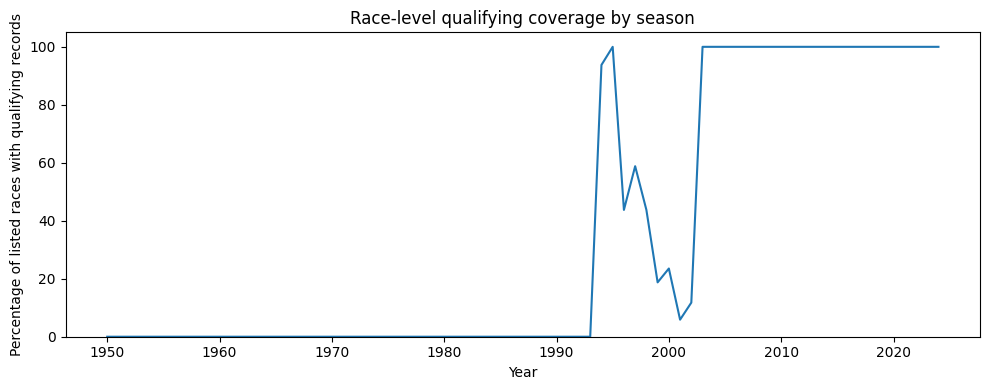

In [56]:
# Number of races listed in each season
races_per_year = races_clean.groupby("year")["raceId"].nunique()

# Number of races with at least one qualifying record
qualifying_races_per_year = (
    qualifying_by_year.groupby("year")["raceId"].nunique()
)

# Include seasons with no qualifying records
qualifying_races_per_year = qualifying_races_per_year.reindex(
    races_per_year.index,
    fill_value=0
)

coverage_percentage = (
    qualifying_races_per_year / races_per_year * 100
)

coverage_percentage.plot(figsize=(10, 4))

plt.title("Race-level qualifying coverage by season")
plt.xlabel("Year")
plt.ylabel("Percentage of listed races with qualifying records")
plt.ylim(0, 105)
plt.tight_layout()
plt.show()

Coverage begins in 1994 and varies in the early years. The chart measures races with at least one qualifying record, not completeness for every driver.

In [57]:
qualifying_clean["q1_seconds"] = (
    qualifying_clean["q1"].apply(convert_to_seconds)
)

qualifying_clean["q2_seconds"] = (
    qualifying_clean["q2"].apply(convert_to_seconds)
)

qualifying_clean["q3_seconds"] = (
    qualifying_clean["q3"].apply(convert_to_seconds)
)

display(qualifying_clean[
    ["q1", "q1_seconds", "q2", "q2_seconds", "q3", "q3_seconds"]
].head(10))

,q1,q1_seconds,q2,q2_seconds,q3,q3_seconds
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236
5,1:26.427,86.427,1:26.101,86.101,1:28.527,88.527
6,1:26.295,86.295,1:26.059,86.059,1:28.687,88.687
7,1:26.381,86.381,1:26.063,86.063,1:29.041,89.041
8,1:26.919,86.919,1:26.164,86.164,1:29.593,89.593
9,1:26.702,86.702,1:25.842,85.842,NaN,NaN


In [58]:
for session in ["q1", "q2", "q3"]:
    print(
        session,
        "| Missing before:", qualifying_clean[session].isna().sum(),
        "| Missing after:", qualifying_clean[session + "_seconds"].isna().sum()
    )

for column in ["q1_seconds", "q2_seconds", "q3_seconds"]:
    print(
        column,
        "| Zero or negative times:",
        (qualifying_clean[column] <= 0).sum()
    )

print(
    "Zero or negative qualifying positions:",
    (qualifying_clean["position"] <= 0).sum()
)

q1 | Missing before: 156 | Missing after: 156
q2 | Missing before: 4647 | Missing after: 4647
q3 | Missing before: 6865 | Missing after: 6865
q1_seconds | Zero or negative times: 0
q2_seconds | Zero or negative times: 0
q3_seconds | Zero or negative times: 0
Zero or negative qualifying positions: 0


In [59]:
compare_cleaning(qualifying, qualifying_clean)

Rows: 10,494 → 10,494
Columns: 9 → 12


,Type before,Type after,Missing before,Missing after
constructorId,int64,int64,0.0,0
driverId,int64,int64,0.0,0
number,int64,int64,0.0,0
position,int64,int64,0.0,0
q1,object,object,156.0,156
q1_seconds,—,float64,—,156
q2,object,object,4647.0,4647
q2_seconds,—,float64,—,4647
q3,object,object,6865.0,6865
q3_seconds,—,float64,—,6865


All 10,494 entries remain. Three seconds columns were added without filling or losing recorded times; missing Q1/Q2/Q3 counts remain 156/4,647/6,865. No nonpositive recorded qualifying times or positions were found.

## 9. Driver standings
These are championship standings after each race. Check keys, references, points, positions and wins; keep the table unchanged if checks reveal no issue.

In [60]:
driver_standings_clean = driver_standings.copy()

display(driver_standings_clean.head())

print("Number of entries:", len(driver_standings_clean))

driver_standings_clean.info()

,driverStandingsId,raceId,driverId,points,position,positionText,wins
0,1,18,1,10.0,1,1,1
1,2,18,2,8.0,2,2,0
2,3,18,3,6.0,3,3,0
3,4,18,4,5.0,4,4,0
4,5,18,5,4.0,5,5,0


Number of entries: 34863
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34863 entries, 0 to 34862
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   driverStandingsId  34863 non-null  int64  
 1   raceId             34863 non-null  int64  
 2   driverId           34863 non-null  int64  
 3   points             34863 non-null  float64
 4   position           34863 non-null  int64  
 5   positionText       34863 non-null  object 
 6   wins               34863 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 1.9+ MB


In [61]:
print("Missing values:")
print(driver_standings_clean.isna().sum())

print(
    "Repeated standings IDs:",
    driver_standings_clean["driverStandingsId"].duplicated().sum()
)

print(
    "Repeated driver-race combinations:",
    driver_standings_clean.duplicated(["raceId", "driverId"]).sum()
)

print(
    "Completely repeated rows:",
    driver_standings_clean.duplicated().sum()
)

print(
    "Unknown race IDs:",
    (~driver_standings_clean["raceId"].isin(
        races_clean["raceId"]
    )).sum()
)

print(
    "Unknown driver IDs:",
    (~driver_standings_clean["driverId"].isin(
        drivers_clean["driverId"]
    )).sum()
)

Missing values:
driverStandingsId    0
raceId               0
driverId             0
points               0
position             0
positionText         0
wins                 0
dtype: int64
Repeated standings IDs: 0
Repeated driver-race combinations: 0
Completely repeated rows: 0
Unknown race IDs: 0
Unknown driver IDs: 0


In [62]:
display(driver_standings_clean[
    ["points", "position", "wins"]
].describe())

# Inspect any unusual values without changing them
display(driver_standings_clean[
    (driver_standings_clean["points"] < 0)
    | (driver_standings_clean["position"] <= 0)
    | (driver_standings_clean["wins"] < 0)
])

,points,position,wins
count,34863.000000,34863.000000,34863.000000
mean,14.704423,19.716720,0.277343
std,38.978094,16.293401,1.032618
min,0.000000,1.000000,0.000000
25%,0.000000,8.000000,0.000000
50%,1.000000,16.000000,0.000000
75%,10.000000,26.000000,0.000000
max,575.000000,108.000000,19.000000


,driverStandingsId,raceId,driverId,points,position,positionText,wins


In [63]:
compare_cleaning(driver_standings, driver_standings_clean)

Rows: 34,863 → 34,863
Columns: 7 → 7


,Type before,Type after,Missing before,Missing after
driverStandingsId,int64,int64,0,0
raceId,int64,int64,0,0
driverId,int64,int64,0,0
points,float64,float64,0,0
position,int64,int64,0,0
positionText,object,object,0,0
wins,int64,int64,0,0


All 34,863 records are retained. No missing values, repeated driver–race pairs, invalid references or values failing the displayed range checks were found.

## 10. Constructor standings
Check championship standings at one constructor per race, including IDs, references and numeric ranges.

In [64]:
constructor_standings_clean = constructor_standings.copy()

display(constructor_standings_clean.head())

print("Number of entries:", len(constructor_standings_clean))

constructor_standings_clean.info()

,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
0,1,18,1,14.0,1,1,1
1,2,18,2,8.0,3,3,0
2,3,18,3,9.0,2,2,0
3,4,18,4,5.0,4,4,0
4,5,18,5,2.0,5,5,0


Number of entries: 13391
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13391 entries, 0 to 13390
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   constructorStandingsId  13391 non-null  int64  
 1   raceId                  13391 non-null  int64  
 2   constructorId           13391 non-null  int64  
 3   points                  13391 non-null  float64
 4   position                13391 non-null  int64  
 5   positionText            13391 non-null  object 
 6   wins                    13391 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 732.4+ KB


In [65]:
print("Missing values:")
print(constructor_standings_clean.isna().sum())

print(
    "Repeated standings IDs:",
    constructor_standings_clean["constructorStandingsId"].duplicated().sum()
)

print(
    "Repeated team-race combinations:",
    constructor_standings_clean.duplicated(
        ["raceId", "constructorId"]
    ).sum()
)

print(
    "Completely repeated rows:",
    constructor_standings_clean.duplicated().sum()
)

print(
    "Unknown race IDs:",
    (~constructor_standings_clean["raceId"].isin(
        races_clean["raceId"]
    )).sum()
)

print(
    "Unknown constructor IDs:",
    (~constructor_standings_clean["constructorId"].isin(
        constructors_clean["constructorId"]
    )).sum()
)

Missing values:
constructorStandingsId    0
raceId                    0
constructorId             0
points                    0
position                  0
positionText              0
wins                      0
dtype: int64
Repeated standings IDs: 0
Repeated team-race combinations: 0
Completely repeated rows: 0
Unknown race IDs: 0
Unknown constructor IDs: 0


In [66]:
display(constructor_standings_clean[
    ["points", "position", "wins"]
].describe())

# Display values that need investigation
display(constructor_standings_clean[
    (constructor_standings_clean["points"] < 0)
    | (constructor_standings_clean["position"] <= 0)
    | (constructor_standings_clean["wins"] < 0)
])

,points,position,wins
count,13391.000000,13391.000000,13391.000000
mean,37.178515,7.226047,0.697409
std,84.346048,4.355923,1.879569
min,0.000000,1.000000,0.000000
25%,0.000000,4.000000,0.000000
50%,7.000000,7.000000,0.000000
75%,33.000000,10.000000,0.000000
max,860.000000,22.000000,21.000000


,constructorStandingsId,raceId,constructorId,points,position,positionText,wins


In [67]:
compare_cleaning(constructor_standings, constructor_standings_clean)

Rows: 13,391 → 13,391
Columns: 7 → 7


,Type before,Type after,Missing before,Missing after
constructorStandingsId,int64,int64,0,0
raceId,int64,int64,0,0
constructorId,int64,int64,0,0
points,float64,float64,0,0
position,int64,int64,0,0
positionText,object,object,0,0
wins,int64,int64,0,0


All 13,391 records remain unchanged. Missingness, key, reference and displayed range checks reveal no issue.

## 11. Constructor results
These are race-level constructor results. Inspect the sparse status field before applying the previously agreed column removal.

In [68]:
constructor_results_clean = constructor_results.copy()

display(constructor_results_clean.head())

print("Number of entries:", len(constructor_results_clean))

constructor_results_clean.info()

,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,NaN
1,2,18,2,8.0,NaN
2,3,18,3,9.0,NaN
3,4,18,4,5.0,NaN
4,5,18,5,2.0,NaN


Number of entries: 12625
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                17 non-null     object 
dtypes: float64(1), int64(3), object(1)
memory usage: 493.3+ KB


In [69]:
print("Missing values:")
print(constructor_results_clean.isna().sum())

print(
    "Repeated result IDs:",
    constructor_results_clean["constructorResultsId"].duplicated().sum()
)

print(
    "Repeated team-race combinations:",
    constructor_results_clean.duplicated(
        ["raceId", "constructorId"]
    ).sum()
)

print(
    "Completely repeated rows:",
    constructor_results_clean.duplicated().sum()
)

print(
    "Unknown race IDs:",
    (~constructor_results_clean["raceId"].isin(
        races_clean["raceId"]
    )).sum()
)

print(
    "Unknown constructor IDs:",
    (~constructor_results_clean["constructorId"].isin(
        constructors_clean["constructorId"]
    )).sum()
)

Missing values:
constructorResultsId        0
raceId                      0
constructorId               0
points                      0
status                  12608
dtype: int64
Repeated result IDs: 0
Repeated team-race combinations: 0
Completely repeated rows: 0
Unknown race IDs: 0
Unknown constructor IDs: 0


In [70]:
display(constructor_results_clean["points"].describe())

# Include missing values in the status counts
display(constructor_results_clean["status"].value_counts(dropna=False))

# Inspect negative points, if any
display(constructor_results_clean[
    constructor_results_clean["points"] < 0
])

display(constructor_results_clean[
    constructor_results_clean["status"].notna()
])

count    12625.000000
mean         4.053545
std          7.862202
min          0.000000
25%          0.000000
50%          0.000000
75%          5.000000
max         66.000000
Name: points, dtype: float64

status
NaN    12608
D         17
Name: count, dtype: int64

,constructorResultsId,raceId,constructorId,points,status


,constructorResultsId,raceId,constructorId,points,status
185,186,36,1,14.0,D
195,196,37,1,18.0,D
207,208,38,1,12.0,D
218,219,39,1,14.0,D
228,229,40,1,18.0,D
239,240,41,1,12.0,D
250,251,42,1,18.0,D
262,263,43,1,8.0,D
273,274,44,1,14.0,D
283,284,45,1,10.0,D


`status` contains 17 `D` values and 12,608 missing values. Preserve the existing decision to drop it from the cleaned table. Those 17 exception markers are still available in the raw table; dropping the field does not mean they have no meaning.

In [71]:
constructor_results_clean = constructor_results.drop(
    columns=["status"]
).copy()

display(constructor_results_clean.head())

,constructorResultsId,raceId,constructorId,points
0,1,18,1,14.0
1,2,18,2,8.0
2,3,18,3,9.0
3,4,18,4,5.0
4,5,18,5,2.0


In [72]:
compare_cleaning(constructor_results, constructor_results_clean)

Rows: 12,625 → 12,625
Columns: 5 → 4


,Type before,Type after,Missing before,Missing after
constructorId,int64,int64,0,0.0
constructorResultsId,int64,int64,0,0.0
points,float64,float64,0,0.0
raceId,int64,int64,0,0.0
status,object,—,12608,—


All 12,625 rows and their points are retained. The four remaining columns have no missing values.

## 12. Sprint results
Check entry IDs and references, then inspect missing values alongside race-ending statuses. Do not invent finishing positions or timings for incomplete entries.

In [73]:
sprint_results_clean = sprint_results.copy()

display(sprint_results_clean.head())

print("Number of entries:", len(sprint_results_clean))

sprint_results_clean.info()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1.0,1,1,3,17,25:38.426,1538426.0,14.0,1:30.013,1
1,2,1061,1,131,44,1,2.0,2,2,2,17,+1.430,1539856.0,17.0,1:29.937,1
2,3,1061,822,131,77,3,3.0,3,3,1,17,+7.502,1545928.0,17.0,1:29.958,1
3,4,1061,844,6,16,4,4.0,4,4,0,17,+11.278,1549704.0,16.0,1:30.163,1
4,5,1061,846,1,4,6,5.0,5,5,0,17,+24.111,1562537.0,16.0,1:30.566,1


Number of entries: 360
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   resultId        360 non-null    int64  
 1   raceId          360 non-null    int64  
 2   driverId        360 non-null    int64  
 3   constructorId   360 non-null    int64  
 4   number          360 non-null    int64  
 5   grid            360 non-null    int64  
 6   position        345 non-null    float64
 7   positionText    360 non-null    object 
 8   positionOrder   360 non-null    int64  
 9   points          360 non-null    int64  
 10  laps            360 non-null    int64  
 11  time            340 non-null    object 
 12  milliseconds    340 non-null    float64
 13  fastestLap      351 non-null    float64
 14  fastestLapTime  351 non-null    object 
 15  statusId        360 non-null    int64  
dtypes: float64(3), int64(10), object(3)
memory usage: 45.1+ K

In [74]:
sprint_missing = pd.DataFrame({
    "Missing count": sprint_results_clean.isna().sum(),
    "Missing percentage": (
        sprint_results_clean.isna().sum()
        / len(sprint_results_clean) * 100
    ).round(2)
})

display(sprint_missing)

print(
    "Repeated result IDs:",
    sprint_results_clean["resultId"].duplicated().sum()
)

print(
    "Repeated driver-race combinations:",
    sprint_results_clean.duplicated(["raceId", "driverId"]).sum()
)

print(
    "Completely repeated rows:",
    sprint_results_clean.duplicated().sum()
)

print(
    "Unknown races:",
    (~sprint_results_clean["raceId"].isin(races_clean["raceId"])).sum()
)

print(
    "Unknown drivers:",
    (~sprint_results_clean["driverId"].isin(drivers_clean["driverId"])).sum()
)

print(
    "Unknown constructors:",
    (~sprint_results_clean["constructorId"].isin(
        constructors_clean["constructorId"]
    )).sum()
)

print(
    "Unknown statuses:",
    (~sprint_results_clean["statusId"].isin(status_clean["statusId"])).sum()
)

,Missing count,Missing percentage
resultId,0,0.00
raceId,0,0.00
driverId,0,0.00
constructorId,0,0.00
number,0,0.00
grid,0,0.00
position,15,4.17
positionText,0,0.00
positionOrder,0,0.00
points,0,0.00


Repeated result IDs: 0
Repeated driver-race combinations: 0
Completely repeated rows: 0
Unknown races: 0
Unknown drivers: 0
Unknown constructors: 0
Unknown statuses: 0


In [75]:
# Columns we want to investigate
columns_with_missing = [
    "position",
    "time",
    "milliseconds",
    "fastestLap",
    "fastestLapTime"
]

# Select rows missing at least one of these values
missing_rows = sprint_results_clean[
    sprint_results_clean[columns_with_missing].isna().any(axis=1)
]

# Add readable status descriptions
missing_details = missing_rows.merge(
    status_clean,
    on="statusId",
    how="left",
    validate="many_to_one"
)

display(missing_details[
    [
        "raceId", "driverId",
        "position", "positionText", "positionOrder",
        "laps", "time", "milliseconds",
        "fastestLap", "fastestLapTime", "status"
    ]
])

,raceId,driverId,position,positionText,positionOrder,laps,time,milliseconds,fastestLap,fastestLapTime,status
0,1061,815,NaN,R,20,16,NaN,NaN,6.0,1:31.465,Vibrations
1,1065,842,NaN,R,20,0,NaN,NaN,NaN,NaN,Accident
2,1077,855,NaN,R,20,0,NaN,NaN,NaN,NaN,Retired
3,1084,20,19.0,19,19,21,NaN,NaN,4.0,1:10.317,Collision damage
4,1084,4,NaN,N,20,0,NaN,NaN,NaN,NaN,Electrical
5,1095,848,NaN,R,20,12,NaN,NaN,4.0,1:15.998,Retired
6,1101,852,NaN,R,19,2,NaN,NaN,NaN,NaN,Collision damage
7,1101,858,NaN,W,20,0,NaN,NaN,NaN,NaN,Accident
8,1110,815,NaN,R,19,8,NaN,NaN,2.0,2:02.516,Collision damage
9,1110,4,NaN,R,20,2,NaN,NaN,NaN,NaN,Accident


Convert whole-number fields to nullable integers and durations to seconds. Keep elapsed times separate from reported gaps, as in results.

In [76]:
# Store whole numbers while allowing missing values
for column in ["position", "milliseconds", "fastestLap"]:
    sprint_results_clean[column] = (
        sprint_results_clean[column].astype("Int64")
    )

sprint_results_clean["fastest_lap_seconds"] = (
    sprint_results_clean["fastestLapTime"].apply(convert_to_seconds)
)

time_seconds = sprint_results_clean["time"].apply(convert_to_seconds)

is_gap = sprint_results_clean["time"].str.startswith("+", na=False)

sprint_results_clean["reported_elapsed_seconds"] = (
    time_seconds.where(~is_gap)
)

sprint_results_clean["reported_gap_seconds"] = (
    time_seconds.where(is_gap)
)

In [77]:
print("Rows before:", len(sprint_results))
print("Rows after:", len(sprint_results_clean))

print(
    "Missing finishing orders:",
    sprint_results_clean["positionOrder"].isna().sum()
)

Rows before: 360
Rows after: 360
Missing finishing orders: 0


In [78]:
compare_cleaning(sprint_results, sprint_results_clean)

Rows: 360 → 360
Columns: 16 → 19


,Type before,Type after,Missing before,Missing after
constructorId,int64,int64,0.0,0
driverId,int64,int64,0.0,0
fastestLap,float64,Int64,9.0,9
fastestLapTime,object,object,9.0,9
fastest_lap_seconds,—,float64,—,9
grid,int64,int64,0.0,0
laps,int64,int64,0.0,0
milliseconds,float64,Int64,20.0,20
number,int64,int64,0.0,0
points,int64,int64,0.0,0


All 360 entries remain. The 15 missing positions, 20 missing time/millisecond values and nine missing fastest-lap values are retained. The status inspection provides context, not a reliable replacement value.

## 13. Lap times
The key is `(raceId, driverId, lap)`. Check repeated laps even if their position or time differs. Convert recorded milliseconds to seconds without changing source values.

In [79]:
lap_times_clean = lap_times.copy()

display(lap_times_clean.head())

print("Number of lap records:", len(lap_times_clean))

lap_times_clean.info()

,raceId,driverId,lap,position,time,milliseconds
0,841,20,1,1,1:38.109,98109
1,841,20,2,1,1:33.006,93006
2,841,20,3,1,1:32.713,92713
3,841,20,4,1,1:32.803,92803
4,841,20,5,1,1:32.342,92342


Number of lap records: 589081
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 589081 entries, 0 to 589080
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   raceId        589081 non-null  int64 
 1   driverId      589081 non-null  int64 
 2   lap           589081 non-null  int64 
 3   position      589081 non-null  int64 
 4   time          589081 non-null  object
 5   milliseconds  589081 non-null  int64 
dtypes: int64(5), object(1)
memory usage: 27.0+ MB


In [80]:
print("Missing values:")
print(lap_times_clean.isna().sum())

print(
    "Repeated driver-race-lap combinations:",
    lap_times_clean.duplicated(
        ["raceId", "driverId", "lap"]
    ).sum()
)

print(
    "Completely repeated rows:",
    lap_times_clean.duplicated().sum()
)

print(
    "Unknown race IDs:",
    (~lap_times_clean["raceId"].isin(races_clean["raceId"])).sum()
)

print(
    "Unknown driver IDs:",
    (~lap_times_clean["driverId"].isin(drivers_clean["driverId"])).sum()
)

Missing values:
raceId          0
driverId        0
lap             0
position        0
time            0
milliseconds    0
dtype: int64
Repeated driver-race-lap combinations: 0
Completely repeated rows: 0
Unknown race IDs: 0
Unknown driver IDs: 0


In [81]:
display(lap_times_clean[["lap", "position", "milliseconds"]].describe())

# Display zero or negative values for investigation
display(lap_times_clean[
    (lap_times_clean["lap"] <= 0)
    | (lap_times_clean["position"] <= 0)
    | (lap_times_clean["milliseconds"] <= 0)
])

repeated_laps = lap_times_clean[
    lap_times_clean.duplicated(
        ["raceId", "driverId", "lap"],
        keep=False
    )
]

display(repeated_laps.sort_values(["raceId", "driverId", "lap"]))

,lap,position,milliseconds
count,589081.000000,589081.000000,5.890810e+05
mean,30.018104,9.661951,9.579945e+04
std,18.407126,5.528553,7.639973e+04
min,1.000000,1.000000,5.540400e+04
25%,14.000000,5.000000,8.204100e+04
50%,29.000000,9.000000,9.060800e+04
75%,44.000000,14.000000,1.019300e+05
max,87.000000,24.000000,7.507547e+06


,raceId,driverId,lap,position,time,milliseconds


,raceId,driverId,lap,position,time,milliseconds


In [82]:
lap_times_clean["lap_seconds"] = (
    lap_times_clean["milliseconds"] / 1000
)

In [83]:
compare_cleaning(lap_times, lap_times_clean)

Rows: 589,081 → 589,081
Columns: 6 → 7


,Type before,Type after,Missing before,Missing after
driverId,int64,int64,0.0,0
lap,int64,int64,0.0,0
lap_seconds,—,float64,—,0
milliseconds,int64,int64,0.0,0
position,int64,int64,0.0,0
raceId,int64,int64,0.0,0
time,object,object,0.0,0


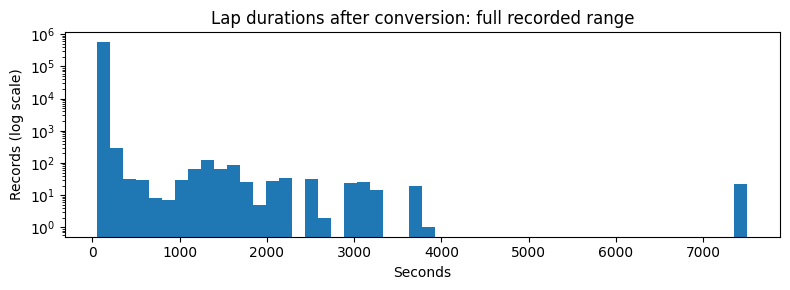

,raceId,driverId,lap,position,time,milliseconds,lap_seconds
8372,847,2,25,4,2:05:07.547,7507547,7507.547
8020,847,13,25,3,2:05:06.656,7506656,7506.656
8426,847,808,25,5,2:05:06.243,7506243,7506.243
8621,847,155,25,2,2:05:06.095,7506095,7506.095
7916,847,20,25,1,2:05:05.152,7505152,7505.152


In [84]:
lap_times_clean["lap_seconds"].plot.hist(bins=50, logy=True, figsize=(8, 3))
plt.title("Lap durations after conversion: full recorded range")
plt.xlabel("Seconds")
plt.ylabel("Records (log scale)")
plt.tight_layout()
plt.show()
display(lap_times_clean.nlargest(5, "lap_seconds"))

All 589,081 laps remain, with no missing values or repeated keys. The long duration tail is visible rather than clipped. Unusually long records are retained; their causes are not inferred from duration alone.

## 14. Pit stops
The key is `(raceId, driverId, stop)`. Check references and numeric ranges; convert duration to seconds and clock time to a time value.

In [85]:
pit_stops_clean = pit_stops.copy()

display(pit_stops_clean.head())

print("Number of pit stops:", len(pit_stops_clean))

pit_stops_clean.info()

,raceId,driverId,stop,lap,time,duration,milliseconds
0,841,153,1,1,17:05:23,26.898,26898
1,841,30,1,1,17:05:52,25.021,25021
2,841,17,1,11,17:20:48,23.426,23426
3,841,4,1,12,17:22:34,23.251,23251
4,841,13,1,13,17:24:10,23.842,23842


Number of pit stops: 11371
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11371 entries, 0 to 11370
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   raceId        11371 non-null  int64 
 1   driverId      11371 non-null  int64 
 2   stop          11371 non-null  int64 
 3   lap           11371 non-null  int64 
 4   time          11371 non-null  object
 5   duration      11371 non-null  object
 6   milliseconds  11371 non-null  int64 
dtypes: int64(5), object(2)
memory usage: 622.0+ KB


In [86]:
print("Missing values:")
print(pit_stops_clean.isna().sum())

print(
    "Repeated driver-race-stop combinations:",
    pit_stops_clean.duplicated(
        ["raceId", "driverId", "stop"]
    ).sum()
)

print(
    "Completely repeated rows:",
    pit_stops_clean.duplicated().sum()
)

print(
    "Unknown race IDs:",
    (~pit_stops_clean["raceId"].isin(races_clean["raceId"])).sum()
)

print(
    "Unknown driver IDs:",
    (~pit_stops_clean["driverId"].isin(drivers_clean["driverId"])).sum()
)

Missing values:
raceId          0
driverId        0
stop            0
lap             0
time            0
duration        0
milliseconds    0
dtype: int64
Repeated driver-race-stop combinations: 0
Completely repeated rows: 0
Unknown race IDs: 0
Unknown driver IDs: 0


In [87]:
display(pit_stops_clean[["stop", "lap", "milliseconds"]].describe())

display(pit_stops_clean[
    (pit_stops_clean["stop"] <= 0)
    | (pit_stops_clean["lap"] < 0)
    | (pit_stops_clean["milliseconds"] <= 0)
])

,stop,lap,milliseconds
count,11371.000000,11371.000000,1.137100e+04
mean,1.787969,25.387389,8.523050e+04
std,1.521462,14.831497,3.104273e+05
min,1.000000,1.000000,1.289700e+04
25%,1.000000,13.000000,2.193750e+04
50%,2.000000,25.000000,2.360600e+04
75%,2.000000,36.000000,2.654400e+04
max,70.000000,78.000000,3.069017e+06


,raceId,driverId,stop,lap,time,duration,milliseconds


In [88]:
# Convert recorded duration from milliseconds to seconds
pit_stops_clean["duration_seconds"] = (
    pit_stops_clean["milliseconds"] / 1000
)

# Convert the recorded clock time into a time value
pit_stops_clean["time"] = pd.to_datetime(
    pit_stops_clean["time"],
    format="%H:%M:%S"
).dt.time

display(pit_stops_clean.nlargest(10, "duration_seconds")[
    ["raceId", "driverId", "stop", "lap", "duration", "duration_seconds"]
])

,raceId,driverId,stop,lap,duration,duration_seconds
9156,1083,840,1,1,51:09.017,3069.017
9155,1083,20,1,1,51:07.301,3067.301
9157,1083,854,1,1,51:05.174,3065.174
9154,1083,825,1,1,51:03.613,3063.613
9152,1083,817,1,1,51:03.314,3063.314
9151,1083,822,1,1,50:55.732,3055.732
9147,1083,4,1,1,50:55.700,3055.700
9150,1083,849,1,1,50:51.904,3051.904
9153,1083,842,1,1,50:48.950,3048.950
9145,1083,1,1,1,50:46.888,3046.888


In [89]:
compare_cleaning(pit_stops, pit_stops_clean)

Rows: 11,371 → 11,371
Columns: 7 → 8


,Type before,Type after,Missing before,Missing after
driverId,int64,int64,0.0,0
duration,object,object,0.0,0
duration_seconds,—,float64,—,0
lap,int64,int64,0.0,0
milliseconds,int64,int64,0.0,0
raceId,int64,int64,0.0,0
stop,int64,int64,0.0,0
time,object,object,0.0,0


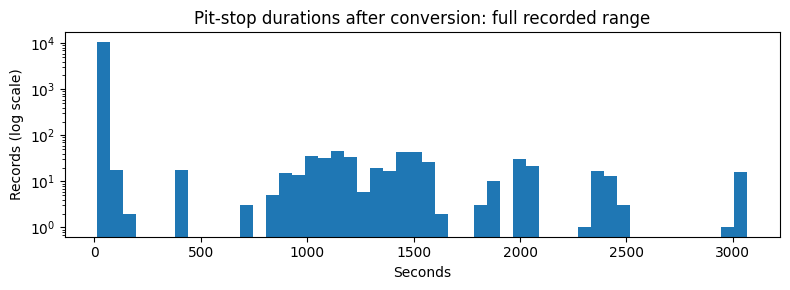

In [90]:
pit_stops_clean["duration_seconds"].plot.hist(bins=50, logy=True, figsize=(8, 3))
plt.title("Pit-stop durations after conversion: full recorded range")
plt.xlabel("Seconds")
plt.ylabel("Records (log scale)")
plt.tight_layout()
plt.show()

All 11,371 records remain. No missing values, repeated keys or nonpositive durations were found. Long durations and unusual stop counts are left intact; they require context before exclusion.

## 15. Overall comparison and final audit
The following tables summarize the completed dataset sections. Missing-value totals compare shared columns only, so dropping a column is not presented as filling its values.

In [91]:
# Match each original table with its cleaned version
table_pairs = [
    ("results", results, results_clean),
    ("drivers", drivers, drivers_clean),
    ("constructors", constructors, constructors_clean),
    ("circuits", circuits, circuits_clean),
    ("races", races, races_clean),
    ("status", status, status_clean),
    ("seasons", seasons, seasons_clean),
    ("qualifying", qualifying, qualifying_clean),
    ("driver_standings", driver_standings, driver_standings_clean),
    ("constructor_standings", constructor_standings, constructor_standings_clean),
    ("constructor_results", constructor_results, constructor_results_clean),
    ("sprint_results", sprint_results, sprint_results_clean),
    ("lap_times", lap_times, lap_times_clean),
    ("pit_stops", pit_stops, pit_stops_clean)
]

summary_rows = []

for name, original, cleaned in table_pairs:
    # Identify columns removed from the working copy
    removed_columns = original.columns.difference(cleaned.columns)

    summary_rows.append({
        "File": name,
        "Rows before": len(original),
        "Rows after": len(cleaned),
        "Columns before": len(original.columns),
        "Columns after": len(cleaned.columns),
        "Removed columns": ", ".join(removed_columns)
    })

cleaning_summary = pd.DataFrame(summary_rows).set_index("File")

display(cleaning_summary)

,Rows before,Rows after,Columns before,Columns after,Removed columns
File,,,,,
results,26759,26759,18,22,
drivers,861,861,9,6,"code, number, url"
constructors,212,212,5,4,url
circuits,77,77,9,8,url
races,1125,1125,18,7,"fp1_date, fp1_time, fp2_date, fp2_time, fp3_da..."
status,139,139,2,2,
seasons,75,75,2,1,url
qualifying,10494,10494,9,12,
driver_standings,34863,34863,7,7,


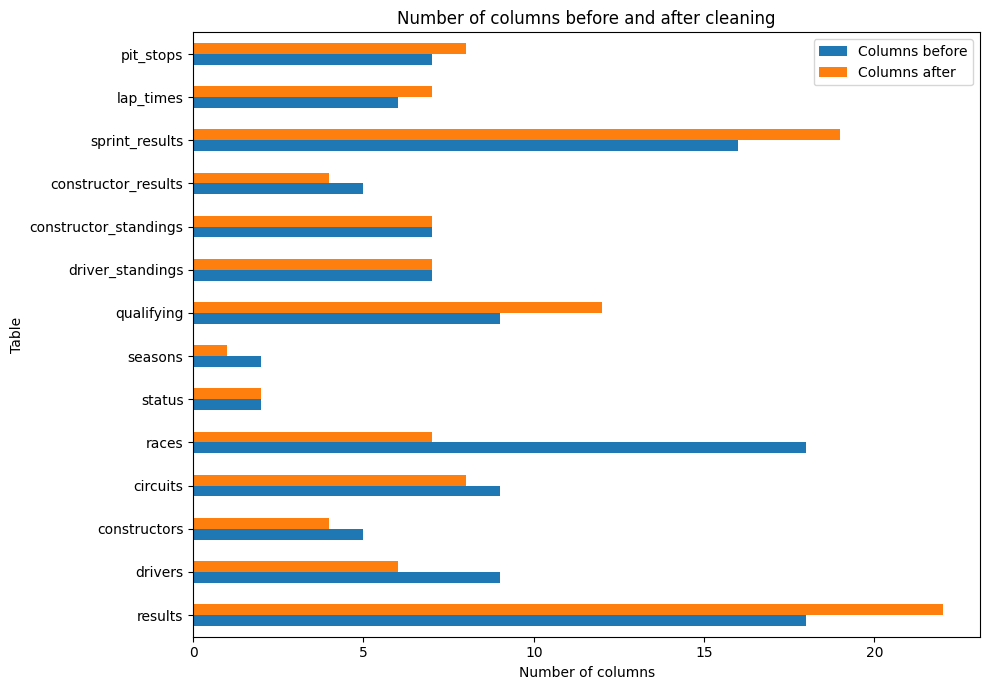

In [92]:
cleaning_summary[
    ["Columns before", "Columns after"]
].plot.barh(figsize=(10, 7))

plt.title("Number of columns before and after cleaning")
plt.xlabel("Number of columns")
plt.ylabel("Table")
plt.tight_layout()
plt.show()

In [93]:
missing_rows = []

for name, original, cleaned in table_pairs:
    # Compare only columns present in both versions
    common_columns = original.columns.intersection(cleaned.columns)

    missing_rows.append({
        "File": name,
        "Before cleaning": original[common_columns].isna().sum().sum(),
        "After cleaning": cleaned[common_columns].isna().sum().sum()
    })

missing_summary = pd.DataFrame(missing_rows).set_index("File")

display(missing_summary)

,Before cleaning,After cleaning
File,,
results,122887,123143
drivers,0,0
constructors,0,0
circuits,0,0
races,731,731
status,0,0
seasons,0,0
qualifying,11668,11668
driver_standings,0,0


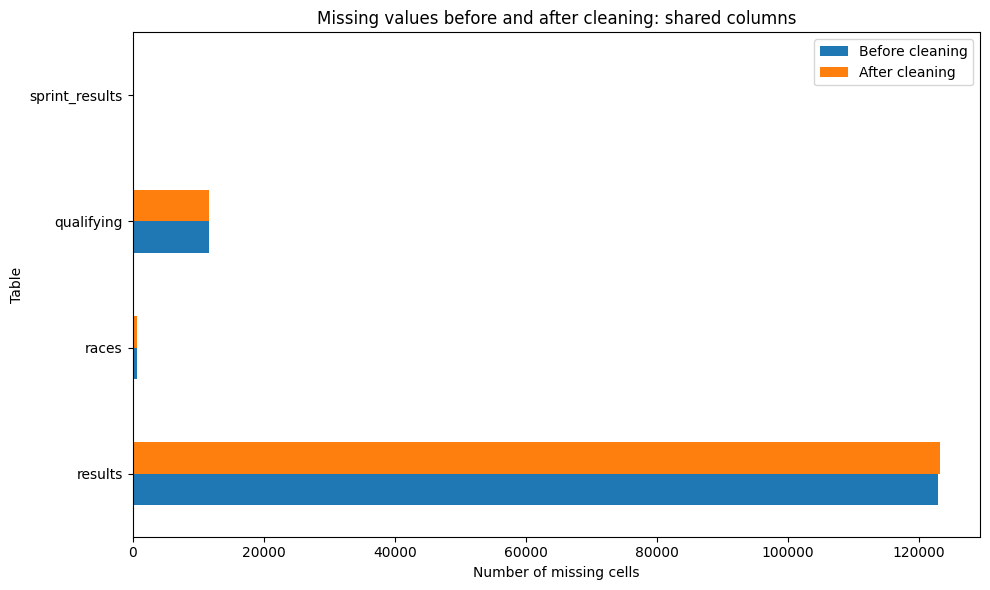

In [94]:
# Only display tables that contain missing values
tables_with_missing = missing_summary[
    (missing_summary > 0).any(axis=1)
]

tables_with_missing.plot.barh(figsize=(10, 6))

plt.title("Missing values before and after cleaning: shared columns")
plt.xlabel("Number of missing cells")
plt.ylabel("Table")
plt.tight_layout()
plt.show()

Row counts are unchanged in all 14 cleaned tables. Columns decrease where fields were deliberately removed and increase where numeric durations or an analysis grid were added. Only the supported position and rank changes alter missingness in retained source columns.

In [95]:
primary_keys = {
    "results": ["resultId"], "drivers": ["driverId"],
    "constructors": ["constructorId"], "circuits": ["circuitId"],
    "races": ["raceId"], "status": ["statusId"], "seasons": ["year"],
    "qualifying": ["qualifyId"], "driver_standings": ["driverStandingsId"],
    "constructor_standings": ["constructorStandingsId"],
    "constructor_results": ["constructorResultsId"], "sprint_results": ["resultId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"]
}
references = {
    "raceId": races_clean["raceId"], "driverId": drivers_clean["driverId"],
    "constructorId": constructors_clean["constructorId"],
    "circuitId": circuits_clean["circuitId"], "statusId": status_clean["statusId"],
    "year": seasons_clean["year"]
}

audit_rows = []
for name, original, cleaned in table_pairs:
    keys = primary_keys[name]
    missing_keys = cleaned[keys].isna().any(axis=1).sum()
    repeated_keys = cleaned.duplicated(keys).sum()
    invalid_references = sum(
        (~cleaned[column].isin(valid_ids)).sum()
        for column, valid_ids in references.items() if column in cleaned
    )
    sentinel_count = cleaned.select_dtypes(include=["object", "string"]).eq(r"\N").sum().sum()
    audit_rows.append({
        "Table": name, "Missing keys": missing_keys, "Repeated keys": repeated_keys,
        "Invalid references": invalid_references, "Literal sentinel values": sentinel_count,
        "Result": "PASS" if missing_keys + repeated_keys + invalid_references + sentinel_count == 0 else "FAIL"
    })

audit_report = pd.DataFrame(audit_rows).set_index("Table")
display(audit_report)

,Missing keys,Repeated keys,Invalid references,Literal sentinel values,Result
Table,,,,,
results,0,0,0,0.0,PASS
drivers,0,0,0,0.0,PASS
constructors,0,0,0,0.0,PASS
circuits,0,0,0,0.0,PASS
races,0,0,0,0.0,PASS
status,0,0,0,0.0,PASS
seasons,0,0,0,0.0,PASS
qualifying,0,0,0,0.0,PASS
driver_standings,0,0,0,0.0,PASS


In [96]:
checks = {
    "Birth dates are datetime": pd.api.types.is_datetime64_any_dtype(drivers_clean["dob"]),
    "Race dates are datetime": pd.api.types.is_datetime64_any_dtype(races_clean["date"]),
    "Race clock times are typed": races_clean["time"].dropna().map(lambda x: isinstance(x, clock_time)).all(),
    "Pit clock times are typed": pit_stops_clean["time"].map(lambda x: isinstance(x, clock_time)).all(),
    "Unique driver–race outcomes": not driver_race_outcomes.duplicated(["raceId", "driverId"]).any(),
    "Complete outcome IDs and finishing orders": driver_race_outcomes[["raceId", "driverId", "positionOrder"]].notna().all().all(),
    "Analysis grids positive or missing": results_clean["grid_for_analysis"].dropna().gt(0).all(),
    "Every source row retained": all(len(before) == len(after) for _, before, after in table_pairs)
}
for name, _, cleaned in table_pairs:
    for column in cleaned:
        if column.endswith("_seconds"):
            checks[f"{name}: {column} is numeric"] = pd.api.types.is_numeric_dtype(cleaned[column])

display(pd.Series(checks, name="Result").map({True: "PASS", False: "FAIL"}).to_frame())
assert audit_report["Result"].eq("PASS").all(), "Review failed table checks."
assert all(checks.values()), "Review failed type or outcome checks."

,Result
Birth dates are datetime,PASS
Race dates are datetime,PASS
Race clock times are typed,PASS
Pit clock times are typed,PASS
Unique driver–race outcomes,PASS
Complete outcome IDs and finishing orders,PASS
Analysis grids positive or missing,PASS
Every source row retained,PASS
results: fastest_lap_seconds is numeric,PASS
results: reported_elapsed_seconds is numeric,PASS


## Stage 1 status

Cleaning notes, before/after EDA and implemented key, reference, sentinel,
type and grain checks are included above. All detailed source rows are retained.
The full-notebook execution record is supplied with the submission files.

**PENDING - TA GUIDANCE REQUIRED:** constructor selection for 16 historical
driver-race groups; treatment of 12 flagged lap records and 20 timing records.
Their original values remain unchanged. A passing structural audit does not
resolve these questions.

Constructor conflicts occur outside the 2003-2024 modeling period, where the
constructor lookup is unique. The disputed lap and timing fields are not final
model inputs. Earlier descriptive analyses retain their stated limitations;
Question 1 includes a sensitivity check for repeated historical entries.

Cleaned DataFrames are recreated by Run All. Saved outputs alone do not restore
kernel variables. The following sections complete the later milestone stages.

# Stage 2 - Data-Engineering Questions

## Question 1 - Circuit front-row conversion

In [97]:
# Add the race year and circuit ID
q1_data = driver_race_outcomes.merge(
    races_clean[["raceId", "year", "circuitId"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

# Add the circuit name
q1_data = q1_data.merge(
    circuits_clean[["circuitId", "name"]],
    on="circuitId",
    how="left",
    validate="many_to_one"
).rename(columns={"name": "circuit_name"})

# Check that the information required for this question is complete
assert q1_data[
    ["raceId", "driverId", "year", "circuitId", "circuit_name", "positionOrder"]
].notna().all().all()

assert not q1_data.duplicated(["raceId", "driverId"]).any()

q1_data.head()

,raceId,driverId,positionOrder,grid_for_analysis,year,circuitId,circuit_name
0,1,1,20,18,2009,1,Albert Park Grand Prix Circuit
1,1,2,10,9,2009,1,Albert Park Grand Prix Circuit
2,1,3,6,5,2009,1,Albert Park Grand Prix Circuit
3,1,4,5,10,2009,1,Albert Park Grand Prix Circuit
4,1,5,19,12,2009,1,Albert Park Grand Prix Circuit


In [98]:
# A podium means finishing first, second or third
q1_data["podium"] = q1_data["positionOrder"].between(1, 3)

# Separate the two periods; 2014 belongs to the hybrid era
q1_data["period"] = "Before 2014"
q1_data.loc[q1_data["year"] >= 2014, "period"] = "2014 onward"

# Include only drivers whose recorded starting grid is 1 or 2
front_row = q1_data[
    q1_data["grid_for_analysis"].isin([1, 2])
].copy()

print("Front-row starts included:", len(front_row))

Front-row starts included: 2259


In [99]:
def calculate_conversion(data, group_columns):
    summary = data.groupby(group_columns, as_index=False).agg(
        front_row_starts=("driverId", "size"),
        podium_finishes=("podium", "sum")
    )

    summary["conversion_rate"] = (
        summary["podium_finishes"]
        / summary["front_row_starts"]
        * 100
    )

    return summary


# Overall circuit ranking
overall_conversion = calculate_conversion(
    front_row,
    ["circuitId", "circuit_name"]
).sort_values(
    ["conversion_rate", "front_row_starts"],
    ascending=[False, False]
)

display(overall_conversion.round(2).head(10))

# Separate circuit rankings for the two periods
period_conversion = calculate_conversion(
    front_row,
    ["circuitId", "circuit_name", "period"]
)

# Equal conversion rates receive equal ranks
period_conversion["rank"] = (
    period_conversion.groupby("period")["conversion_rate"]
    .rank(method="min", ascending=False)
    .astype(int)
)

display(
    period_conversion.sort_values(["period", "rank"]).round(2)
)

,circuitId,circuit_name,front_row_starts,podium_finishes,conversion_rate
75,79,Miami International Autodrome,6,6,100.00
71,75,Autódromo Internacional do Algarve,4,4,100.00
76,80,Las Vegas Strip Street Circuit,4,4,100.00
29,31,Donington Park,2,2,100.00
62,64,Ain Diab,2,2,100.00
63,65,Pescara Circuit,2,2,100.00
72,76,Autodromo Internazionale del Mugello,2,2,100.00
73,77,Jeddah Corniche Circuit,8,7,87.50
67,69,Circuit of the Americas,24,20,83.33
66,68,Buddh International Circuit,6,5,83.33


,circuitId,circuit_name,period,front_row_starts,podium_finishes,conversion_rate,rank
95,75,Autódromo Internacional do Algarve,2014 onward,4,4,100.00,1
96,76,Autodromo Internazionale del Mugello,2014 onward,2,2,100.00,1
99,79,Miami International Autodrome,2014 onward,6,6,100.00,1
100,80,Las Vegas Strip Street Circuit,2014 onward,4,4,100.00,1
38,22,Suzuka Circuit,2014 onward,18,16,88.89,5
...,...,...,...,...,...,...,...
64,44,Las Vegas Street Circuit,Before 2014,4,1,25.00,65
72,52,Circuit Mont-Tremblant,Before 2014,4,1,25.00,65
69,49,Montjuïc,Before 2014,8,1,12.50,67
77,57,Zeltweg,Before 2014,2,0,0.00,68


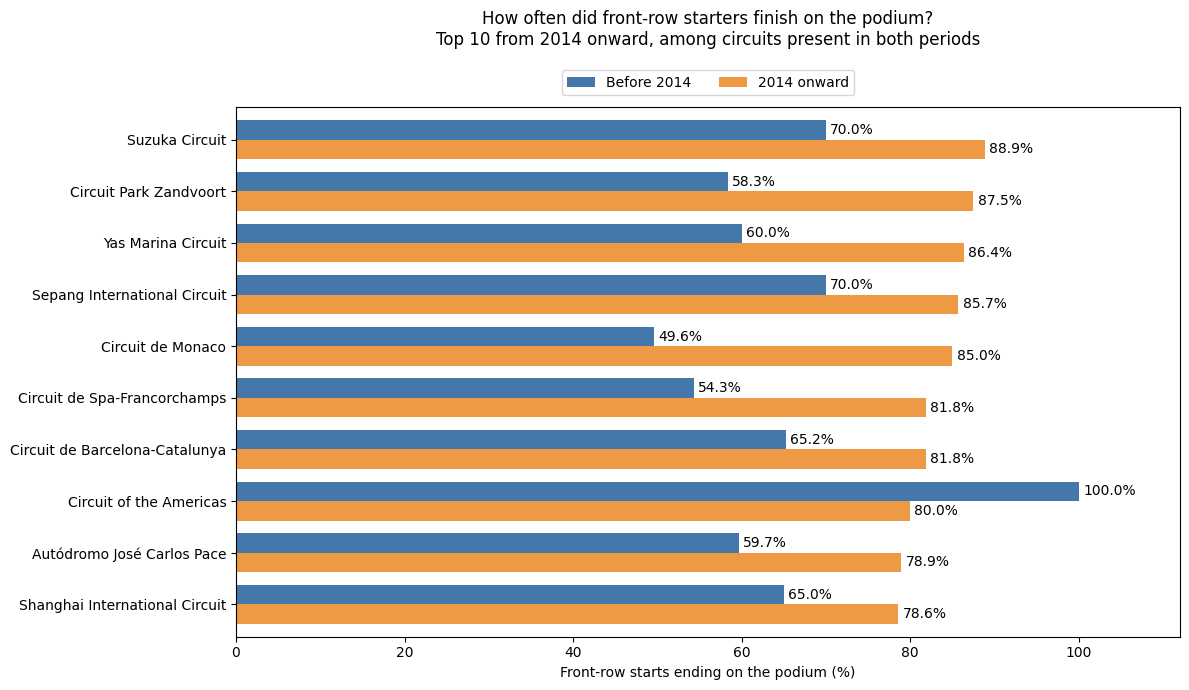

,Front-row starts,Before 2014,2014 onward
circuitId,circuit_name,,
22,Suzuka Circuit,50,18
39,Circuit Park Zandvoort,60,8
24,Yas Marina Circuit,10,22
2,Sepang International Circuit,30,7
6,Circuit de Monaco,121,20
13,Circuit de Spa-Francorchamps,92,22
4,Circuit de Barcelona-Catalunya,46,22
69,Circuit of the Americas,4,20
18,Autódromo José Carlos Pace,62,19


In [100]:
# Put both periods beside each other
comparison = period_conversion.pivot(
    index=["circuitId", "circuit_name"],
    columns="period",
    values=["front_row_starts", "conversion_rate"]
)

# Compare only circuits with records in both periods
comparison = comparison.dropna(
    subset=[
        ("conversion_rate", "Before 2014"),
        ("conversion_rate", "2014 onward")
    ]
)

# Show the top 10 eligible circuits by their rate from 2014 onward
comparison = comparison.sort_values(
    ("conversion_rate", "2014 onward"),
    ascending=False
).head(10)

# Prepare the percentages for the chart
chart_data = comparison["conversion_rate"][
    ["Before 2014", "2014 onward"]
].copy()

chart_data.index = comparison.index.get_level_values("circuit_name")

# Draw two bars for each circuit
ax = chart_data.plot.barh(
    figsize=(12, 7),
    color=["#4477AA", "#EE9944"],
    width=0.75
)

# Write the percentage beside each bar
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=3)

# Put the highest-ranked circuit at the top
ax.invert_yaxis()

ax.set_title(
    "How often did front-row starters finish on the podium?\n"
    "Top 10 from 2014 onward, among circuits present in both periods",
    pad=45
)
ax.set_xlabel("Front-row starts ending on the podium (%)")
ax.set_ylabel("")
ax.set_xlim(0, 112)
ax.set_xticks([0, 20, 40, 60, 80, 100])

# Keep the legend outside the bars
ax.legend(
    title="",
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=2
)

plt.tight_layout()
plt.show()

# Show sample sizes separately to keep the chart readable
display(
    comparison["front_row_starts"][
        ["Before 2014", "2014 onward"]
    ].astype(int).rename_axis(
        columns="Front-row starts"
    )
)

In [101]:
# Find driver–race pairs that originally had multiple entries
repeated_pairs = (
    results_clean.groupby(["raceId", "driverId"])
    .size()
    .rename("entry_count")
    .reset_index()
)

# Attach the original entry count to each front-row starter
front_row_checked = front_row.merge(
    repeated_pairs,
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

# Recalculate using only single-entry driver–race pairs
single_entry_conversion = calculate_conversion(
    front_row_checked[front_row_checked["entry_count"] == 1],
    ["circuitId", "circuit_name", "period"]
)

single_entry_conversion["rank"] = (
    single_entry_conversion.groupby("period")["conversion_rate"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Compare the main result with the single-entry calculation
historical_check = period_conversion.merge(
    single_entry_conversion,
    on=["circuitId", "circuit_name", "period"],
    how="left",
    suffixes=("_all", "_single_entry"),
    validate="one_to_one"
)

historical_check["rate_change_pp"] = (
    historical_check["conversion_rate_single_entry"]
    - historical_check["conversion_rate_all"]
)

display(historical_check.round(2))

,circuitId,circuit_name,period,front_row_starts_all,podium_finishes_all,conversion_rate_all,rank_all,front_row_starts_single_entry,podium_finishes_single_entry,conversion_rate_single_entry,rank_single_entry,rate_change_pp
0,1,Albert Park Grand Prix Circuit,2014 onward,18,13,72.22,23,18,13,72.22,23,0.0
1,1,Albert Park Grand Prix Circuit,Before 2014,36,20,55.56,35,36,20,55.56,35,0.0
2,2,Sepang International Circuit,2014 onward,7,6,85.71,9,7,6,85.71,9,0.0
3,2,Sepang International Circuit,Before 2014,30,21,70.00,11,30,21,70.00,12,0.0
4,3,Bahrain International Circuit,2014 onward,24,16,66.67,25,24,16,66.67,25,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
96,76,Autodromo Internazionale del Mugello,2014 onward,2,2,100.00,1,2,2,100.00,1,0.0
97,77,Jeddah Corniche Circuit,2014 onward,8,7,87.50,6,8,7,87.50,6,0.0
98,78,Losail International Circuit,2014 onward,6,3,50.00,30,6,3,50.00,30,0.0
99,79,Miami International Autodrome,2014 onward,6,6,100.00,1,6,6,100.00,1,0.0


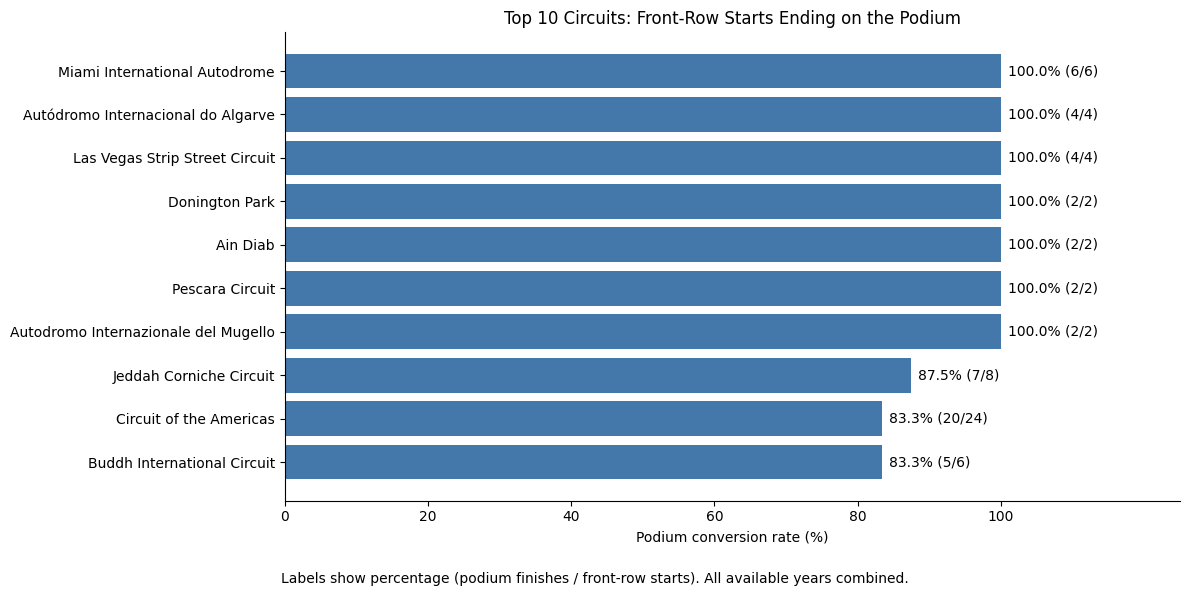

In [102]:
# Select the ten highest overall conversion rates
top_circuits = (
    overall_conversion
    .sort_values(
        ["conversion_rate", "front_row_starts"],
        ascending=[False, False]
    )
    .head(10)
)

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.barh(
    top_circuits["circuit_name"],
    top_circuits["conversion_rate"],
    color="#4477AA"
)

# Show both the percentage and the evidence behind it
labels = [
    f"{rate:.1f}% ({podiums}/{starts})"
    for rate, podiums, starts in zip(
        top_circuits["conversion_rate"],
        top_circuits["podium_finishes"],
        top_circuits["front_row_starts"]
    )
]

ax.bar_label(bars, labels=labels, padding=5)

# Put the highest rates at the top
ax.invert_yaxis()

ax.set_title("Top 10 Circuits: Front-Row Starts Ending on the Podium")
ax.set_xlabel("Podium conversion rate (%)")
ax.set_ylabel("")
ax.set_xlim(0, 125)  # Leave space for the labels
ax.set_xticks([0, 20, 40, 60, 80, 100])

ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.5, 0.02,
    "Labels show percentage (podium finishes / front-row starts). "
    "All available years combined.",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

## Question 1 — Front-Row Starts and Podium Finishes

### Approach

We examined which circuits most often turn a front-row start into a podium finish, comparing **before 2014** with **2014 onward**.

- Joined the driver–race summary to the races and circuits tables.
- Defined a front-row start as **grid position 1 or 2** and a podium as **finishing order 1, 2 or 3**.
- Used starting grid rather than qualifying position because penalties can change where a driver starts.
- Excluded missing starting grids because front-row participation could not be determined.
- Counted driver appearances across races, not unique drivers.

For each circuit and period:

**Conversion rate = podium finishes among front-row starters ÷ total front-row starts × 100**

We ranked circuits by this percentage. The comparison chart shows two bars per circuit, using circuits represented in both periods.

### Results

Across all years, **Miami, Algarve, Las Vegas Strip, Donington Park, Ain Diab, Pescara and Mugello** recorded 100% conversion. However, each result is based on only **two to six front-row starts**, so these perfect rates have limited supporting evidence.

Before 2014, **Circuit of the Americas, Donington Park, Ain Diab and Pescara** shared the highest rate of 100%.

From 2014 onward, **Miami, Algarve, Las Vegas Strip and Mugello** shared the highest rate of 100%. Suzuka followed with **16 podiums from 18 front-row starts (88.89%)**.

The rankings changed between periods. Examples among circuits present in both periods are:

| Circuit | Before 2014 | 2014 onward | Rank before → after |
|---|---:|---:|---:|
| Suzuka | 70.00% | 88.89% | 11 → 5 |
| Yas Marina | 60.00% | 86.36% | 25 → 8 |
| Monaco | 49.59% | 85.00% | 55 → 10 |
| Circuit of the Americas | 100.00% | 80.00% | 1 → 14 |

Ranks are relative to the circuits available in each period; equal percentages share a rank.

### Historical Entries and Limitations

Our historical summary selects the best grid and best finish independently, which can combine values from different entries. We therefore repeated the calculation without multiple-entry driver–race groups.

This changed some earlier results substantially. For example, Bremgarten increased from **63.64% to 87.50%** when these groups were excluded. The 2014-onward results were unchanged. Historical rankings therefore require caution.

**Conclusion:** The observed circuit rankings differ across the two periods. However, small sample sizes, changes in the circuits represented, and historical aggregation rules affect the comparison. These results describe an association; they do not establish that the hybrid era caused the changes.

## Question 2 - Home-country advantage

In [103]:
# Inspect country labels without changing the original table
country_labels = (
    circuits_clean["country"]
    .str.strip()
    .dropna()
    .unique()
)

# Inspect nationality labels
nationality_labels = (
    drivers_clean["nationality"]
    .str.strip()
    .dropna()
    .unique()
)

print("Circuit countries:")
print(sorted(country_labels))

print("\nDriver nationalities:")
print(sorted(nationality_labels))

Circuit countries:
['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States']

Driver nationalities:
['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Uruguayan', 'Venezuelan']


In [104]:
# Create a separate lookup without changing circuits_clean
circuit_countries = circuits_clean[["circuitId", "country"]].copy()

country_mapping = {
    "USA": "United States",
    "UK": "United Kingdom",
    "UAE": "United Arab Emirates"
}

# Remove extra spaces and standardize country labels
circuit_countries["standard_country"] = (
    circuit_countries["country"]
    .str.strip()
    .replace(country_mapping)
)

circuit_countries.head()

,circuitId,country,standard_country
0,1,Australia,Australia
1,2,Malaysia,Malaysia
2,3,Bahrain,Bahrain
3,4,Spain,Spain
4,5,Turkey,Turkey


In [105]:
nationality_mapping = {
    "American": "United States",
    "Argentine": "Argentina",
    "Argentinian": "Argentina",
    "Australian": "Australia",
    "Austrian": "Austria",
    "Belgian": "Belgium",
    "Brazilian": "Brazil",
    "British": "United Kingdom",
    "Canadian": "Canada",
    "Chilean": "Chile",
    "Chinese": "China",
    "Colombian": "Colombia",
    "Czech": "Czech Republic",
    "Danish": "Denmark",
    "Dutch": "Netherlands",
    "Finnish": "Finland",
    "French": "France",
    "German": "Germany",
    "Hungarian": "Hungary",
    "Indian": "India",
    "Indonesian": "Indonesia",
    "Irish": "Ireland",
    "Italian": "Italy",
    "Japanese": "Japan",
    "Liechtensteiner": "Liechtenstein",
    "Malaysian": "Malaysia",
    "Mexican": "Mexico",
    "Monegasque": "Monaco",
    "New Zealander": "New Zealand",
    "Polish": "Poland",
    "Portuguese": "Portugal",
    "Russian": "Russia",
    "South African": "South Africa",
    "Spanish": "Spain",
    "Swedish": "Sweden",
    "Swiss": "Switzerland",
    "Thai": "Thailand",
    "Uruguayan": "Uruguay",
    "Venezuelan": "Venezuela"
}

# Create a separate driver-country lookup
driver_countries = drivers_clean[
    ["driverId", "nationality"]
].copy()

# Labels not in the dictionary remain missing
driver_countries["home_country"] = (
    driver_countries["nationality"]
    .str.strip()
    .map(nationality_mapping)
)

driver_countries.head()

,driverId,nationality,home_country
0,1,British,United Kingdom
1,2,German,Germany
2,3,German,Germany
3,4,Spanish,Spain
4,5,Finnish,Finland


In [106]:
# Count drivers whose home country remains unresolved
unmapped_drivers = driver_countries[
    driver_countries["home_country"].isna()
]

display(
    unmapped_drivers.groupby("nationality")
    .size()
    .rename("Number of drivers")
    .to_frame()
)

print("Drivers with unresolved home countries:", len(unmapped_drivers))

,Number of drivers
nationality,
American-Italian,1
Argentine-Italian,1
East German,3
Rhodesian,4


Drivers with unresolved home countries: 9


In [107]:
# Store each nationality's home countries as a list
home_country_mapping = {}

for nationality, country in nationality_mapping.items():
    home_country_mapping[nationality] = [country]

# Add dual nationalities and the agreed historical mappings
home_country_mapping.update({
    "American-Italian": ["United States", "Italy"],
    "Argentine-Italian": ["Argentina", "Italy"],
    "East German": ["Germany"],
    "Rhodesian": ["Zimbabwe"]
})

# Rebuild the lookup without changing drivers_clean
driver_countries = drivers_clean[
    ["driverId", "nationality"]
].copy()

driver_countries["home_countries"] = (
    driver_countries["nationality"]
    .str.strip()
    .map(home_country_mapping)
)

# Confirm that every driver has a mapping
print(
    "Drivers without a country mapping:",
    driver_countries["home_countries"].isna().sum()
)

# Inspect the four special cases
display(
    driver_countries[
        driver_countries["nationality"].isin([
            "American-Italian",
            "Argentine-Italian",
            "East German",
            "Rhodesian"
        ])
    ]
)

Drivers without a country mapping: 0


,driverId,nationality,home_countries
339,340,Rhodesian,[Zimbabwe]
367,368,Rhodesian,[Zimbabwe]
413,414,Rhodesian,[Zimbabwe]
473,473,Rhodesian,[Zimbabwe]
491,491,American-Italian,"[United States, Italy]"
573,573,Argentine-Italian,"[Argentina, Italy]"
709,709,East German,[Germany]
710,710,East German,[Germany]
713,713,East German,[Germany]


In [108]:
# Start with one row per driver per race
q2_data = driver_race_outcomes.merge(
    driver_countries[["driverId", "home_countries"]],
    on="driverId",
    how="left",
    validate="many_to_one"
)

# Find the circuit where each race took place
q2_data = q2_data.merge(
    races_clean[["raceId", "circuitId"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

# Add the standardized circuit country
q2_data = q2_data.merge(
    circuit_countries[["circuitId", "standard_country"]],
    on="circuitId",
    how="left",
    validate="many_to_one"
)

assert not q2_data.duplicated(["raceId", "driverId"]).any()

In [109]:
# Identify appearances with enough information for the comparison
usable_rows = (
    q2_data["home_countries"].notna()
    & q2_data["standard_country"].notna()
    & q2_data["grid_for_analysis"].gt(0).fillna(False)
)

print("Appearances excluded:", (~usable_rows).sum())

q2_data = q2_data.loc[usable_rows].copy()

# Confirm that finishing orders are available
assert q2_data["positionOrder"].notna().all()

Appearances excluded: 1635


In [110]:
# Check whether the circuit country belongs to the driver's home countries
q2_data["is_home"] = q2_data.apply(
    lambda row: row["standard_country"] in row["home_countries"],
    axis=1
)

q2_data["race_location"] = q2_data["is_home"].map({
    True: "Home",
    False: "Away"
})

# Finishing first, second or third counts as a podium
q2_data["podium"] = q2_data["positionOrder"].between(1, 3)

q2_data[
    ["driverId", "raceId", "home_countries", "standard_country",
     "race_location", "grid_for_analysis", "podium"]
].head()

,driverId,raceId,home_countries,standard_country,race_location,grid_for_analysis,podium
0,1,1,[United Kingdom],Australia,Away,18,False
1,2,1,[Germany],Australia,Away,9,False
2,3,1,[Germany],Australia,Away,5,False
3,4,1,[Spain],Australia,Away,10,False
4,5,1,[Finland],Australia,Away,12,False


In [111]:
# Count appearances and podiums for each starting position
grid_summary = q2_data.groupby(
    ["grid_for_analysis", "race_location"],
    as_index=False
).agg(
    appearances=("driverId", "size"),
    podiums=("podium", "sum")
)

grid_summary["podium_rate"] = (
    grid_summary["podiums"]
    / grid_summary["appearances"]
    * 100
)

# Put home and away percentages beside each other
grid_rates = grid_summary.pivot(
    index="grid_for_analysis",
    columns="race_location",
    values="podium_rate"
).reindex(columns=["Home", "Away"])

# Keep sample sizes beside the percentages
grid_counts = grid_summary.pivot(
    index="grid_for_analysis",
    columns="race_location",
    values="appearances"
).reindex(columns=["Home", "Away"])

display(grid_summary.round(2))

,grid_for_analysis,race_location,appearances,podiums,podium_rate
0,1,Away,1040,673,64.71
1,1,Home,95,56,58.95
2,2,Away,1034,581,56.19
3,2,Home,90,48,53.33
4,3,Away,1044,479,45.88
...,...,...,...,...,...
61,31,Home,12,0,0.00
62,32,Away,3,0,0.00
63,32,Home,13,1,7.69
64,33,Home,11,0,0.00


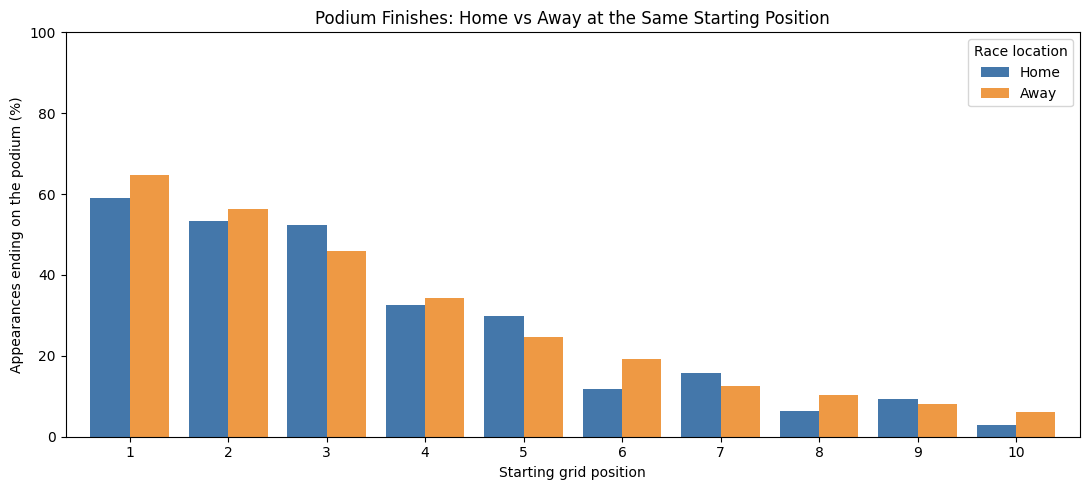

race_location,Home,Away
Starting grid,,
1,95,1040
2,90,1034
3,82,1044
4,86,1044
5,84,1044
6,94,1026
7,89,1038
8,93,1035
9,107,1020


In [112]:
# Compare only grid positions with both home and away appearances
comparable_rates = grid_rates.dropna().sort_index()

chart_data = comparable_rates.loc[
    comparable_rates.index <= 10
]

ax = chart_data.plot.bar(
    figsize=(11, 5),
    color=["#4477AA", "#EE9944"],
    width=0.8
)

ax.set_title("Podium Finishes: Home vs Away at the Same Starting Position")
ax.set_xlabel("Starting grid position")
ax.set_ylabel("Appearances ending on the podium (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Race location")

plt.tight_layout()
plt.show()

# Show how many appearances support the displayed bars
display(
    grid_counts.loc[chart_data.index]
    .astype(int)
    .rename_axis("Starting grid")
)

In [113]:
# Count appearances at positions represented in both groups
common_counts = grid_counts.loc[comparable_rates.index]

# More frequently observed grid positions receive more weight
grid_weights = common_counts.sum(axis=1)
grid_weights = grid_weights / grid_weights.sum()

# Apply exactly the same weights to home and away rates
adjusted_rates = comparable_rates.mul(
    grid_weights,
    axis=0
).sum()

display(
    adjusted_rates.round(2)
    .rename("Grid-adjusted podium rate (%)")
    .to_frame()
)

# Positive means the adjusted home rate is higher
difference = adjusted_rates["Home"] - adjusted_rates["Away"]

print(
    f"Home minus away: {difference:+.2f} percentage points"
)

print(
    "Appearances included in the adjusted comparison:",
    int(common_counts.sum().sum())
)

,Grid-adjusted podium rate (%)
race_location,
Home,13.24
Away,13.60


Home minus away: -0.36 percentage points
Appearances included in the adjusted comparison: 25021


## Question 2 — Home-Country Podium Advantage

### Approach

We investigated whether drivers finished on the podium more often in their home country than elsewhere, while accounting for starting position.

- Joined the driver–race summary with driver nationalities and circuit countries.
- Standardized country names and converted nationalities into home countries.
- Counted either country as home for dual-nationality drivers, without duplicating appearances.
- Mapped East German to Germany and Rhodesian to Zimbabwe.
- Defined a podium as finishing first, second or third.
- Excluded appearances with missing or unavailable starting grids.

We compared home and away podium percentages at each starting position. The chart displays positions 1–10 for readability.

For the overall comparison, we used all grid positions represented in both groups and applied the same starting-position weights to Home and Away. This prevents differences in their starting-grid distributions from driving the comparison.

### Results

The overall adjusted comparison included **25,021 driver–race appearances**.

| Race location | Grid-adjusted podium rate |
|---|---:|
| Home | 13.24% |
| Away | 13.60% |

The adjusted home rate was **0.36 percentage points lower** than the away rate.

Results varied by starting position. For example, home drivers had a higher podium rate when starting third, but a lower rate when starting first or second.

### Conclusion

**This analysis did not show an overall home-country podium advantage after accounting for starting grid.** The adjusted percentages were close, with a slightly higher rate for away appearances.

This is a descriptive finding, not proof that racing at home helps or harms performance. We did not test statistical significance or control for driver ability, team strength or season. The analysis also retains our documented historical driver–race aggregation rules.

## Question 3 - Constructor mechanical retirements

In [114]:
# Add the year of each race
q3_data = results_clean.merge(
    races_clean[["raceId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

# Add constructor names
q3_data = q3_data.merge(
    constructors_clean[["constructorId", "name"]],
    on="constructorId",
    how="left",
    validate="many_to_one"
).rename(columns={"name": "constructor_name"})

# Add the reason each race entry ended
q3_data = q3_data.merge(
    status_clean,
    on="statusId",
    how="left",
    validate="many_to_one"
)

# Keep the years required by the question
q3_data = q3_data[
    q3_data["year"].between(2014, 2024)
].copy()

# Check the information needed for counting
assert q3_data[
    ["raceId", "driverId", "constructorId", "constructor_name", "status"]
].notna().all().all()

assert not q3_data.duplicated(["raceId", "driverId"]).any()

# Define the two periods
q3_data["period"] = "2014–2021"
q3_data.loc[q3_data["year"] >= 2022, "period"] = "2022–2024"

In [115]:
# Identify entries recorded as withdrawn
withdrawn = (
    q3_data["positionText"].eq("W")
    | q3_data["status"].eq("Withdrew")
)

# Exclude withdrawals only when no laps were completed
did_not_start = withdrawn & q3_data["laps"].eq(0)

# Inspect the excluded entries
display(
    q3_data.loc[
        did_not_start,
        ["resultId", "year", "constructor_name",
         "positionText", "status", "laps"]
    ]
)

# Create the working table without changing q3_data
race_starts = q3_data.loc[~did_not_start].copy()

print("Entries before filtering:", len(q3_data))
print("Withdrawals excluded:", did_not_start.sum())
print("Estimated race starts retained:", len(race_starts))

,resultId,year,constructor_name,positionText,status,laps
22170,22173,2014,Force India,W,Withdrew,0
22258,22261,2014,Lotus F1,W,Withdrew,0
22434,22438,2014,Caterham,W,Power Unit,0
22549,22553,2015,Red Bull,W,Withdrew,0
22550,22554,2015,McLaren,W,Withdrew,0
22551,22555,2015,Williams,W,Withdrew,0
22571,22575,2015,Manor Marussia,W,Fuel system,0
22611,22615,2015,McLaren,W,ERS,0
22711,22715,2015,Sauber,W,Gearbox,0
22751,22755,2015,Force India,W,Power loss,0


Entries before filtering: 4626
Withdrawals excluded: 28
Estimated race starts retained: 4598


In [116]:
# Statuses counted as mechanical failures in this analysis
mechanical_statuses = [
    "Engine", "Gearbox", "Transmission", "Clutch",
    "Hydraulics", "Electrical", "Radiator", "Brakes",
    "Differential", "Overheating", "Mechanical", "Driveshaft",
    "Fuel pressure", "Water pressure", "Throttle", "Steering",
    "Electronics", "Exhaust", "Oil leak", "Water leak",
    "Fuel pump", "Oil pressure", "Fuel system", "Power loss",
    "Drivetrain", "Battery", "Fuel leak", "Turbo",
    "Water pump", "Spark plugs", "Power Unit", "ERS",
    "Cooling system"
]

# Causes excluded from the mechanical-failure count
non_mechanical_statuses = [
    "Accident", "Collision", "Collision damage", "Spun off",
    "Disqualified", "Excluded", "Out of fuel", "Illness", "Debris"
]

# "Finished" and "+1 Lap", "+2 Laps", etc. represent finishers
finished = (
    race_starts["status"].eq("Finished")
    | race_starts["status"].str.match(r"^\+\d+ Laps?$")
)

race_starts["mechanical_retirement"] = (
    race_starts["status"].isin(mechanical_statuses)
)

# Keep uncertain causes visible instead of calling them mechanical
race_starts["unclear_cause"] = ~(
    finished
    | race_starts["mechanical_retirement"]
    | race_starts["status"].isin(non_mechanical_statuses)
)

display(
    race_starts.loc[
        race_starts["unclear_cause"], "status"
    ].value_counts().rename("Appearances needing cause review")
)

status
Retired       49
Suspension    25
Wheel         11
Puncture       7
Tyre           4
Undertray      4
Rear wing      3
Withdrew       3
Front wing     3
Wheel nut      3
Technical      2
Damage         2
Vibrations     2
Brake duct     1
Seat           1
Name: Appearances needing cause review, dtype: int64

In [117]:
constructor_rates = race_starts.groupby(
    ["constructorId", "constructor_name", "period"],
    as_index=False
).agg(
    race_starts=("resultId", "size"),
    mechanical_retirements=("mechanical_retirement", "sum"),
    unclear_causes=("unclear_cause", "sum")
)

# Mechanical retirements as a percentage of all starts
constructor_rates["mechanical_rate"] = (
    constructor_rates["mechanical_retirements"]
    / constructor_rates["race_starts"]
    * 100
)

# Rank constructors separately within each period
constructor_rates["rank"] = (
    constructor_rates.groupby("period")["mechanical_rate"]
    .rank(method="min", ascending=False)
    .astype(int)
)

display(
    constructor_rates.sort_values(
        ["period", "rank"]
    ).round(2)
)

,constructorId,constructor_name,period,race_starts,mechanical_retirements,unclear_causes,mechanical_rate,rank
21,208,Lotus F1,2014–2021,75,13,5,17.33,1
20,207,Caterham,2014–2021,33,5,5,15.15,2
5,5,Toro Rosso,2014–2021,242,35,9,14.46,3
4,4,Renault,2014–2021,199,24,7,12.06,4
0,1,McLaren,2014–2021,316,38,11,12.03,5
11,15,Sauber,2014–2021,199,20,6,10.05,6
8,9,Red Bull,2014–2021,318,31,6,9.75,7
23,210,Haas F1 Team,2014–2021,241,17,13,7.05,8
28,214,Alpine F1 Team,2014–2021,44,3,1,6.82,9
25,211,Racing Point,2014–2021,75,5,2,6.67,10


In [118]:
for period in ["2014–2021", "2022–2024"]:
    print(period)

    top_constructors = (
        constructor_rates[constructor_rates["period"] == period]
        .sort_values(
            ["mechanical_rate", "race_starts"],
            ascending=[False, False]
        )
        .head(5)
    )

    display(
        top_constructors[
            ["constructor_name", "race_starts",
             "mechanical_retirements", "unclear_causes",
             "mechanical_rate"]
        ].round(2)
    )

2014–2021


,constructor_name,race_starts,mechanical_retirements,unclear_causes,mechanical_rate
21,Lotus F1,75,13,5,17.33
20,Caterham,33,5,5,15.15
5,Toro Rosso,242,35,9,14.46
4,Renault,199,24,7,12.06
0,McLaren,316,38,11,12.03


2022–2024


,constructor_name,race_starts,mechanical_retirements,unclear_causes,mechanical_rate
14,Alfa Romeo,88,10,1,11.36
29,Alpine F1 Team,135,14,0,10.37
27,AlphaTauri,88,5,2,5.68
3,Williams,134,7,4,5.22
7,Ferrari,134,6,3,4.48


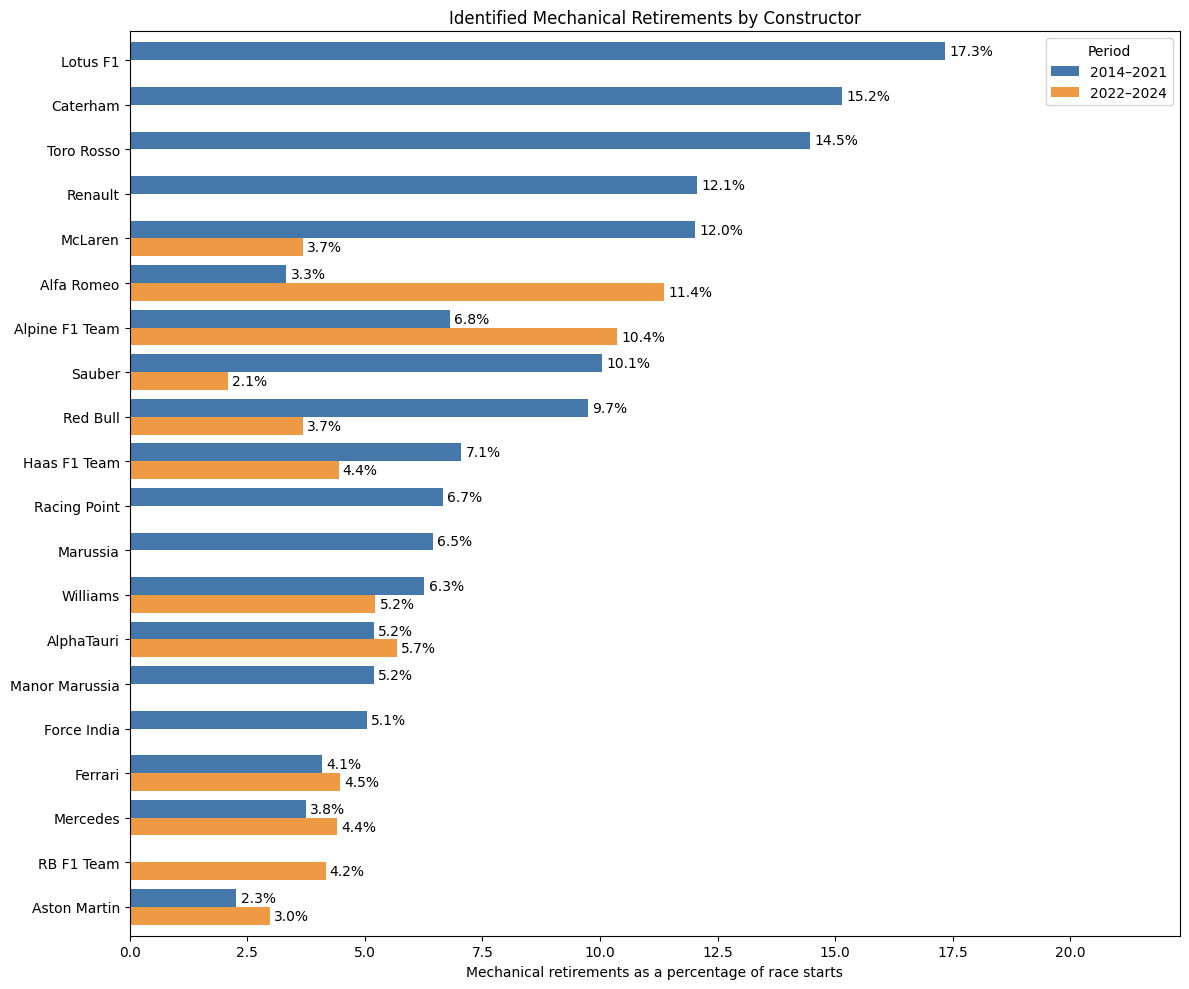

In [119]:
# Put the two periods beside each other
plot_data = constructor_rates.pivot(
    index="constructor_name",
    columns="period",
    values="mechanical_rate"
)[["2014–2021", "2022–2024"]]

# Put constructors with the highest rate in either period first
constructor_order = (
    plot_data.max(axis=1)
    .sort_values(ascending=False)
    .index
)

plot_data = plot_data.loc[constructor_order]

ax = plot_data.plot.barh(
    figsize=(12, 10),
    color=["#4477AA", "#EE9944"],
    width=0.8
)

# Label recorded rates; leave absent constructor-periods blank
for bars, period in zip(ax.containers, plot_data.columns):
    labels = [
        "" if pd.isna(value) else f"{value:.1f}%"
        for value in plot_data[period]
    ]
    ax.bar_label(bars, labels=labels, padding=3)

ax.invert_yaxis()
ax.set_title("Identified Mechanical Retirements by Constructor")
ax.set_xlabel("Mechanical retirements as a percentage of race starts")
ax.set_ylabel("")
ax.set_xlim(0, plot_data.max().max() + 5)
ax.legend(title="Period")

plt.tight_layout()
plt.show()

## Question 3 — Constructor Mechanical-Retirement Rates

### Approach

We compared constructor mechanical-retirement rates between **2014–2021** and **2022–2024**, using only the provided dataset.

- Joined race results with race years, constructor names and status descriptions.
- Excluded entries recorded as withdrawn with zero completed laps, leaving **4,598 estimated race starts**.
- Used an explicit list of mechanical-status labels, including engine, gearbox, electrical and hydraulic failures.
- Excluded accidents, driver-related causes and regulation decisions from the mechanical-failure count.
- Kept unclear causes separate rather than assuming they were mechanical.
- Kept different constructor IDs separate rather than combining renamed teams.

For each constructor and period:

**Mechanical-retirement rate = identified mechanical retirements ÷ estimated race starts × 100**

Each driver–race appearance counts separately. Two cars from the same constructor starting a race contribute two starts.

### Results

The five highest rates in each period were:

| Period | Constructor | Mechanical retirements | Estimated starts | Rate |
|---|---|---:|---:|---:|
| 2014–2021 | Lotus F1 | 13 | 75 | 17.33% |
| 2014–2021 | Caterham | 5 | 33 | 15.15% |
| 2014–2021 | Toro Rosso | 35 | 242 | 14.46% |
| 2014–2021 | Renault | 24 | 199 | 12.06% |
| 2014–2021 | McLaren | 38 | 316 | 12.03% |
| 2022–2024 | Alfa Romeo | 10 | 88 | 11.36% |
| 2022–2024 | Alpine F1 Team | 14 | 135 | 10.37% |
| 2022–2024 | AlphaTauri | 5 | 88 | 5.68% |
| 2022–2024 | Williams | 7 | 134 | 5.22% |
| 2022–2024 | Ferrari | 6 | 134 | 4.48% |

**Lotus F1 had the highest identified mechanical-retirement rate in 2014–2021, while Alfa Romeo had the highest in 2022–2024.**

The chart compares both periods for each constructor. A higher bar indicates a larger percentage of starts ending in an identified mechanical retirement. An absent constructor-period is not treated as a zero rate.

### Limitations

These are **status-based estimates**. The dataset cannot always distinguish a failure before the start from a first-lap retirement.

There were **98 unclear causes in 2014–2021 and 22 in 2022–2024**. These appearances remain in the denominator but are not counted as identified mechanical failures; resolving them could change the rankings.

Sample sizes also differ between constructors, so percentages based on fewer starts should be interpreted cautiously.

# Stage 3 - Feature Selection and Engineering

In [120]:
# Add the year to each driver–race appearance
coverage_data = driver_race_outcomes.merge(
    races_clean[["raceId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

# Add qualifying information
coverage_data = coverage_data.merge(
    qualifying_clean[
        ["raceId", "driverId", "position", "q1_seconds"]
    ].rename(columns={"position": "qualifying_position"}),
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

# Identify which information is available
coverage_data["has_grid"] = (
    coverage_data["grid_for_analysis"].gt(0).fillna(False)
)

coverage_data["has_qualifying"] = (
    coverage_data["qualifying_position"].notna()
)

coverage_data["has_q1"] = coverage_data["q1_seconds"].notna()

In [121]:
# Count races and appearances, then calculate availability
yearly_coverage = coverage_data.groupby("year").agg(
    races=("raceId", "nunique"),
    driver_entries=("driverId", "size"),
    grid_coverage=("has_grid", "mean"),
    qualifying_coverage=("has_qualifying", "mean"),
    q1_coverage=("has_q1", "mean")
)

# Convert availability from proportions into percentages
coverage_columns = [
    "grid_coverage",
    "qualifying_coverage",
    "q1_coverage"
]

yearly_coverage[coverage_columns] = (
    yearly_coverage[coverage_columns] * 100
)

# Show every year
with pd.option_context("display.max_rows", None):
    display(yearly_coverage.round(2))

,races,driver_entries,grid_coverage,qualifying_coverage,q1_coverage
year,,,,,
1950,7,156,100.0,0.00,0.00
1951,8,175,100.0,0.00,0.00
1952,8,212,94.34,0.00,0.00
1953,9,230,100.0,0.00,0.00
1954,9,213,98.59,0.00,0.00
1955,7,162,95.68,0.00,0.00
1956,8,178,95.51,0.00,0.00
1957,8,163,96.93,0.00,0.00
1958,11,238,93.28,0.00,0.00


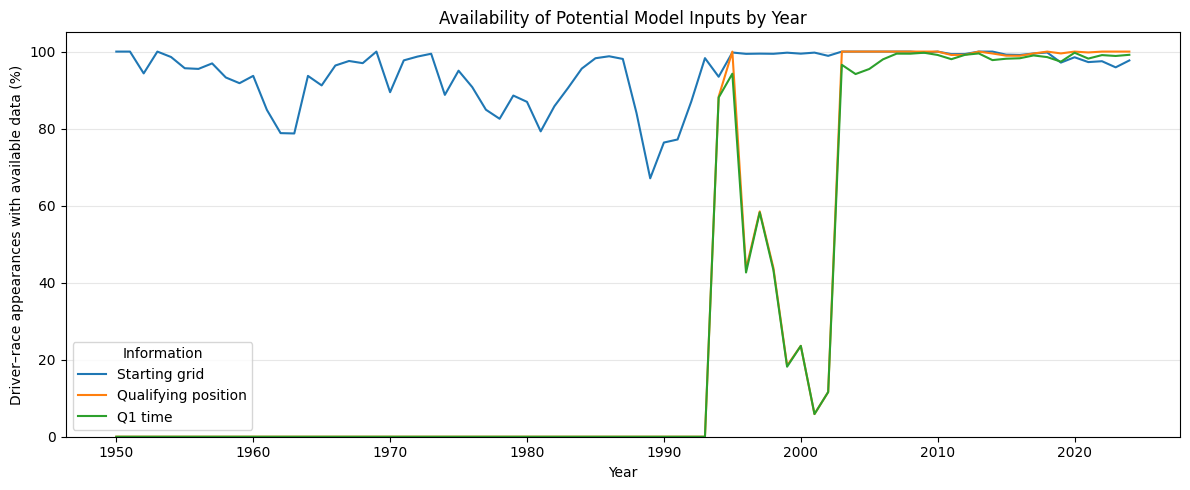

In [122]:
# Use readable labels for the chart
chart_data = yearly_coverage[coverage_columns].rename(
    columns={
        "grid_coverage": "Starting grid",
        "qualifying_coverage": "Qualifying position",
        "q1_coverage": "Q1 time"
    }
)

chart_data.plot(figsize=(12, 5))

plt.title("Availability of Potential Model Inputs by Year")
plt.xlabel("Year")
plt.ylabel("Driver–race appearances with available data (%)")
plt.ylim(0, 105)
plt.legend(title="Information")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Choose the modeling period and chronological split

In [123]:
# Add race information to the unique driver–race outcomes
model_base = driver_race_outcomes.merge(
    races_clean[
        ["raceId", "year", "round", "date", "circuitId"]
    ],
    on="raceId",
    how="left",
    validate="many_to_one"
)

# Keep the selected modeling years
model_base = model_base[
    model_base["year"].between(2003, 2024)
].copy()

# Confirm that each appearance has a recorded outcome
assert model_base["positionOrder"].notna().all()

# Create the answer that the models will learn to predict
model_base["podium"] = (
    model_base["positionOrder"].between(1, 3)
).astype(int)

# Put appearances in chronological order
model_base = model_base.sort_values(
    ["date", "raceId", "driverId"]
).reset_index(drop=True)

model_base.head()

,raceId,driverId,positionOrder,grid_for_analysis,year,round,date,circuitId,podium
0,108,2,15,7,2003,1,2003-03-09,1,0
1,108,4,7,10,2003,1,2003-03-09,1,0
2,108,8,3,15,2003,1,2003-03-09,1,1
3,108,14,1,11,2003,1,2003-03-09,1,1
4,108,15,5,12,2003,1,2003-03-09,1,0


In [124]:
# Assign earlier years to training
model_base["split"] = "Training"

# Use the next period for validation
model_base.loc[
    model_base["year"].between(2019, 2021),
    "split"
] = "Validation"

# Reserve the latest period for final testing
model_base.loc[
    model_base["year"].between(2022, 2024),
    "split"
] = "Test"

# Show the size and years of each dataset
split_summary = model_base.groupby("split").agg(
    first_year=("year", "min"),
    last_year=("year", "max"),
    races=("raceId", "nunique"),
    driver_appearances=("driverId", "size")
)

display(
    split_summary.reindex(["Training", "Validation", "Test"])
)

,first_year,last_year,races,driver_appearances
split,,,,
Training,2003,2018,300,6411
Validation,2019,2021,60,1200
Test,2022,2024,68,1359


In [125]:
# Each driver must appear once per race
assert not model_base.duplicated(["raceId", "driverId"]).any()

# All drivers in a race must belong to the same split
assert model_base.groupby("raceId")["split"].nunique().eq(1).all()

# Check that the periods follow chronological order
training_dates = model_base.loc[
    model_base["split"] == "Training", "date"
]

validation_dates = model_base.loc[
    model_base["split"] == "Validation", "date"
]

test_dates = model_base.loc[
    model_base["split"] == "Test", "date"
]

assert training_dates.max() < validation_dates.min()
assert validation_dates.max() < test_dates.min()

print("Passed: unique driver–race rows and separate chronological periods.")

Passed: unique driver–race rows and separate chronological periods.


### Dataset Split

We use a chronological split: 2003–2018 for training,
2019–2021 for validation, and 2022–2024 for testing.

This reflects the task of predicting future races from past information.
All driver entries from the same race remain in the same split.

Training data is used to learn preprocessing and model parameters.
Validation data supports model selection and tuning.
The test set is reserved for final evaluation.

Historical features use only information available before each race.
Changes across seasons are a limitation considered when interpreting
validation and test performance.

In [126]:
# Select qualifying positions and give the column a clear name
qualifying_positions = qualifying_clean[
    ["raceId", "driverId", "position"]
].rename(columns={"position": "qualifying_position"})

# Add qualifying position to a separate modeling table
model_features = model_base.merge(
    qualifying_positions,
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

# Positions are whole numbers, but missing values are allowed
model_features["qualifying_position"] = (
    model_features["qualifying_position"].astype("Int64")
)

# Check that the join did not add or remove appearances
assert len(model_features) == len(model_base)

model_features[
    ["raceId", "driverId", "grid_for_analysis",
     "qualifying_position", "podium", "split"]
].head()

,raceId,driverId,grid_for_analysis,qualifying_position,podium,split
0,108,2,7,7,0,Training
1,108,4,10,10,0,Training
2,108,8,15,15,1,Training
3,108,14,11,11,1,Training
4,108,15,12,12,0,Training


In [127]:
# Use training appearances for feature investigation
training_data = model_features[
    model_features["split"] == "Training"
].copy()

candidate_features = [
    "grid_for_analysis",
    "qualifying_position"
]

feature_missing = pd.DataFrame({
    "Missing count": training_data[candidate_features].isna().sum(),
    "Missing percentage": (
        training_data[candidate_features].isna().mean() * 100
    ).round(2)
})

display(feature_missing)

,Missing count,Missing percentage
grid_for_analysis,17,0.27
qualifying_position,21,0.33


Starting grid


,appearances,podium_rate
grid_for_analysis,,
1,300,79.33
2,299,62.21
3,300,50.00
4,300,31.33
5,300,21.67
6,300,16.00
7,300,10.33
8,300,5.33
9,300,4.33


Qualifying position


,appearances,podium_rate
qualifying_position,,
1,300,78.00
2,300,62.33
3,300,49.00
4,300,31.67
5,300,25.33
6,300,16.67
7,300,9.67
8,300,4.67
9,300,4.33


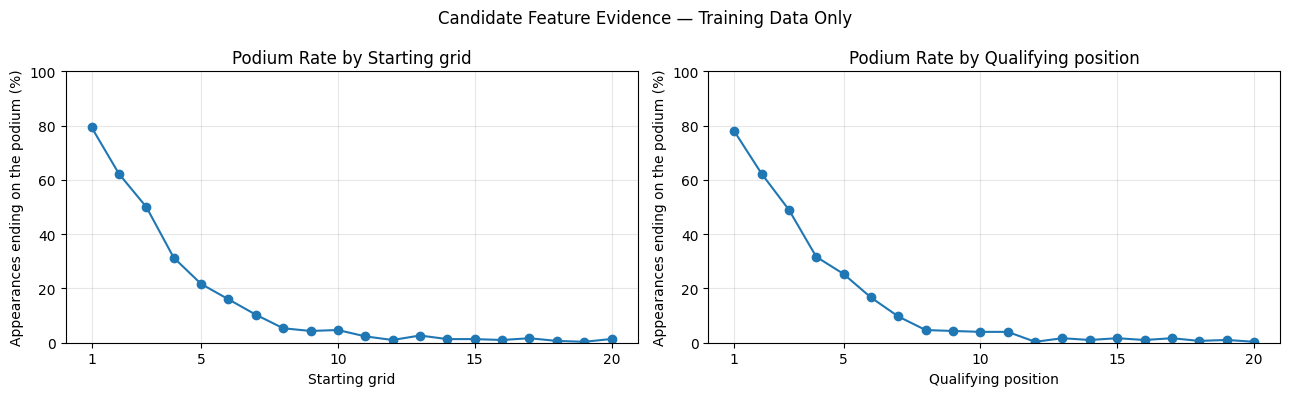

In [128]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, feature, label in zip(
    axes,
    candidate_features,
    ["Starting grid", "Qualifying position"]
):
    # Show positions 1–20 to keep the charts readable
    selected = training_data[
        training_data[feature].between(1, 20)
    ]

    # Calculate podium percentage and supporting appearance count
    position_summary = selected.groupby(feature).agg(
        appearances=("podium", "size"),
        podium_rate=("podium", "mean")
    )

    position_summary["podium_rate"] *= 100

    ax.plot(
        position_summary.index,
        position_summary["podium_rate"],
        marker="o"
    )

    ax.set_title(f"Podium Rate by {label}")
    ax.set_xlabel(label)
    ax.set_ylabel("Appearances ending on the podium (%)")
    ax.set_ylim(0, 100)
    ax.set_xticks([1, 5, 10, 15, 20])
    ax.grid(alpha=0.3)

    print(label)
    display(position_summary.round(2))

plt.suptitle("Candidate Feature Evidence — Training Data Only")
plt.tight_layout()
plt.show()

In [129]:
# Add race dates to the unique driver–race outcomes
driver_history = driver_race_outcomes[
    ["raceId", "driverId", "positionOrder"]
].merge(
    races_clean[["raceId", "date"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

# Put each driver's appearances in chronological order
driver_history = driver_history.sort_values(
    ["driverId", "date", "raceId"]
).copy()

driver_history["podium"] = (
    driver_history["positionOrder"].between(1, 3)
).astype(int)

history_groups = driver_history.groupby("driverId")

In [130]:
# Podium percentage across up to five previous appearances
driver_history["recent_podium_rate"] = (
    history_groups["podium"].transform(
        lambda values: values.shift(1).rolling(
            window=5, min_periods=1
        ).mean()
    ) * 100
)

# Average finishing order across the same previous appearances
driver_history["recent_avg_finish"] = (
    history_groups["positionOrder"].transform(
        lambda values: values.shift(1).rolling(
            window=5, min_periods=1
        ).mean()
    )
)

# Record how much history supports each calculation
driver_history["past_races_used"] = (
    history_groups.cumcount().clip(upper=5)
)

# Keep the previous race date for checking information availability
driver_history["previous_race_date"] = (
    history_groups["date"].shift(1)
)

In [131]:
form_features = [
    "recent_podium_rate",
    "recent_avg_finish",
    "past_races_used"
]

history_columns = form_features + ["previous_race_date"]

# Remove an earlier version if this cell is rerun
model_features = model_features.drop(
    columns=history_columns,
    errors="ignore"
)

model_features = model_features.merge(
    driver_history[
        ["raceId", "driverId"] + history_columns
    ],
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

# Previous information must come from an earlier date
assert (
    model_features["previous_race_date"].isna()
    | (
        model_features["previous_race_date"]
        < model_features["date"]
    )
).all()

assert model_features["past_races_used"].between(0, 5).all()

display(
    model_features[
        ["driverId", "date", "positionOrder"] + form_features
    ].sort_values(["driverId", "date"]).head(12).round(2)
)

,driverId,date,positionOrder,recent_podium_rate,recent_avg_finish,past_races_used
1452,1,2007-03-18,3,NaN,NaN,0
1474,1,2007-04-08,2,100.0,3.00,1
1496,1,2007-04-15,2,100.0,2.50,2
1518,1,2007-05-13,2,100.0,2.33,3
1540,1,2007-05-27,2,100.0,2.25,4
1562,1,2007-06-10,1,100.0,2.20,5
1584,1,2007-06-17,1,100.0,1.80,5
1606,1,2007-07-01,3,100.0,1.60,5
1628,1,2007-07-08,3,100.0,1.80,5
1650,1,2007-07-22,9,100.0,2.00,5


,appearances,current_podium_rate
recent_podium_rate,,
0.0,4075,3.19
20.0,763,19.79
40.0,470,39.79
60.0,385,46.75
80.0,246,65.85
100.0,121,68.60


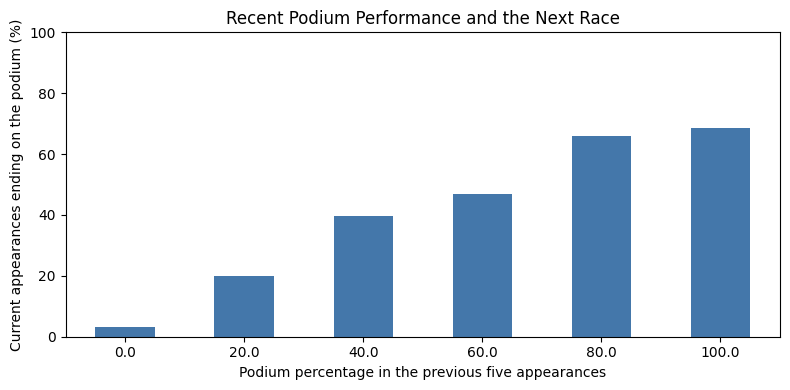

,count,mean,median
podium,,,
No podium,5167,11.87,12.2
Podium,893,6.12,5.8


In [132]:
training_form = model_features[
    (model_features["split"] == "Training")
    & (model_features["past_races_used"] == 5)
].copy()

# Compare recent podium performance with the current race outcome
form_summary = training_form.groupby(
    "recent_podium_rate"
).agg(
    appearances=("podium", "size"),
    current_podium_rate=("podium", "mean")
)

form_summary["current_podium_rate"] *= 100

display(form_summary.round(2))

ax = form_summary["current_podium_rate"].plot.bar(
    figsize=(8, 4),
    color="#4477AA"
)

ax.set_title("Recent Podium Performance and the Next Race")
ax.set_xlabel("Podium percentage in the previous five appearances")
ax.set_ylabel("Current appearances ending on the podium (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

# Compare previous average finishing orders by current outcome
display(
    training_form.groupby("podium")["recent_avg_finish"]
    .agg(["count", "mean", "median"])
    .rename(index={0: "No podium", 1: "Podium"})
    .round(2)
)

In [133]:
# Keep races that have recorded results
race_order = races_clean.loc[
    races_clean["raceId"].isin(results_clean["raceId"]),
    ["raceId", "year", "round"]
].sort_values(["year", "round"]).copy()

# Find the previous race, restarting at each new season
race_order["previous_raceId"] = (
    race_order.groupby("year")["raceId"]
    .shift(1)
    .astype("Int64")
)

race_order.head()

,raceId,year,round,previous_raceId
832,833,1950,1,<NA>
833,834,1950,2,833
834,835,1950,3,834
835,836,1950,4,835
836,837,1950,5,836


In [134]:
# Select and clearly name the standings information
previous_standings = driver_standings_clean[
    ["raceId", "driverId", "points", "position"]
].rename(columns={
    "raceId": "previous_raceId",
    "points": "driver_points_before_race",
    "position": "driver_standing_before_race"
})

standings_features = [
    "driver_points_before_race",
    "driver_standing_before_race"
]

# Allow this cell to be rerun without duplicating columns
model_features = model_features.drop(
    columns=standings_features + ["previous_raceId"],
    errors="ignore"
)

# Identify the previous race for each modeling appearance
model_features = model_features.merge(
    race_order[["raceId", "previous_raceId"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

# Match each driver to their standings after that previous race
model_features = model_features.merge(
    previous_standings,
    on=["previous_raceId", "driverId"],
    how="left",
    validate="many_to_one"
)

# Championship points begin at zero for the first race of the season
first_race = model_features["previous_raceId"].isna()

model_features.loc[
    first_race, "driver_points_before_race"
] = 0

display(
    model_features[
        ["driverId", "year", "round", "previous_raceId"]
        + standings_features
    ].sort_values(["driverId", "year", "round"]).head(12)
)

,driverId,year,round,previous_raceId,driver_points_before_race,driver_standing_before_race
1452,1,2007,1,<NA>,0.0,NaN
1474,1,2007,2,36,6.0,3.0
1496,1,2007,3,37,14.0,3.0
1518,1,2007,4,38,22.0,3.0
1540,1,2007,5,39,30.0,1.0
1562,1,2007,6,40,38.0,2.0
1584,1,2007,7,41,48.0,1.0
1606,1,2007,8,42,58.0,1.0
1628,1,2007,9,43,64.0,1.0
1650,1,2007,10,44,70.0,1.0


,appearances,podium_rate
driver_standing_before_race,,
1.0,284,66.55
2.0,284,56.34
3.0,283,42.05
4.0,281,34.88
5.0,284,34.15
6.0,280,20.36
7.0,278,10.43
8.0,277,10.47
9.0,278,3.60


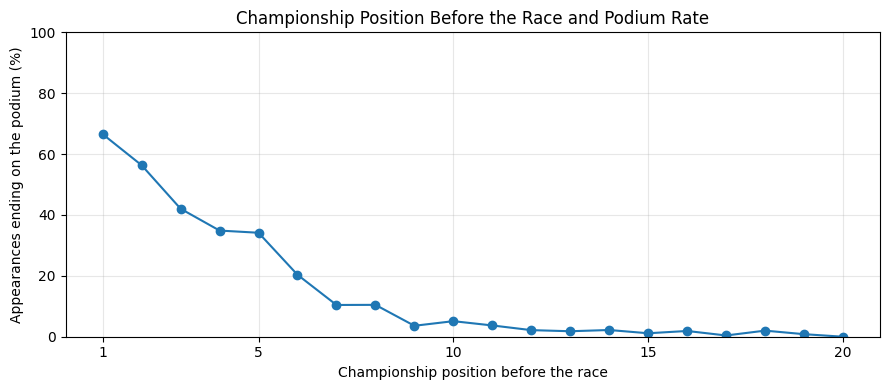

In [135]:
training_standings = model_features[
    model_features["split"] == "Training"
].copy()

# Examine championship positions 1–20
selected = training_standings[
    training_standings["driver_standing_before_race"].between(1, 20)
]

standing_summary = selected.groupby(
    "driver_standing_before_race"
).agg(
    appearances=("podium", "size"),
    podium_rate=("podium", "mean")
)

standing_summary["podium_rate"] *= 100

display(standing_summary.round(2))

ax = standing_summary["podium_rate"].plot(
    marker="o",
    figsize=(9, 4)
)

ax.set_title("Championship Position Before the Race and Podium Rate")
ax.set_xlabel("Championship position before the race")
ax.set_ylabel("Appearances ending on the podium (%)")
ax.set_ylim(0, 100)
ax.set_xticks([1, 5, 10, 15, 20])
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [136]:
# Select constructor information for our modeling races
constructor_lookup = results_clean.loc[
    results_clean["raceId"].isin(model_features["raceId"]),
    ["raceId", "driverId", "constructorId"]
].copy()

# Confirm that no constructor-selection rule is needed
assert not constructor_lookup.duplicated(
    ["raceId", "driverId"]
).any()

constructor_features = [
    "constructor_points_before_race",
    "constructor_standing_before_race"
]

# Allow this cell to be rerun
model_features = model_features.drop(
    columns=["constructorId"] + constructor_features,
    errors="ignore"
)

# Add the constructor for each driver–race appearance
model_features = model_features.merge(
    constructor_lookup,
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

assert model_features["constructorId"].notna().all()

In [137]:
# Select standings recorded after the previous race
previous_constructor_standings = constructor_standings_clean[
    ["raceId", "constructorId", "points", "position"]
].rename(columns={
    "raceId": "previous_raceId",
    "points": "constructor_points_before_race",
    "position": "constructor_standing_before_race"
})

model_features = model_features.merge(
    previous_constructor_standings,
    on=["previous_raceId", "constructorId"],
    how="left",
    validate="many_to_one"
)

# Each season begins with zero championship points
first_race = model_features["previous_raceId"].isna()

model_features.loc[
    first_race, "constructor_points_before_race"
] = 0

display(
    model_features[
        ["driverId", "constructorId", "year", "round"]
        + constructor_features
    ].head(12)
)

,driverId,constructorId,year,round,constructor_points_before_race,constructor_standing_before_race
0,2,15,2003,1,0.0,NaN
1,4,4,2003,1,0.0,NaN
2,8,1,2003,1,0.0,NaN
3,14,1,2003,1,0.0,NaN
4,15,4,2003,1,0.0,NaN
5,17,19,2003,1,0.0,NaN
6,18,16,2003,1,0.0,NaN
7,21,17,2003,1,0.0,NaN
8,22,6,2003,1,0.0,NaN
9,23,3,2003,1,0.0,NaN


,appearances,podium_rate
constructor_standing_before_race,,
1.0,568,57.57
2.0,568,39.26
3.0,568,26.58
4.0,568,11.09
5.0,568,4.58
6.0,568,2.64
7.0,566,2.12
8.0,564,1.24
9.0,557,0.72


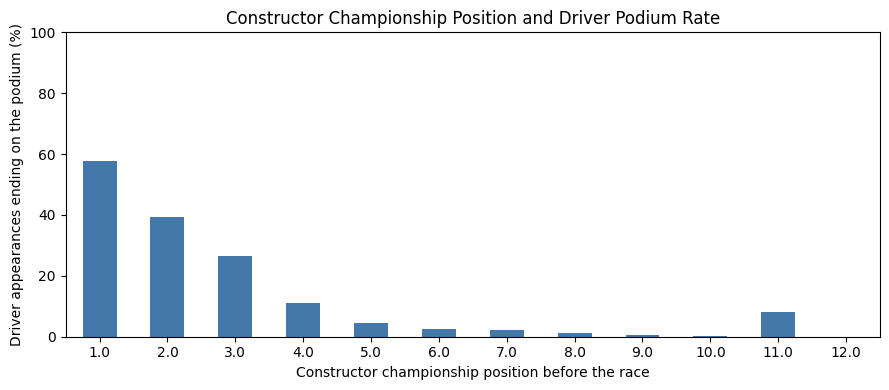

,count,mean,median
podium,,,
No podium,5479,47.35,15.0
Podium,900,169.89,117.5


In [138]:
# Investigate using training appearances only
training_constructor = model_features[
    model_features["split"] == "Training"
].copy()

constructor_summary = training_constructor.groupby(
    "constructor_standing_before_race"
).agg(
    appearances=("podium", "size"),
    podium_rate=("podium", "mean")
)

constructor_summary["podium_rate"] *= 100

display(constructor_summary.round(2))

ax = constructor_summary["podium_rate"].plot.bar(
    figsize=(9, 4),
    color="#4477AA"
)

ax.set_title("Constructor Championship Position and Driver Podium Rate")
ax.set_xlabel("Constructor championship position before the race")
ax.set_ylabel("Driver appearances ending on the podium (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

# Examine pre-race constructor points alongside podium outcomes
display(
    training_constructor.groupby("podium")[
        "constructor_points_before_race"
    ].agg(["count", "mean", "median"])
    .rename(index={0: "No podium", 1: "Podium"})
    .round(2)
)

In [139]:
# Numeric information describing position and performance
numeric_features = [
    "grid_for_analysis",
    "qualifying_position",
    "recent_podium_rate",
    "recent_avg_finish",
    "past_races_used",
    "driver_points_before_race",
    "driver_standing_before_race",
    "constructor_points_before_race",
    "constructor_standing_before_race"
]

# Constructor IDs identify categories, not numerical strength
categorical_features = ["constructorId"]

feature_columns = numeric_features + categorical_features

# Refresh the training data to include all newly added features
training_data = model_features[
    model_features["split"] == "Training"
].copy()

In [140]:
feature_review = pd.DataFrame({
    "Stored dtype": training_data[feature_columns].dtypes.astype(str),
    "Missing count": training_data[feature_columns].isna().sum(),
    "Missing percentage": (
        training_data[feature_columns].isna().mean() * 100
    ).round(2),
    "Distinct values": training_data[feature_columns].nunique()
})

feature_review["Role"] = (
    ["Numeric"] * len(numeric_features)
    + ["Categorical"] * len(categorical_features)
)

display(feature_review)

,Stored dtype,Missing count,Missing percentage,Distinct values,Role
grid_for_analysis,Int64,17,0.27,24,Numeric
qualifying_position,Int64,21,0.33,24,Numeric
recent_podium_rate,float64,72,1.12,9,Numeric
recent_avg_finish,float64,72,1.12,164,Numeric
past_races_used,int64,0,0.00,6,Numeric
driver_points_before_race,float64,132,2.06,306,Numeric
driver_standing_before_race,float64,474,7.39,27,Numeric
constructor_points_before_race,float64,32,0.50,409,Numeric
constructor_standing_before_race,float64,374,5.83,12,Numeric
constructorId,int64,0,0.00,29,Categorical


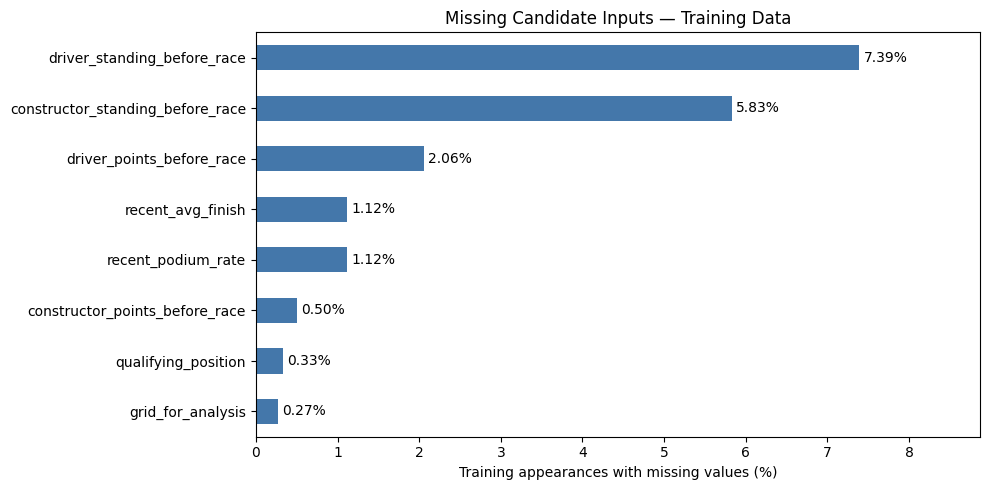

,count,mean,std,min,25%,50%,75%,max
grid_for_analysis,6394.0,11.223647,6.254349,1.0,6.0,11.0,16.75,24.0
qualifying_position,6390.0,11.209233,6.246029,1.0,6.0,11.0,16.0,24.0
recent_podium_rate,6339.0,14.135773,25.175035,0.0,0.0,0.0,20.0,100.0
recent_avg_finish,6339.0,11.184025,4.53435,1.0,7.8,11.6,14.6,24.0
past_races_used,6411.0,4.834815,0.762219,0.0,5.0,5.0,5.0,5.0
driver_points_before_race,6279.0,32.602564,54.38317,0.0,0.0,10.0,39.0,383.0
driver_standing_before_race,5937.0,11.331312,6.496258,1.0,6.0,11.0,17.0,27.0
constructor_points_before_race,6379.0,64.639128,104.681962,0.0,2.0,21.0,76.0,722.0
constructor_standing_before_race,6037.0,5.854729,3.122037,1.0,3.0,6.0,8.0,12.0


In [141]:
# Show only features with missing values
missing_features = feature_review[
    feature_review["Missing count"] > 0
]

ax = missing_features["Missing percentage"].sort_values().plot.barh(
    figsize=(10, 5),
    color="#4477AA"
)

ax.set_title("Missing Candidate Inputs — Training Data")
ax.set_xlabel("Training appearances with missing values (%)")
ax.set_ylabel("")

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f%%", padding=3)

ax.margins(x=0.2)

plt.tight_layout()
plt.show()

# Inspect the different numerical scales
display(
    training_data[numeric_features]
    .describe()
    .T.round(2)
)

In [142]:
# Calculate medians using training data only
training_medians = training_data[numeric_features].median()

display(
    training_medians.rename("Training median").to_frame()
)

# Identify features that have missing values in training
missing_numeric_features = [
    column for column in numeric_features
    if training_data[column].isna().any()
]

,Training median
grid_for_analysis,11.0
qualifying_position,11.0
recent_podium_rate,0.0
recent_avg_finish,11.6
past_races_used,5.0
driver_points_before_race,10.0
driver_standing_before_race,11.0
constructor_points_before_race,21.0
constructor_standing_before_race,6.0


In [143]:
# Create separate numeric inputs for all modeling appearances
numeric_inputs = model_features[numeric_features].astype(float).copy()

# Record missing values before filling them
for column in missing_numeric_features:
    numeric_inputs[column + "_missing"] = (
        numeric_inputs[column].isna().astype(int)
    )

# Fill using the same training medians across all three splits
numeric_inputs = numeric_inputs.fillna(training_medians)

# Check that the prepared numeric inputs are complete
assert numeric_inputs.notna().all().all()

numeric_inputs.head()

,grid_for_analysis,qualifying_position,recent_podium_rate,recent_avg_finish,past_races_used,driver_points_before_race,driver_standing_before_race,constructor_points_before_race,constructor_standing_before_race,grid_for_analysis_missing,qualifying_position_missing,recent_podium_rate_missing,recent_avg_finish_missing,driver_points_before_race_missing,driver_standing_before_race_missing,constructor_points_before_race_missing,constructor_standing_before_race_missing
0,7.0,7.0,0.0,9.0,5.0,0.0,11.0,0.0,6.0,0,0,0,0,0,1,0,1
1,10.0,10.0,0.0,17.0,5.0,0.0,11.0,0.0,6.0,0,0,0,0,0,1,0,1
2,15.0,15.0,20.0,11.0,5.0,0.0,11.0,0.0,6.0,0,0,0,0,0,1,0,1
3,11.0,11.0,20.0,7.4,5.0,0.0,11.0,0.0,6.0,0,0,0,0,0,1,0,1
4,12.0,12.0,0.0,9.6,5.0,0.0,11.0,0.0,6.0,0,0,0,0,0,1,0,1


In [144]:
# Compare original and filled training inputs
before = training_data[numeric_features]

after = numeric_inputs.loc[
    training_data.index,
    numeric_features
]

imputation_comparison = pd.DataFrame({
    "Missing before": before.isna().sum(),
    "Missing after": after.isna().sum(),
    "Mean before": before.mean(),
    "Mean after": after.mean(),
    "Median before": before.median(),
    "Median after": after.median()
})

display(imputation_comparison.round(2))

,Missing before,Missing after,Mean before,Mean after,Median before,Median after
grid_for_analysis,17,0,11.22,11.22,11.0,11.0
qualifying_position,21,0,11.21,11.21,11.0,11.0
recent_podium_rate,72,0,14.14,13.98,0.0,0.0
recent_avg_finish,72,0,11.18,11.19,11.6,11.6
past_races_used,0,0,4.83,4.83,5.0,5.0
driver_points_before_race,132,0,32.6,32.14,10.0,10.0
driver_standing_before_race,474,0,11.33,11.31,11.0,11.0
constructor_points_before_race,32,0,64.64,64.42,21.0,21.0
constructor_standing_before_race,374,0,5.85,5.86,6.0,6.0


In [145]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import numpy as np

# Identify the three datasets
train_mask = model_features["split"].eq("Training")
validation_mask = model_features["split"].eq("Validation")
test_mask = model_features["split"].eq("Test")

# Learn scaling from the filled training values
scaler = StandardScaler()
scaler.fit(numeric_inputs.loc[train_mask, numeric_features])

# Apply the same scaling to every appearance
scaled_numeric_inputs = numeric_inputs.copy()

scaled_numeric_inputs[numeric_features] = scaler.transform(
    numeric_inputs[numeric_features]
)

In [146]:
# Treat constructor IDs as category labels
constructor_values = model_features[categorical_features].astype(str)

# Learn constructor categories from training data only
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoder.fit(constructor_values.loc[train_mask])

# Convert constructor categories into indicator columns
encoded_constructors = pd.DataFrame(
    encoder.transform(constructor_values),
    columns=encoder.get_feature_names_out(categorical_features),
    index=model_features.index
)

encoded_constructors.head()

,constructorId_1,constructorId_10,constructorId_11,constructorId_12,constructorId_13,constructorId_131,constructorId_14,constructorId_15,constructorId_16,constructorId_164,...,constructorId_209,constructorId_210,constructorId_23,constructorId_3,constructorId_4,constructorId_5,constructorId_6,constructorId_7,constructorId_8,constructorId_9
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [147]:
unseen_constructor = ~constructor_values["constructorId"].isin(
    encoder.categories_[0]
)

display(
    unseen_constructor.groupby(model_features["split"])
    .sum()
    .reindex(["Training", "Validation", "Test"])
    .rename("Appearances with a constructor unseen in training")
    .to_frame()
)

,Appearances with a constructor unseen in training
split,
Training,0
Validation,362
Test,496


In [148]:
# Combine numeric inputs, missing flags and constructor indicators
X = pd.concat(
    [scaled_numeric_inputs, encoded_constructors],
    axis=1
)

y = model_features["podium"].astype(int)

# Keep the same rows and columns for all models
X_train = X.loc[train_mask].copy()
y_train = y.loc[train_mask].copy()

X_validation = X.loc[validation_mask].copy()
y_validation = y.loc[validation_mask].copy()

X_test = X.loc[test_mask].copy()
y_test = y.loc[test_mask].copy()

display(pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Appearances": [len(X_train), len(X_validation), len(X_test)],
    "Input columns": [
        X_train.shape[1],
        X_validation.shape[1],
        X_test.shape[1]
    ]
}))

,Dataset,Appearances,Input columns
0,Training,6411,46
1,Validation,1200,46
2,Test,1359,46


In [149]:
before_scaling = numeric_inputs.loc[train_mask, numeric_features]
after_scaling = scaled_numeric_inputs.loc[train_mask, numeric_features]

scaling_comparison = pd.DataFrame({
    "Mean before": before_scaling.mean(),
    "Mean after": after_scaling.mean(),
    "Standard deviation before": before_scaling.std(ddof=0),
    "Standard deviation after": after_scaling.std(ddof=0)
})

display(scaling_comparison.round(3))

,Mean before,Mean after,Standard deviation before,Standard deviation after
grid_for_analysis,11.223,-0.0,6.246,1.0
qualifying_position,11.209,0.0,6.235,1.0
recent_podium_rate,13.977,0.0,25.076,1.0
recent_avg_finish,11.189,0.0,4.509,1.0
past_races_used,4.835,0.0,0.762,1.0
driver_points_before_race,32.137,0.0,53.912,1.0
driver_standing_before_race,11.307,0.0,6.252,1.0
constructor_points_before_race,64.421,-0.0,104.457,1.0
constructor_standing_before_race,5.863,-0.0,3.030,1.0


In [150]:
display(
    training_data[numeric_features]
    .corrwith(training_data["podium"])
    .sort_values()
    .rename("Correlation with podium — training data")
    .round(3)
    .to_frame()
)

,Correlation with podium — training data
qualifying_position,-0.489
grid_for_analysis,-0.486
driver_standing_before_race,-0.461
recent_avg_finish,-0.454
constructor_standing_before_race,-0.435
past_races_used,0.074
constructor_points_before_race,0.408
driver_points_before_race,0.424
recent_podium_rate,0.544


In [151]:
# Start from numeric values before filling
raw_numeric = model_features[numeric_features].astype(float)

# Alternative order: learn scaling from observed training values
scaler_order_b = StandardScaler()
scaler_order_b.fit(raw_numeric.loc[train_mask])

scaled_with_missing = pd.DataFrame(
    scaler_order_b.transform(raw_numeric),
    columns=numeric_features,
    index=model_features.index
)

# Fill the scaled gaps using scaled training medians
scaled_training_medians = (
    scaled_with_missing.loc[train_mask].median()
)

filled_order_b = scaled_with_missing.fillna(
    scaled_training_medians
)

# Preserve the same flags and constructor encoding
missing_flags = numeric_inputs.drop(columns=numeric_features)

X_order_b = pd.concat(
    [filled_order_b, missing_flags, encoded_constructors],
    axis=1
)

# Show the numerical effects of the two orders
display(pd.DataFrame({
    "Order": ["Fill → scale", "Scale → fill"],
    "Missing input cells": [
        X.isna().sum().sum(),
        X_order_b.isna().sum().sum()
    ],
    "Average numeric standard deviation in training": [
        X.loc[train_mask, numeric_features].std(ddof=0).mean(),
        X_order_b.loc[train_mask, numeric_features].std(ddof=0).mean()
    ]
}).round(4))

,Order,Missing input cells,Average numeric standard deviation in training
0,Fill → scale,0,1.00
1,Scale → fill,0,0.99


In [152]:
# Unique, complete driver–race identifiers
assert model_features[["raceId", "driverId"]].notna().all().all()
assert not model_features.duplicated(["raceId", "driverId"]).any()

# Each race belongs to one dataset
assert model_features.groupby("raceId")["split"].nunique().eq(1).all()

# Inputs and outcomes remain aligned
assert X.index.equals(y.index)
assert X.columns.is_unique
assert y.isin([0, 1]).all()

# Both preprocessing orders have matching, finite inputs
assert X.columns.equals(X_order_b.columns)
assert np.isfinite(X.to_numpy()).all()
assert np.isfinite(X_order_b.to_numpy()).all()

# Current-race outcome fields must not be model inputs
assert {"podium", "positionOrder", "status", "laps"}.isdisjoint(
    X.columns
)

# Historical performance must use earlier races
assert (
    model_features["previous_race_date"].isna()
    | (
        model_features["previous_race_date"]
        < model_features["date"]
    )
).all()

print("Passed: unique appearances, aligned inputs and valid numeric values.")

Passed: unique appearances, aligned inputs and valid numeric values.


## Feature Selection, Engineering and Preprocessing

### 1. Choose the modeling period and split

We inspected yearly data coverage and selected **2003–2024**, when qualifying coverage was consistently high.

We used a chronological split:
- **Training:** 2003–2018
- **Validation:** 2019–2021
- **Test:** 2022–2024

All drivers from the same race stay in the same split.

### 2. Create the modeling table

Each row represents **one driver in one race**.

The target is `podium`: **1** for finishing first, second or third, and **0** otherwise. Current-race finishing order and other race outcomes are excluded from the inputs.

### 3. Build the candidate features

| Feature group | Information included | Purpose |
|---|---|---|
| Grid | Starting position | Describe where the driver starts |
| Qualifying | Qualifying position | Describe qualifying performance |
| Recent performance | Podium percentage and average finishing order over up to five previous appearances | Describe recent driver form |
| History availability | Number of previous appearances used, from zero to five | Show how much history supports the calculation |
| Driver standings | Championship points and position before the race | Describe the driver’s season performance |
| Constructor | Team identity and championship points/position before the race | Describe the team and its season performance |

We excluded the current race from recent-performance calculations. Drivers with fewer than five previous appearances use the available history; drivers with none initially have missing performance values.

Standings come from the **previous race within the same season**. Season-opening points are zero, while championship positions are initially treated as unknown.

### 4. Examine whether the features are useful

Using training data only, we examined plots, podium percentages, sample counts, summary statistics and correlations.

These analyses supported the candidate features. Grid and qualifying position showed similar patterns, so their overlapping contribution will be examined during later experiments.

### 5. Handle missing inputs

We retained the features and filled missing numeric inputs using **training medians**.

Missing-value flags distinguish recorded values from filled placeholders. Filling an input does not establish its true historical value.

### 6. Scale numbers and encode constructors

We standardized numeric features using training means and standard deviations. Missing-value flags remain zero or one.

Constructor IDs were encoded as category indicators. Constructors absent from training receive zeros in the learned constructor columns.

The same training settings are applied to validation and test data.

### 7. Prepare alternative preprocessing orders

We prepared:
- **Order A:** fill missing values, then scale.
- **Order B:** scale recorded values, then fill missing values.

We documented their numerical effects. Comparing their predictive performance remains pending model training.

### 8. Validate the prepared inputs

We checked unique driver–race rows, matching input/target indexes, consistent columns, finite numeric values and historical information coming from earlier races.

The baseline inputs are ready for modeling. Feature-group ablation and preprocessing-order performance comparisons remain for the experiment stage.

Known limitations include missing records, historical standings anomalies, changes across seasons and constructors unseen in training.

In [153]:
for column in X_train.columns:
    print(column)

grid_for_analysis
qualifying_position
recent_podium_rate
recent_avg_finish
past_races_used
driver_points_before_race
driver_standing_before_race
constructor_points_before_race
constructor_standing_before_race
grid_for_analysis_missing
qualifying_position_missing
recent_podium_rate_missing
recent_avg_finish_missing
driver_points_before_race_missing
driver_standing_before_race_missing
constructor_points_before_race_missing
constructor_standing_before_race_missing
constructorId_1
constructorId_10
constructorId_11
constructorId_12
constructorId_13
constructorId_131
constructorId_14
constructorId_15
constructorId_16
constructorId_164
constructorId_166
constructorId_17
constructorId_18
constructorId_19
constructorId_2
constructorId_205
constructorId_206
constructorId_207
constructorId_208
constructorId_209
constructorId_210
constructorId_23
constructorId_3
constructorId_4
constructorId_5
constructorId_6
constructorId_7
constructorId_8
constructorId_9


# Stage 4 - Predictive Modeling

Compare two statistical models and a shallow neural network using the same
appearances and inputs. PR-AUC is the primary metric; F1 is secondary.
Initial comparisons use 46 inputs. Stage 5 tests the representation and fixes
the final 17 inputs and thresholds. Final test results follow those decisions,
so they cannot influence model selection.

### Logistic regression - simple baseline

Logistic regression combines weighted inputs and converts the result into
a podium probability. It provides a simple reference for judging whether
more complex models help. It assumes an additive linear relationship with
log-odds, so it may miss interactions and nonlinear patterns.

In [154]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    precision_recall_curve,
    auc,
    f1_score,
    precision_score,
    recall_score,
    ConfusionMatrixDisplay
)

# Train using the prepared training inputs
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [155]:
def evaluate_model(model, inputs, target, threshold=0.5):
    # Estimate the probability of a podium
    probabilities = model.predict_proba(inputs)[:, 1]

    # Convert probabilities into podium/no-podium predictions
    predictions = (probabilities >= threshold).astype(int)

    # Calculate the precision-recall curve for PR-AUC
    precision, recall, _ = precision_recall_curve(
        target, probabilities
    )

    return {
        "ROC-AUC": roc_auc_score(target, probabilities),
        "PR-AUC": auc(recall, precision),
        "F1": f1_score(target, predictions, zero_division=0),
        "Precision": precision_score(
            target, predictions, zero_division=0
        ),
        "Recall": recall_score(
            target, predictions, zero_division=0
        )
    }


logistic_results = pd.DataFrame({
    "Training": evaluate_model(
        logistic_model, X_train, y_train
    ),
    "Validation": evaluate_model(
        logistic_model, X_validation, y_validation
    )
}).T

display(logistic_results.round(3))

,ROC-AUC,PR-AUC,F1,Precision,Recall
Training,0.930,0.682,0.633,0.697,0.579
Validation,0.929,0.725,0.686,0.699,0.672


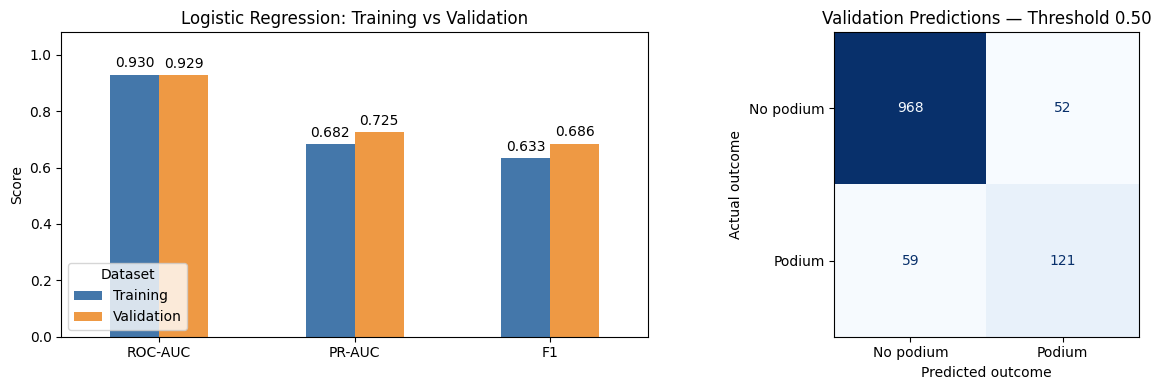

In [156]:
# Make validation predictions using the initial 0.50 threshold
validation_probabilities = logistic_model.predict_proba(
    X_validation
)[:, 1]

validation_predictions = (
    validation_probabilities >= 0.5
).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Compare training and validation scores
logistic_results[["ROC-AUC", "PR-AUC", "F1"]].T.plot.bar(
    ax=axes[0],
    color=["#4477AA", "#EE9944"],
    rot=0
)

axes[0].set_title("Logistic Regression: Training vs Validation")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1.08)
axes[0].legend(title="Dataset", loc="lower left")

for bars in axes[0].containers:
    axes[0].bar_label(bars, fmt="%.3f", padding=3)

# Show correct and incorrect validation predictions
ConfusionMatrixDisplay.from_predictions(
    y_validation,
    validation_predictions,
    labels=[0, 1],
    display_labels=["No podium", "Podium"],
    cmap="Blues",
    colorbar=False,
    values_format="d",
    ax=axes[1]
)

axes[1].set_title("Validation Predictions — Threshold 0.50")
axes[1].set_xlabel("Predicted outcome")
axes[1].set_ylabel("Actual outcome")

plt.tight_layout()
plt.show()

### Random forest - nonlinear statistical model

A random forest averages predictions from many decision trees. Trees can
learn interactions, such as different effects of grid position for drivers
with different recent form. Depth and leaf-size limits constrain complexity.
Forests can still overfit historical patterns and struggle when future
seasons differ substantially from training.

In [157]:
from sklearn.ensemble import RandomForestClassifier

forest_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Use exactly the same training inputs as logistic regression
forest_model.fit(X_train, y_train)

RandomForestClassifier(max_depth=8, min_samples_leaf=5, n_estimators=300,
                       n_jobs=-1, random_state=42)

In [158]:
forest_results = pd.DataFrame({
    "Training": evaluate_model(
        forest_model, X_train, y_train
    ),
    "Validation": evaluate_model(
        forest_model, X_validation, y_validation
    )
}).T

display(forest_results.round(3))

# Compare the two models on validation data
validation_comparison = pd.DataFrame({
    "Logistic regression": logistic_results.loc["Validation"],
    "Random forest": forest_results.loc["Validation"]
}).T

display(validation_comparison.round(3))

,ROC-AUC,PR-AUC,F1,Precision,Recall
Training,0.949,0.768,0.662,0.746,0.594
Validation,0.939,0.744,0.718,0.744,0.694


,ROC-AUC,PR-AUC,F1,Precision,Recall
Logistic regression,0.929,0.725,0.686,0.699,0.672
Random forest,0.939,0.744,0.718,0.744,0.694


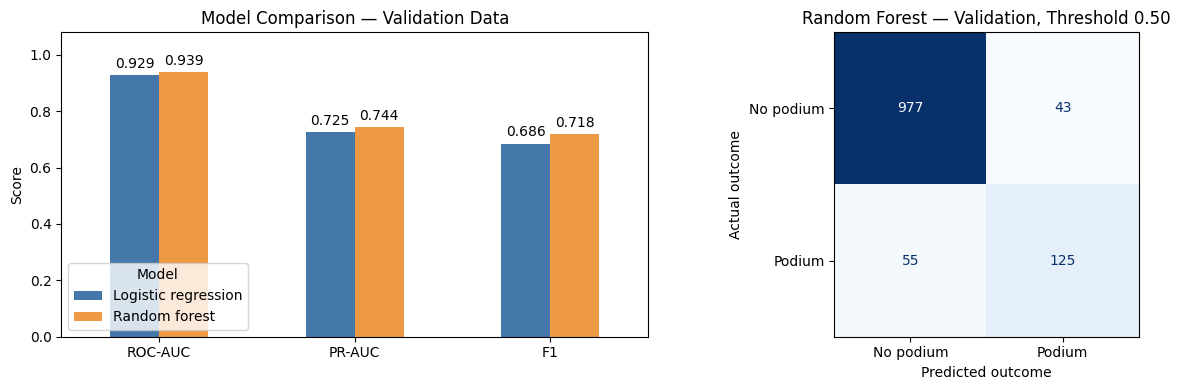

In [159]:
# Generate validation predictions
forest_probabilities = forest_model.predict_proba(
    X_validation
)[:, 1]

forest_predictions = (
    forest_probabilities >= 0.5
).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Compare validation scores for both models
validation_comparison[["ROC-AUC", "PR-AUC", "F1"]].T.plot.bar(
    ax=axes[0],
    color=["#4477AA", "#EE9944"],
    rot=0
)

axes[0].set_title("Model Comparison — Validation Data")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1.08)
axes[0].legend(title="Model", loc="lower left")

for bars in axes[0].containers:
    axes[0].bar_label(bars, fmt="%.3f", padding=3)

# Inspect random forest's correct and incorrect predictions
ConfusionMatrixDisplay.from_predictions(
    y_validation,
    forest_predictions,
    labels=[0, 1],
    display_labels=["No podium", "Podium"],
    cmap="Blues",
    colorbar=False,
    values_format="d",
    ax=axes[1]
)

axes[1].set_title("Random Forest — Validation, Threshold 0.50")
axes[1].set_xlabel("Predicted outcome")
axes[1].set_ylabel("Actual outcome")

plt.tight_layout()
plt.show()

### Shallow neural network

The network learns weighted combinations through two hidden layers of
32 and 16 units. ReLU activations allow nonlinear relationships between
the inputs and podium probability. We compare it with the simpler baseline
to justify its added complexity. It needs scaled inputs, is less directly
interpretable and can overfit. We select its checkpoint using validation
PR-AUC, stopping after 20 epochs without improvement.

In [160]:
from sklearn.neural_network import MLPClassifier
from copy import deepcopy

network = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    alpha=0.01,
    batch_size=128,
    learning_rate_init=0.001,
    random_state=42
)

In [161]:
best_score = -1
best_epoch = 0
best_network = None
epochs_without_improvement = 0
neural_history = []

for epoch in range(1, 201):
    # Train for one additional epoch
    network.partial_fit(
        X_train, y_train,
        classes=[0, 1]
    )

    # Monitor training and validation PR-AUC
    training_score = evaluate_model(
        network, X_train, y_train
    )["PR-AUC"]

    validation_score = evaluate_model(
        network, X_validation, y_validation
    )["PR-AUC"]

    neural_history.append({
        "Epoch": epoch,
        "Training PR-AUC": training_score,
        "Validation PR-AUC": validation_score
    })

    # Save the network whenever validation performance improves
    if validation_score > best_score:
        best_score = validation_score
        best_epoch = epoch
        best_network = deepcopy(network)
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # Stop after 20 epochs without improvement
    if epochs_without_improvement >= 20:
        break

# Use the best saved version, rather than the last epoch
neural_model = best_network
neural_history = pd.DataFrame(neural_history)

print("Epochs completed:", len(neural_history))
print("Best epoch:", best_epoch)

Epochs completed: 51
Best epoch: 31


In [162]:
neural_results = pd.DataFrame({
    "Training": evaluate_model(
        neural_model, X_train, y_train
    ),
    "Validation": evaluate_model(
        neural_model, X_validation, y_validation
    )
}).T

display(neural_results.round(3))

validation_comparison = pd.DataFrame({
    "Logistic regression": logistic_results.loc["Validation"],
    "Random forest": forest_results.loc["Validation"],
    "Neural network": neural_results.loc["Validation"]
}).T

display(validation_comparison.round(3))

,ROC-AUC,PR-AUC,F1,Precision,Recall
Training,0.941,0.716,0.659,0.703,0.620
Validation,0.931,0.746,0.712,0.703,0.722


,ROC-AUC,PR-AUC,F1,Precision,Recall
Logistic regression,0.929,0.725,0.686,0.699,0.672
Random forest,0.939,0.744,0.718,0.744,0.694
Neural network,0.931,0.746,0.712,0.703,0.722


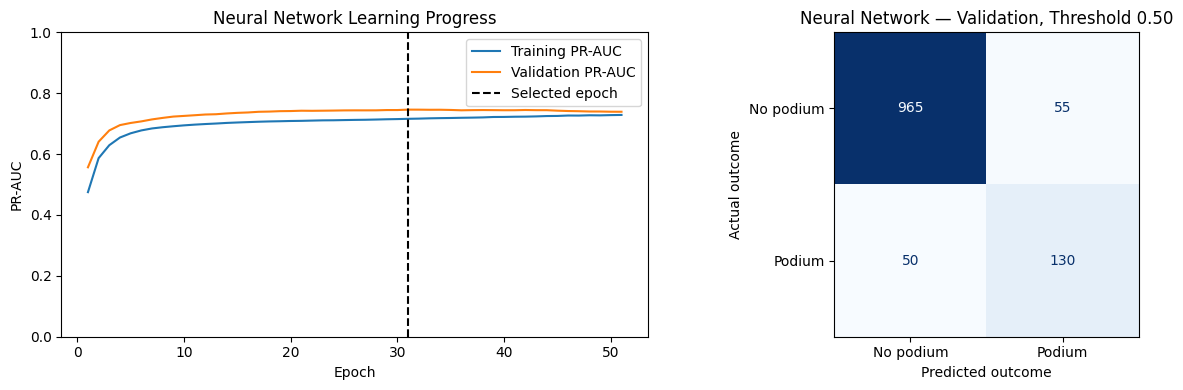

In [163]:
neural_probabilities = neural_model.predict_proba(
    X_validation
)[:, 1]

neural_predictions = (
    neural_probabilities >= 0.5
).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Show how performance changed during training
neural_history.plot(
    x="Epoch",
    y=["Training PR-AUC", "Validation PR-AUC"],
    ax=axes[0]
)

axes[0].axvline(
    best_epoch,
    color="black",
    linestyle="--",
    label="Selected epoch"
)

axes[0].set_title("Neural Network Learning Progress")
axes[0].set_ylabel("PR-AUC")
axes[0].set_ylim(0, 1)
axes[0].legend()

# Show errors made by the selected network
ConfusionMatrixDisplay.from_predictions(
    y_validation,
    neural_predictions,
    labels=[0, 1],
    display_labels=["No podium", "Podium"],
    cmap="Blues",
    colorbar=False,
    values_format="d",
    ax=axes[1]
)

axes[1].set_title("Neural Network — Validation, Threshold 0.50")
axes[1].set_xlabel("Predicted outcome")
axes[1].set_ylabel("Actual outcome")

plt.tight_layout()
plt.show()

In [164]:
import numpy as np
from sklearn.metrics import f1_score

models = {
    "Logistic regression": logistic_model,
    "Random forest": forest_model,
    "Neural network": neural_model
}

# Compare thresholds from 0.05 to 0.95
thresholds = np.round(np.linspace(0.05, 0.95, 91), 2)

threshold_rows = []

for name, model in models.items():
    probabilities = model.predict_proba(X_validation)[:, 1]

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        threshold_rows.append({
            "Model": name,
            "Threshold": threshold,
            "F1": f1_score(
                y_validation, predictions, zero_division=0
            )
        })

threshold_trials = pd.DataFrame(threshold_rows)

In [165]:
threshold_trials["Distance from 0.50"] = (
    threshold_trials["Threshold"] - 0.5
).abs()

best_thresholds = (
    threshold_trials
    .sort_values(
        ["F1", "Distance from 0.50"],
        ascending=[False, True]
    )
    .drop_duplicates("Model")
    .set_index("Model")["Threshold"]
)

display(best_thresholds.rename("Selected threshold").to_frame())

,Selected threshold
Model,
Random forest,0.44
Logistic regression,0.38
Neural network,0.43


In [166]:
report_rows = []

for name, model in models.items():
    threshold = float(best_thresholds.loc[name])

    for dataset, inputs, target in [
        ("Training", X_train, y_train),
        ("Validation", X_validation, y_validation)
    ]:
        scores = evaluate_model(
            model, inputs, target,
            threshold=threshold
        )

        report_rows.append({
            "Model": name,
            "Dataset": dataset,
            "Threshold": threshold,
            **scores
        })

modeling_report = pd.DataFrame(report_rows)

display(modeling_report.round(3))

# Keep the final validation results separately
validation_final = (
    modeling_report[
        modeling_report["Dataset"] == "Validation"
    ].set_index("Model")
)

# Compare F1 before and after threshold selection
threshold_comparison = pd.DataFrame({
    "Selected threshold": best_thresholds,
    "F1 at 0.50": validation_comparison["F1"],
    "F1 at selected threshold": validation_final["F1"]
})

display(threshold_comparison.round(3))

,Model,Dataset,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Logistic regression,Training,0.38,0.930,0.682,0.665,0.615,0.723
1,Logistic regression,Validation,0.38,0.929,0.725,0.724,0.665,0.794
2,Random forest,Training,0.44,0.949,0.768,0.691,0.720,0.663
3,Random forest,Validation,0.44,0.939,0.744,0.727,0.721,0.733
4,Neural network,Training,0.43,0.941,0.716,0.669,0.659,0.679
5,Neural network,Validation,0.43,0.931,0.746,0.718,0.667,0.778


,Selected threshold,F1 at 0.50,F1 at selected threshold
Logistic regression,0.38,0.686,0.724
Neural network,0.43,0.712,0.718
Random forest,0.44,0.718,0.727


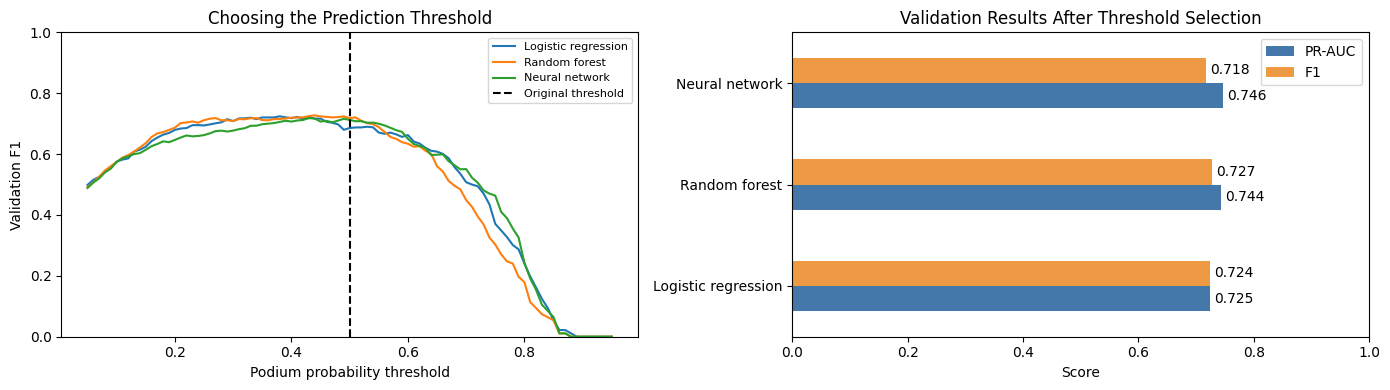

In [167]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Show how the threshold affects validation F1
threshold_curves = threshold_trials.pivot(
    index="Threshold",
    columns="Model",
    values="F1"
)

threshold_curves[list(models)].plot(ax=axes[0])

axes[0].axvline(
    0.5, color="black", linestyle="--",
    label="Original threshold"
)

axes[0].set_title("Choosing the Prediction Threshold")
axes[0].set_xlabel("Podium probability threshold")
axes[0].set_ylabel("Validation F1")
axes[0].set_ylim(0, 1)
axes[0].legend(fontsize=8)

# Compare ranking quality and classification performance
validation_final[["PR-AUC", "F1"]].plot.barh(
    ax=axes[1],
    color=["#4477AA", "#EE9944"]
)

axes[1].set_title("Validation Results After Threshold Selection")
axes[1].set_xlabel("Score")
axes[1].set_ylabel("")
axes[1].set_xlim(0, 1)

for bars in axes[1].containers:
    axes[1].bar_label(bars, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

In [168]:
reference_name = validation_final["PR-AUC"].idxmax()

reference_model = models[reference_name]
reference_threshold = float(best_thresholds.loc[reference_name])

print("Reference model:", reference_name)
print("Selected threshold:", reference_threshold)

Reference model: Neural network
Selected threshold: 0.43


## Initial modeling comparison

Logistic regression is the baseline; random forest and the shallow neural
network test whether nonlinear patterns improve prediction. These initial
models use the same 46 inputs and chronological splits.

PR-AUC is primary because podiums are relatively uncommon. F1 is secondary
because it balances precision and recall. ROC-AUC, precision and recall are
also reported. PR-AUC uses trapezoidal integration of the precision-recall curve.

Model settings, the neural checkpoint and classification thresholds use only
training and validation information. Stage 5 compares feature groups and
preprocessing orders. The final test comparison appears after those choices
are fixed; the test set is not used to choose another winner.

# Stage 5 - Experiments

In [169]:
feature_groups = {
    "Grid": [
        "grid_for_analysis",
        "grid_for_analysis_missing"
    ],

    "Qualifying": [
        "qualifying_position",
        "qualifying_position_missing"
    ],

    "Recent form": [
        "recent_podium_rate",
        "recent_avg_finish",
        "past_races_used",
        "recent_podium_rate_missing",
        "recent_avg_finish_missing"
    ],

    "Driver standings": [
        "driver_points_before_race",
        "driver_standing_before_race",
        "driver_points_before_race_missing",
        "driver_standing_before_race_missing"
    ],

    "Constructor standings": [
        "constructor_points_before_race",
        "constructor_standing_before_race",
        "constructor_points_before_race_missing",
        "constructor_standing_before_race_missing"
    ],

    "Constructor identity": encoded_constructors.columns.tolist()
}

# Check that every input belongs to exactly one group
grouped_columns = [
    column
    for columns in feature_groups.values()
    for column in columns
]

assert len(grouped_columns) == len(set(grouped_columns))
assert set(grouped_columns) == set(X_train.columns)

In [170]:
from sklearn.base import clone
from sklearn.neural_network import MLPClassifier

# Use the selected neural-network checkpoint's training duration
neural_epochs = best_epoch

def train_copy(base_model, inputs, target, neural_epochs):
    model = clone(base_model)

    if isinstance(model, MLPClassifier):
        # Keep the same epoch budget for every neural-network trial
        for _ in range(neural_epochs):
            model.partial_fit(
                inputs, target,
                classes=[0, 1]
            )
    else:
        model.fit(inputs, target)

    return model

In [171]:
# Record the reference model's validation performance
baseline_scores = evaluate_model(
    reference_model,
    X_validation,
    y_validation,
    threshold=reference_threshold
)

ablation_rows = [{
    "Removed group": "None (all features)",
    "Inputs": X_train.shape[1],
    **baseline_scores
}]

# Preserve the fitted models for later inspection
ablation_models = {
    "None (all features)": reference_model
}

for group, columns in feature_groups.items():
    # Remove the same columns from training and validation
    reduced_train = X_train.drop(columns=columns)
    reduced_validation = X_validation.drop(columns=columns)

    # Retrain from scratch
    model = train_copy(
        reference_model,
        reduced_train,
        y_train,
        neural_epochs
    )

    ablation_models[group] = model

    scores = evaluate_model(
        model,
        reduced_validation,
        y_validation,
        threshold=reference_threshold
    )

    ablation_rows.append({
        "Removed group": group,
        "Inputs": reduced_train.shape[1],
        **scores
    })

ablation_results = pd.DataFrame(
    ablation_rows
).set_index("Removed group")

# Positive means removing the group reduced PR-AUC
ablation_results["PR-AUC drop"] = (
    baseline_scores["PR-AUC"] - ablation_results["PR-AUC"]
)

display(ablation_results.round(4))

,Inputs,ROC-AUC,PR-AUC,F1,Precision,Recall,PR-AUC drop
Removed group,,,,,,,
None (all features),46,0.9309,0.7461,0.7179,0.6667,0.7778,0.0000
Grid,44,0.9280,0.7310,0.7077,0.6571,0.7667,0.0151
Qualifying,44,0.9310,0.7529,0.7147,0.6651,0.7722,-0.0069
Recent form,41,0.9369,0.7411,0.7296,0.6745,0.7944,0.0049
Driver standings,42,0.9313,0.7434,0.7287,0.6812,0.7833,0.0027
Constructor standings,42,0.9316,0.7532,0.7311,0.6897,0.7778,-0.0071
Constructor identity,17,0.9376,0.7638,0.7335,0.6985,0.7722,-0.0177


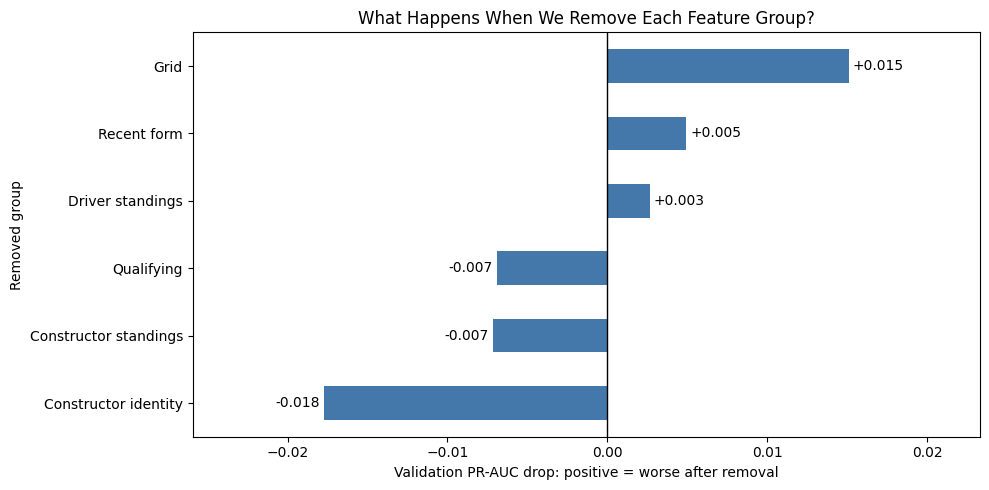

In [172]:
plot_data = (
    ablation_results
    .drop(index="None (all features)")
    .sort_values("PR-AUC drop")
)

ax = plot_data["PR-AUC drop"].plot.barh(
    figsize=(10, 5),
    color="#4477AA"
)

ax.axvline(0, color="black", linewidth=1)

ax.set_title("What Happens When We Remove Each Feature Group?")
ax.set_xlabel("Validation PR-AUC drop: positive = worse after removal")
ax.set_ylabel("Removed group")
ax.margins(x=0.25)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%+.3f", padding=3)

plt.tight_layout()
plt.show()

In [173]:
order_inputs = {
    "Fill then scale": X,
    "Scale then fill": X_order_b
}

# Both versions must describe the same appearances and features
assert X.columns.equals(X_order_b.columns)
assert X.index.equals(X_order_b.index)

In [174]:
order_models = {}
order_rows = []

for order, inputs in order_inputs.items():
    # Train a fresh copy using this version of the inputs
    model = train_copy(
        reference_model,
        inputs.loc[train_mask],
        y_train,
        neural_epochs
    )

    order_models[order] = model

    training_scores = evaluate_model(
        model,
        inputs.loc[train_mask],
        y_train,
        threshold=reference_threshold
    )

    validation_scores = evaluate_model(
        model,
        inputs.loc[validation_mask],
        y_validation,
        threshold=reference_threshold
    )

    order_rows.append({
        "Order": order,
        "Inputs": inputs.shape[1],
        "Training PR-AUC": training_scores["PR-AUC"],
        **validation_scores
    })

preprocessing_results = pd.DataFrame(
    order_rows
).set_index("Order")

display(preprocessing_results.round(4))

,Inputs,Training PR-AUC,ROC-AUC,PR-AUC,F1,Precision,Recall
Order,,,,,,,
Fill then scale,46,0.7159,0.9309,0.7461,0.7179,0.6667,0.7778
Scale then fill,46,0.7204,0.9309,0.7418,0.7194,0.6651,0.7833


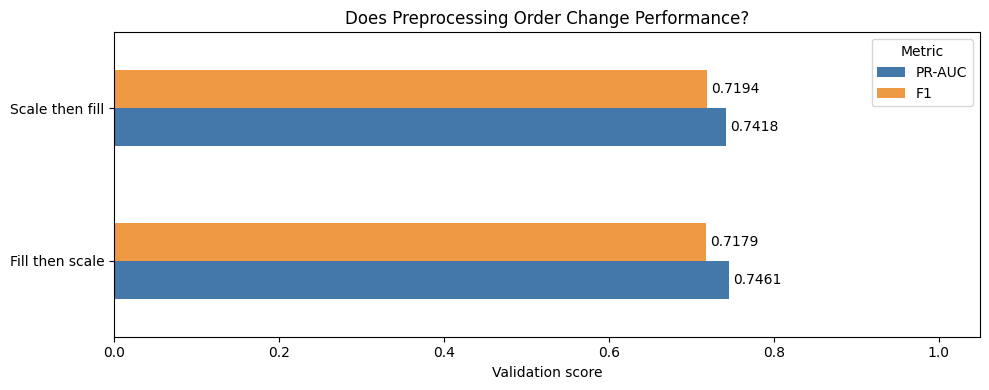

In [175]:
ax = preprocessing_results[["PR-AUC", "F1"]].plot.barh(
    figsize=(10, 4),
    color=["#4477AA", "#EE9944"]
)

ax.set_title("Does Preprocessing Order Change Performance?")
ax.set_xlabel("Validation score")
ax.set_ylabel("")
ax.set_xlim(0, 1.05)
ax.legend(title="Metric")

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.4f", padding=3)

plt.tight_layout()
plt.show()

In [176]:
preferred_order = preprocessing_results["PR-AUC"].idxmax()
preferred_inputs = order_inputs[preferred_order]

print("Preferred preprocessing order:", preferred_order)

Preferred preprocessing order: Fill then scale


In [177]:
feature_versions = {
    "All features": preferred_inputs,

    "Without constructor identity": preferred_inputs.drop(
        columns=feature_groups["Constructor identity"]
    )
}

In [178]:
confirmation_models = {}
confirmation_rows = []

for version, inputs in feature_versions.items():
    for name, base_model in models.items():
        # Train a fresh model with this feature set
        model = train_copy(
            base_model,
            inputs.loc[train_mask],
            y_train,
            neural_epochs
        )

        confirmation_models[(version, name)] = model

        training_scores = evaluate_model(
            model,
            inputs.loc[train_mask],
            y_train,
            threshold=float(best_thresholds.loc[name])
        )

        validation_scores = evaluate_model(
            model,
            inputs.loc[validation_mask],
            y_validation,
            threshold=float(best_thresholds.loc[name])
        )

        confirmation_rows.append({
            "Feature set": version,
            "Model": name,
            "Inputs": inputs.shape[1],
            "Training PR-AUC": training_scores["PR-AUC"],
            **validation_scores
        })

feature_confirmation = pd.DataFrame(confirmation_rows)

display(feature_confirmation.round(4))

,Feature set,Model,Inputs,Training PR-AUC,ROC-AUC,PR-AUC,F1,Precision,Recall
0,All features,Logistic regression,46,0.6822,0.9293,0.7246,0.7241,0.6651,0.7944
1,All features,Random forest,46,0.7683,0.9386,0.7441,0.7273,0.7213,0.7333
2,All features,Neural network,46,0.7159,0.9309,0.7461,0.7179,0.6667,0.7778
3,Without constructor identity,Logistic regression,17,0.6754,0.9295,0.7226,0.7179,0.6667,0.7778
4,Without constructor identity,Random forest,17,0.7975,0.9391,0.7438,0.7088,0.7011,0.7167
5,Without constructor identity,Neural network,17,0.6980,0.9376,0.7638,0.7335,0.6985,0.7722


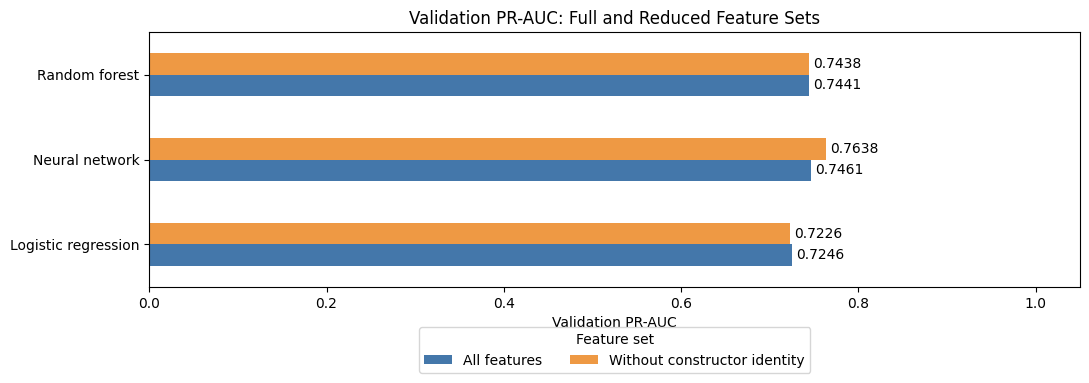

In [179]:
confirmation_chart = feature_confirmation.pivot(
    index="Model",
    columns="Feature set",
    values="PR-AUC"
)

ax = confirmation_chart.plot.barh(
    figsize=(11, 4),
    color=["#4477AA", "#EE9944"]
)

ax.set_title("Validation PR-AUC: Full and Reduced Feature Sets")
ax.set_xlabel("Validation PR-AUC")
ax.set_ylabel("")
ax.set_xlim(0, 1.05)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.4f", padding=3)

ax.legend(title="Feature set", loc="upper center",
          bbox_to_anchor=(0.5, -0.13), ncol=2)
plt.tight_layout()
plt.show()

In [180]:
version_summary = feature_confirmation.groupby("Feature set").agg(
    best_validation_pr_auc=("PR-AUC", "max"),
    inputs=("Inputs", "first")
).sort_values(
    ["best_validation_pr_auc", "inputs"],
    ascending=[False, True]
)

chosen_feature_set = version_summary.index[0]

final_inputs = feature_versions[chosen_feature_set].copy()
final_feature_columns = final_inputs.columns.tolist()

X_train_final = final_inputs.loc[train_mask].copy()
X_validation_final = final_inputs.loc[validation_mask].copy()
X_test_final = final_inputs.loc[test_mask].copy()

# These models were already fitted in the comparison above
final_models = {
    name: confirmation_models[(chosen_feature_set, name)]
    for name in models
}

print("Preferred preprocessing:", preferred_order)
print("Selected feature set:", chosen_feature_set)
print("Final input columns:", len(final_feature_columns))

Preferred preprocessing: Fill then scale
Selected feature set: Without constructor identity
Final input columns: 17


In [181]:
final_threshold_rows = []

for name, model in final_models.items():
    probabilities = model.predict_proba(
        X_validation_final
    )[:, 1]

    for threshold in np.round(np.linspace(0.05, 0.95, 91), 2):
        predictions = (probabilities >= threshold).astype(int)

        final_threshold_rows.append({
            "Model": name,
            "Threshold": threshold,
            "F1": f1_score(
                y_validation, predictions, zero_division=0
            )
        })

final_threshold_trials = pd.DataFrame(final_threshold_rows)

final_threshold_trials["Distance from 0.50"] = (
    final_threshold_trials["Threshold"] - 0.5
).abs()

final_thresholds = (
    final_threshold_trials
    .sort_values(
        ["F1", "Distance from 0.50"],
        ascending=[False, True]
    )
    .drop_duplicates("Model")
    .set_index("Model")["Threshold"]
)

display(final_thresholds.rename("Final threshold").to_frame())

,Final threshold
Model,
Neural network,0.43
Random forest,0.48
Logistic regression,0.40


In [182]:
final_report_rows = []

for name, model in final_models.items():
    threshold = float(final_thresholds.loc[name])

    for dataset, inputs, target in [
        ("Training", X_train_final, y_train),
        ("Validation", X_validation_final, y_validation)
    ]:
        final_report_rows.append({
            "Model": name,
            "Dataset": dataset,
            "Threshold": threshold,
            **evaluate_model(
                model, inputs, target,
                threshold=threshold
            )
        })

final_modeling_report = pd.DataFrame(final_report_rows)

display(final_modeling_report.round(4))

# Select the leading model using validation PR-AUC
final_validation = final_modeling_report[
    final_modeling_report["Dataset"] == "Validation"
].set_index("Model")

final_model_name = final_validation["PR-AUC"].idxmax()
final_model = final_models[final_model_name]
final_threshold = float(final_thresholds.loc[final_model_name])

# Verify consistent inputs and matching appearances
assert X_train_final.columns.equals(X_validation_final.columns)
assert X_train_final.columns.equals(X_test_final.columns)
assert X_train_final.index.equals(y_train.index)
assert X_validation_final.index.equals(y_validation.index)
assert np.isfinite(final_inputs.to_numpy()).all()

for model in final_models.values():
    assert list(model.feature_names_in_) == final_feature_columns

print("Selected model:", final_model_name)
print("Selected threshold:", final_threshold)
print("Final input checks passed.")

,Model,Dataset,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Logistic regression,Training,0.40,0.9262,0.6754,0.6494,0.6301,0.6700
1,Logistic regression,Validation,0.40,0.9295,0.7226,0.7202,0.6748,0.7722
2,Random forest,Training,0.48,0.9558,0.7975,0.6961,0.7391,0.6578
3,Random forest,Validation,0.48,0.9391,0.7438,0.7207,0.7247,0.7167
4,Neural network,Training,0.43,0.9339,0.6980,0.6569,0.6393,0.6756
5,Neural network,Validation,0.43,0.9376,0.7638,0.7335,0.6985,0.7722


Selected model: Neural network
Selected threshold: 0.43
Final input checks passed.


## Phase 5 — Experiments

### 1. Set the comparison rules

We used **validation PR-AUC as the main metric** because podium finishes
are relatively uncommon. We also reported F1, ROC-AUC, precision and recall.

All decisions used training and validation data. The test set remained reserved.

### 2. Establish the reference result

We used the neural network as the reference because it had the highest
initial validation PR-AUC.

With all 46 inputs, its validation PR-AUC was approximately **0.7461**.
This gave us a baseline for measuring changes.

### 3. Test removing feature groups

We removed one group at a time:
- Starting grid.
- Qualifying position.
- Recent driver performance.
- Driver standings.
- Constructor standings.
- Constructor identity.

We removed each group’s missing-value flags or encoded columns too,
so the model could not retain information from that group.

### 4. Retrain under consistent conditions

Each experiment trained a fresh copy of the reference model.

We kept the same appearances, model settings, random seed, training
duration and prediction threshold. This made the feature comparisons
more consistent.

### 5. Interpret the feature-removal results

Removing grid information reduced PR-AUC the most.

Removing constructor identity increased PR-AUC from approximately
**0.7461 to 0.7638**, making the smaller feature set worth investigating.

We did not combine all individually beneficial removals, because their
combined effect had not been tested.

### 6. Compare preprocessing orders

We compared:
- **Fill then scale.**
- **Scale then fill.**

Both used training-only preprocessing settings and the same 46 inputs.
We retrained the same model to measure prediction performance.

Fill then scale achieved higher validation PR-AUC:
**0.7461 versus 0.7418**. We retained it because PR-AUC was our main metric.

### 7. Confirm the reduced inputs across all models

We compared 46 inputs against 17 inputs for logistic regression,
random forest and the neural network.

The reduced set did not improve every model. However, the reduced
neural network achieved the highest validation PR-AUC among the candidates.

We selected the same **17 inputs for all three final models**:
nine numeric features and eight missing-value flags.

Constructor identity indicators were removed; constructor points
and championship position remained.

### 8. Finalize thresholds and checks

After selecting the inputs, we refreshed each model’s threshold using
validation F1. We recorded the final training and validation metrics.

We checked that all three models used matching input columns,
that inputs matched their targets, and that no missing or infinite
prepared values remained.

### Conclusion

The experiments supported using the reduced inputs with fill-then-scale
preprocessing. We fixed these choices before test evaluation.

These findings apply to our validation period and training settings.
They do not establish causal effects or guarantee better test performance.

## Final test evaluation - frozen modeling choices

This completes the Stage 4 evaluation after Stage 5 has fixed the feature
set, preprocessing, models and thresholds. All three models use the same
17 inputs: nine numeric features and eight missing-value flags.
Evaluate the reserved 2022-2024 appearances once; keep the model selected
using validation PR-AUC even if another model scores higher on the test set.

In [183]:
# Evaluate existing fitted models; do not fit or tune on test data
test_rows = []
for name, model in final_models.items():
    threshold = float(final_thresholds.loc[name])
    test_rows.append({
        "Model": name,
        "Dataset": "Test",
        "Threshold": threshold,
        **evaluate_model(model, X_test_final, y_test, threshold=threshold)
    })

test_results = pd.DataFrame(test_rows)
complete_modeling_report = pd.concat(
    [final_modeling_report, test_results], ignore_index=True
)
dataset_order = pd.CategoricalDtype(
    ["Training", "Validation", "Test"], ordered=True
)
complete_modeling_report["Dataset"] = (
    complete_modeling_report["Dataset"].astype(dataset_order)
)
complete_modeling_report = complete_modeling_report.sort_values(
    ["Model", "Dataset"]
).reset_index(drop=True)

display(complete_modeling_report.round(4))
print("Model retained from validation:", final_model_name)
print("Fixed threshold:", final_threshold)

,Model,Dataset,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Logistic regression,Training,0.40,0.9262,0.6754,0.6494,0.6301,0.6700
1,Logistic regression,Validation,0.40,0.9295,0.7226,0.7202,0.6748,0.7722
2,Logistic regression,Test,0.40,0.9345,0.7050,0.6523,0.6385,0.6667
3,Neural network,Training,0.43,0.9339,0.6980,0.6569,0.6393,0.6756
4,Neural network,Validation,0.43,0.9376,0.7638,0.7335,0.6985,0.7722
5,Neural network,Test,0.43,0.9375,0.7078,0.6730,0.6514,0.6961
6,Random forest,Training,0.48,0.9558,0.7975,0.6961,0.7391,0.6578
7,Random forest,Validation,0.48,0.9391,0.7438,0.7207,0.7247,0.7167
8,Random forest,Test,0.48,0.9376,0.7113,0.6564,0.6882,0.6275


Model retained from validation: Neural network
Fixed threshold: 0.43


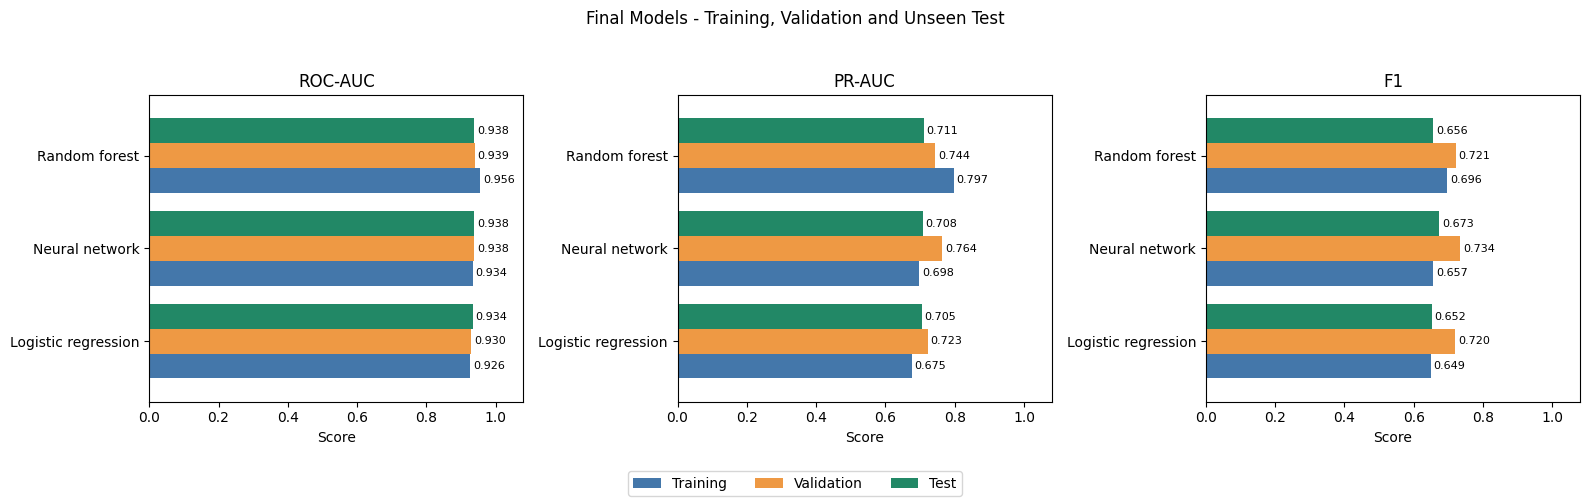

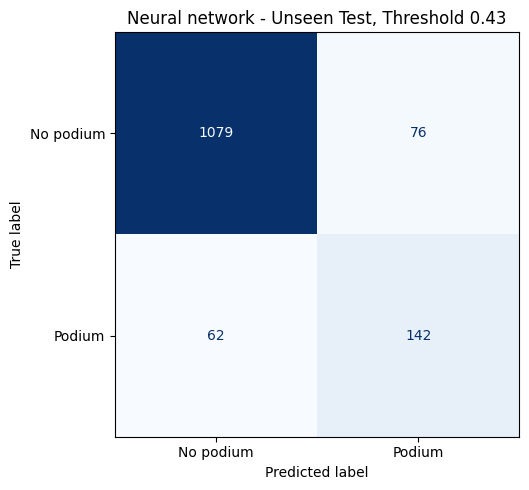

In [184]:
# Compare final model performance across all three datasets
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, metric in zip(axes, ["ROC-AUC", "PR-AUC", "F1"]):
    scores = complete_modeling_report.pivot(
        index="Model", columns="Dataset", values=metric
    )[["Training", "Validation", "Test"]]
    scores.plot.barh(
        ax=ax, color=["#4477AA", "#EE9944", "#228866"], width=0.8
    )
    ax.set_title(metric)
    ax.set_xlim(0, 1.08)
    ax.set_xlabel("Score")
    ax.set_ylabel("")
    ax.legend().remove()
    for bars in ax.containers:
        ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=8)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3)
fig.suptitle("Final Models - Training, Validation and Unseen Test")
plt.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.show()

# Inspect the already selected model's test errors
test_probabilities = final_model.predict_proba(X_test_final)[:, 1]
test_predictions = (test_probabilities >= final_threshold).astype(int)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, labels=[0, 1],
    display_labels=["No podium", "Podium"], cmap="Blues",
    colorbar=False, values_format="d", ax=ax
)
ax.set_title(f"{final_model_name} - Unseen Test, Threshold {final_threshold:.2f}")
plt.tight_layout()
plt.show()

### Final comparison and limitations

The reduced neural network was selected using validation PR-AUC
(**0.7638**, versus **0.7226** for logistic regression and **0.7440**
for random forest). Its test PR-AUC is **0.7078** and test F1 is **0.6730**.
Random forest has slightly higher test PR-AUC (**0.7114**); we retain the
preselected network rather than selecting again on test results.

The lower test PR-AUC shows that validation performance did not transfer
fully to the later period. Changes in seasons, available records and field
competitiveness can affect generalization; this comparison does not identify
a single cause. These are individual driver predictions and do not enforce
exactly three predicted podium finishers per race. Their probabilities are
model estimates, not guarantees.

## Inference - predict from a pre-race record

Supply the nine numeric features in their original units. Historical
features must already describe earlier races. The function creates missing
flags before filling, reuses training medians and scaling, preserves the
final input order, and applies the frozen model and threshold. It does not
retrain or read the current race's outcome. Constructor identity is absent
from the selected final inputs.

In [185]:
def predict_podium(record):
    # Reject extra fields, including current-race outcomes
    unexpected = set(record) - set(numeric_features)
    if unexpected:
        raise ValueError(f"Unexpected input fields: {sorted(unexpected)}")

    # Omitted keys and None values represent missing information
    values = pd.DataFrame([record]).reindex(columns=numeric_features)
    values = values.apply(pd.to_numeric, errors="raise").astype(float)

    # A recorded grid of zero is unavailable, as in the cleaning stage
    values["grid_for_analysis"] = values["grid_for_analysis"].where(
        values["grid_for_analysis"] > 0
    )
    filled_features = values.columns[values.isna().iloc[0]].tolist()
    flags = values[missing_numeric_features].isna().astype(int)
    flags.columns = [column + "_missing" for column in flags.columns]

    # Reuse existing preprocessing; never learn from the new record
    values = values.fillna(training_medians)
    scaled = pd.DataFrame(
        scaler.transform(values), columns=numeric_features
    )
    prepared = pd.concat([scaled, flags], axis=1)[final_feature_columns]
    if not np.isfinite(prepared.to_numpy()).all():
        raise ValueError("Inputs must contain finite numbers or missing values.")

    probability = float(final_model.predict_proba(prepared)[0, 1])
    return {
        "podium_probability": probability,
        "prediction": "Podium" if probability >= final_threshold else "No podium",
        "threshold": final_threshold,
        "filled_features": ", ".join(filled_features) or "None"
    }

In [186]:
# Use the first complete validation example, without its outcome
complete_examples = model_features.loc[
    validation_mask, numeric_features
].dropna()
example_index = complete_examples.index[0]
complete_record = complete_examples.iloc[0].to_dict()

# Demonstrate the same appearance with two unavailable inputs
partial_record = complete_record.copy()
partial_record["qualifying_position"] = None
partial_record["recent_avg_finish"] = None

display(pd.DataFrame({
    "Complete record": complete_record,
    "Partially missing record": partial_record
}))

inference_examples = pd.DataFrame({
    "Complete record": predict_podium(complete_record),
    "Partially missing record": predict_podium(partial_record)
}).T
display(inference_examples)

# Confirm that the complete example matches the prepared modeling row
np.testing.assert_allclose(
    inference_examples.loc["Complete record", "podium_probability"],
    final_model.predict_proba(X_validation_final.loc[[example_index]])[0, 1]
)
print("Inference check passed: the complete record matches the existing pipeline.")

,Complete record,Partially missing record
grid_for_analysis,3.0,3.0
qualifying_position,3.0,NaN
recent_podium_rate,80.0,80.0
recent_avg_finish,2.2,NaN
past_races_used,5.0,5.0
driver_points_before_race,18.0,18.0
driver_standing_before_race,2.0,2.0
constructor_points_before_race,44.0,44.0
constructor_standing_before_race,1.0,1.0


,podium_probability,prediction,threshold,filled_features
Complete record,0.685997,Podium,0.43,None
Partially missing record,0.133267,No podium,0.43,"qualifying_position, recent_avg_finish"


Inference check passed: the complete record matches the existing pipeline.


Both examples produce a probability and a threshold-based decision. The
partially missing example records the two filled inputs explicitly.
Median filling allows a prediction; it does not recover the unknown true
values. Collect missing pre-race information when possible. These examples
demonstrate the interface and preprocessing, not a new performance estimate.

# Stage 6 - Model Explainability

In [187]:
%pip install shap lime
import shap
from lime.lime_tabular import LimeTabularExplainer

Note: you may need to restart the kernel to use updated packages.


In [188]:
from IPython.display import display
from sklearn.inspection import permutation_importance

In [189]:
# Create explanation copies without changing the model's inputs
X_train_xai = X_train_final.astype(float).copy()
X_validation_xai = X_validation_final.astype(float).copy()

# Restore the original units of numeric features
X_train_xai[numeric_features] = scaler.inverse_transform(
    X_train_final[numeric_features]
)

X_validation_xai[numeric_features] = scaler.inverse_transform(
    X_validation_final[numeric_features]
)

def predict_for_xai(values):
    # Restore the column names and the preprocessing expected by the model
    inputs = pd.DataFrame(
        values,
        columns=X_train_xai.columns
    ).copy()

    inputs[numeric_features] = scaler.transform(
        inputs[numeric_features]
    )

    return final_model.predict_proba(inputs)

# Verify that readable inputs produce the same predictions
assert np.array_equal(final_model.classes_, [0, 1])

np.testing.assert_allclose(
    predict_for_xai(X_validation_xai),
    final_model.predict_proba(X_validation_final),
    rtol=1e-10,
    atol=1e-12
)

print("Explaining:", final_model_name)
print("Prediction check passed.")

Explaining: Neural network
Prediction check passed.


,Feature,PR-AUC decrease,Variation
1,qualifying_position,0.1527,0.0213
0,grid_for_analysis,0.1219,0.0208
2,recent_podium_rate,0.0857,0.0284
7,constructor_points_before_race,0.0355,0.0118
5,driver_points_before_race,0.0339,0.0050
6,driver_standing_before_race,0.0307,0.0181
3,recent_avg_finish,0.0218,0.0058
4,past_races_used,0.0182,0.0169
16,constructor_standing_before_race_missing,0.0139,0.0113
9,grid_for_analysis_missing,0.0098,0.0052


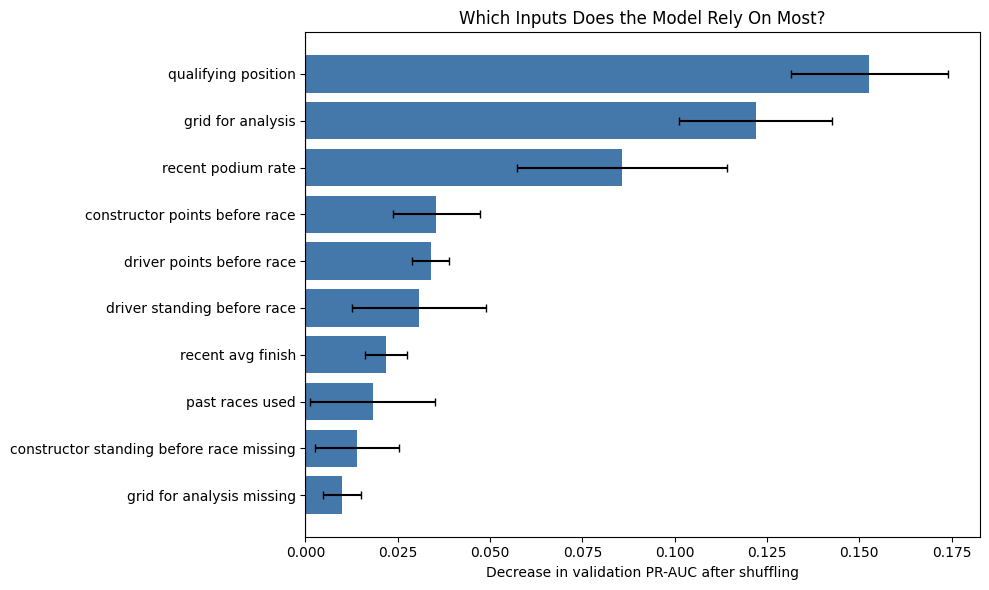

In [190]:
def permutation_score(model, inputs, target):
    return evaluate_model(model, inputs, target)["PR-AUC"]

permutation_result = permutation_importance(
    final_model,
    X_validation_final,
    y_validation,
    scoring=permutation_score,
    n_repeats=10,
    random_state=42,
    n_jobs=1
)

permutation_summary = pd.DataFrame({
    "Feature": X_validation_final.columns,
    "PR-AUC decrease": permutation_result.importances_mean,
    "Variation": permutation_result.importances_std
}).sort_values("PR-AUC decrease", ascending=False)

display(permutation_summary.round(4))

# Display the ten most important inputs
top_features = permutation_summary.head(10).sort_values(
    "PR-AUC decrease"
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top_features["Feature"].str.replace("_", " "),
    top_features["PR-AUC decrease"],
    xerr=top_features["Variation"],
    capsize=3,
    color="#4477AA"
)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Which Inputs Does the Model Rely On Most?")
ax.set_xlabel("Decrease in validation PR-AUC after shuffling")

plt.tight_layout()
plt.show()

  0%|          | 0/100 [00:00<?, ?it/s]

/tmp/ipykernel_17/2235575845.py:29: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


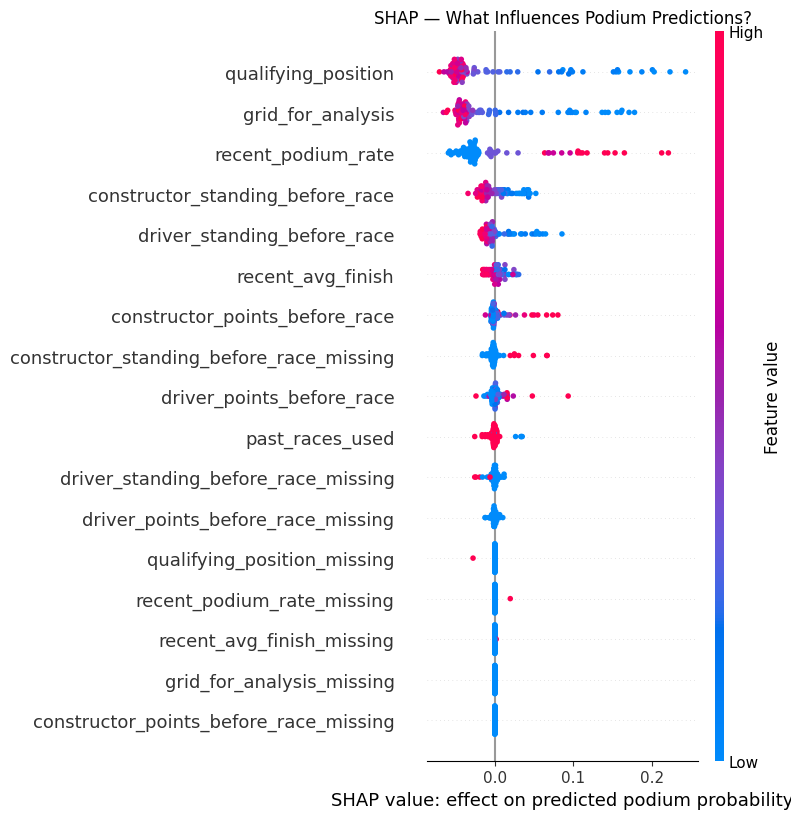

In [191]:
# Reference examples come from training data
background = X_train_xai.sample(
    n=min(50, len(X_train_xai)),
    random_state=42
)

# Explain a sample of validation appearances
explain_data = X_validation_xai.sample(
    n=min(100, len(X_validation_xai)),
    random_state=42
)

np.random.seed(42)

# KernelExplainer supports our selected neural network
shap_explainer = shap.KernelExplainer(
    lambda values: predict_for_xai(values)[:, 1],
    background,
    link="identity"
)

shap_values = shap_explainer.shap_values(
    explain_data,
    nsamples=300,
    l1_reg=0.0
)

# Use the same summary visualization as the lab
shap.summary_plot(
    shap_values,
    explain_data,
    feature_names=explain_data.columns.tolist(),
    max_display=17,
    show=False
)

plt.title("SHAP — What Influences Podium Predictions?")
plt.xlabel("SHAP value: effect on predicted podium probability")
plt.tight_layout()
plt.show()

,raceId,driverId,year
7589,1072,853,2021


Predicted podium probability: 0.045%
Decision threshold: 0.43
Predicted outcome: No podium
Actual outcome: No podium


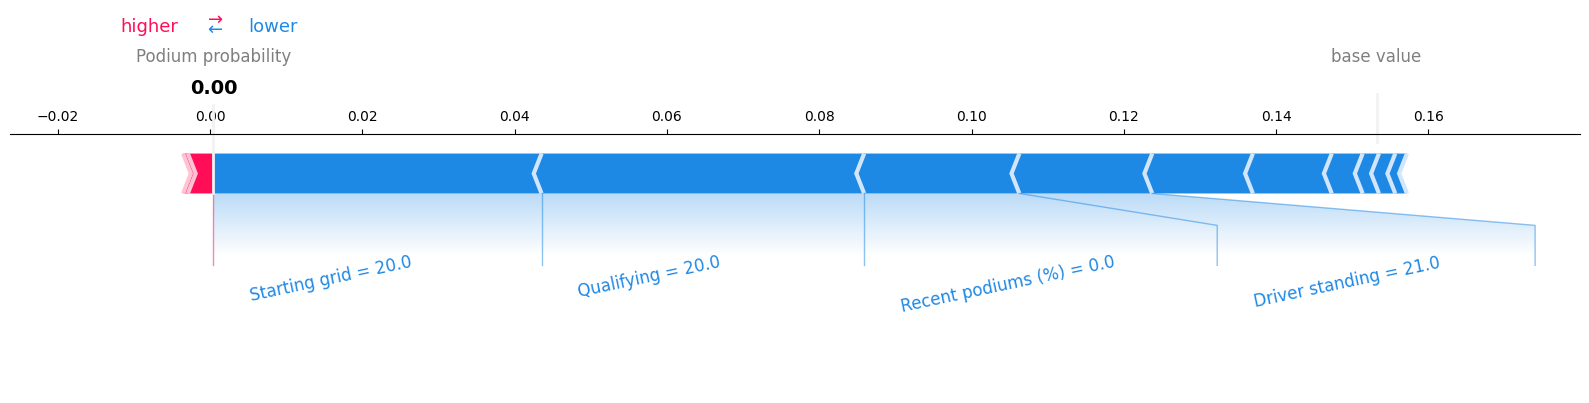

In [192]:
# Select one appearance from the explanation sample
i = 0
appearance_index = explain_data.index[i]

podium_probability = predict_for_xai(
    explain_data.iloc[[i]]
)[0, 1]

predicted_outcome = (
    "Podium"
    if podium_probability >= final_threshold
    else "No podium"
)

# Identify the selected appearance
display(
    model_features.loc[
        [appearance_index],
        ["raceId", "driverId", "year"]
    ]
)

print(f"Predicted podium probability: {podium_probability:.3%}")
print(f"Decision threshold: {final_threshold:.2f}")
print("Predicted outcome:", predicted_outcome)
print(
    "Actual outcome:",
    "Podium" if y_validation.loc[appearance_index] == 1 else "No podium"
)

# Short display labels preserve the lab's force-plot style
short_labels = {
    "grid_for_analysis": "Starting grid",
    "qualifying_position": "Qualifying",
    "recent_podium_rate": "Recent podiums (%)",
    "recent_avg_finish": "Recent avg. finish",
    "past_races_used": "Past races used",
    "driver_points_before_race": "Driver points",
    "driver_standing_before_race": "Driver standing",
    "constructor_points_before_race": "Team points",
    "constructor_standing_before_race": "Team standing"
}
display_labels = [short_labels.get(column, column.replace("_", " "))
                  for column in explain_data.columns]

# Focus labels on the main contributions; all SHAP values are retained
shap.force_plot(
    float(shap_explainer.expected_value),
    shap_values[i],
    explain_data.iloc[i],
    feature_names=display_labels,
    out_names="Podium probability",
    matplotlib=True,
    figsize=(16, 4.5),
    text_rotation=12,
    contribution_threshold=0.12,
    show=False
)

plt.tight_layout()
plt.show()

LIME local approximation R²: 0.293


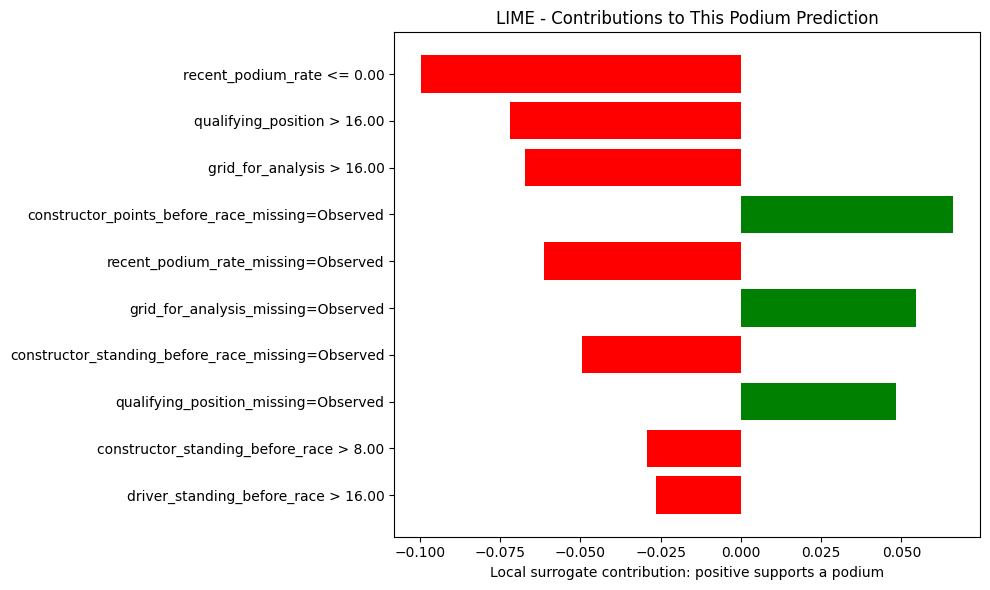

In [193]:
from IPython.display import display, HTML

# Treat missing-value flags as categories: observed or missing
flag_positions = [
    position
    for position, column in enumerate(X_train_xai.columns)
    if column.endswith("_missing")
]

flag_names = {
    position: ["Observed", "Missing"]
    for position in flag_positions
}

lime_explainer = LimeTabularExplainer(
    training_data=X_train_xai.to_numpy(),
    feature_names=X_train_xai.columns.tolist(),
    class_names=["No podium", "Podium"],
    categorical_features=flag_positions,
    categorical_names=flag_names,
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

lime_explanation = lime_explainer.explain_instance(
    data_row=explain_data.iloc[i].to_numpy(),
    predict_fn=predict_for_xai,
    labels=(1,),          # Explain the podium class
    num_features=10,
    num_samples=5000
)

# Display the same LIME explanation using the supported import
display(
    HTML(
        lime_explanation.as_html(
            labels=(1,),
            show_table=True
        )
    )
)

print(
    "LIME local approximation R²:",
    round(lime_explanation.score, 3)
)

# Static version of the same explanation for the analytical PDF report
lime_figure = lime_explanation.as_pyplot_figure(label=1)
lime_figure.set_size_inches(10, 6)
lime_axis = lime_figure.axes[0]
lime_axis.set_title("LIME - Contributions to This Podium Prediction")
lime_axis.set_xlabel("Local surrogate contribution: positive supports a podium")
lime_figure.tight_layout()
plt.show()

### Phase 6 — Model Explainability

We explained the selected neural network using permutation importance,
SHAP and LIME. The model and its settings remained unchanged.

#### Overall feature importance

Permutation importance identified qualifying position, starting grid
and recent podium rate as the most important inputs. Shuffling them
reduced validation PR-AUC by approximately 0.153, 0.122 and 0.086.

The SHAP summary plot supported the same three leading features.
Better qualifying and starting positions generally increased predicted
podium probability. A higher recent podium rate also increased it.
Driver and constructor standings provided additional information.

SHAP explanations used 100 randomly selected validation appearances,
with 50 training appearances as the reference background.

#### Explanation of one prediction

We explained Nikita Mazepin's appearance in the 2021 Saudi Arabian
Grand Prix. The model predicted approximately 0.05% podium probability,
below our 43% decision threshold. It correctly predicted no podium.

The SHAP force plot showed that qualifying 20th, starting 20th and
having no podiums in the recent-history window reduced the prediction.
His driver and constructor championship positions also contributed
toward a lower podium probability.

#### SHAP and LIME comparison

LIME agreed with SHAP that poor qualifying, a low starting position
and no recent podiums opposed a podium prediction. Their detailed
rankings differed, and LIME also assigned substantial contributions
to missing-value flags.

LIME's local R² was 0.293, indicating a weak approximation of the
neural network around this appearance. Its individual contributions
therefore require caution.

#### Limitations

These methods explain model behavior rather than causal effects.
Related features can share information, so importance rankings may
differ between methods. The local force plot uses shorter labels while retaining all SHAP contributions.